In [7]:
# Put the repository root on sys.path, wherever the kernel was started from.
import os, sys

def _find_repo_root():
    _pkgs = ("genotyping", "pipelines", "screening", "sequencing")
    for _cand in [os.getcwd(), *sys.path]:
        if not _cand:
            continue
        _d = os.path.abspath(_cand)
        while True:
            if all(os.path.isdir(os.path.join(_d, _p)) for _p in _pkgs):
                return _d
            _parent = os.path.dirname(_d)
            if _parent == _d:
                break
            _d = _parent
    return None

_repo_root = _find_repo_root()
if _repo_root and _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

import A9_07_config as config

import sys
import os
import multiprocessing as mp
import importlib

import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt

from pipelines import common_tasks

# Reload the modules
importlib.reload(config)
importlib.reload(common_tasks)

from screening import screen_utils

In [8]:
lib=config.get_library()
lib 

,Unnamed: 0,finalname,lib_section,specific_primerpart,barcode,spacer,target rv,oligofinal,length,target_site_rc_PlusTAM,target_site_PlusTAM,target_site,spacer_CG_regions,target_site_CG_regions
0,NaN,LIB-128,LIB-128,NaN,NaN,GAAGAGGACCTGGGAGATGA,TCATCTCCCAGGTCCTCTTCNNNNN,CGCGACTTTAGTCGTGTGAGGTTCAAGAAGAGGACCTGGGAGATGA...,206,TCATCTCCCAGGTCCTCTTCNNNNN,NNNNNGAAGAGGACCTGGGAGATGA,GAAGAGGACCTGGGAGATGA,GGGGCCGGGGG,GGGGCCGGGGG
1,NaN,LIB-130,LIB-130,NaN,NaN,TATTATATATGAGTTCACTG,CAGTGAACTCATATATAATANNNNN,CGCGACTTTAGTCGTGTGAGGTTCAATATTATATATGAGTTCACTG...,206,CAGTGAACTCATATATAATANNNNN,NNNNNTATTATATATGAGTTCACTG,TATTATATATGAGTTCACTG,GGCCG,GGCCG
2,NaN,LIB-132,LIB-132,NaN,NaN,ATACTGTAAAGAAGCAGAAA,TTTCTGCTTCTTTACAGTATNNNNN,CGCGACTTTAGTCGTGTGAGGTTCAAATACTGTAAAGAAGCAGAAA...,206,TTTCTGCTTCTTTACAGTATNNNNN,NNNNNATACTGTAAAGAAGCAGAAA,ATACTGTAAAGAAGCAGAAA,CGGGCG,CGGGCG


In [9]:
samples= config.get_samples()
samples 

,sample_name,sequencing_name,bioreplicate,replicate,file_name_R1,file_name_R2,editor,is_ctrl,lib_section
0,A9-07_Sample-1_TnpB-WT_ABE_LIB-130_d10_rep1,Sample-1,TnpB-WT_ABE_LIB-130_d10,1,Sample_1_MKDL250013276-1A_233KVMLT4_L8_1.fq.gz,Sample_1_MKDL250013276-1A_233KVMLT4_L8_2.fq.gz,TnpB-WT_ABE,no,LIB-130
1,A9-07_Sample-2_TnpB-pPW220_ABE_LIB-130_d10_rep1,Sample-2,TnpB-pPW220_ABE_LIB-130_d10,1,Sample_2_MKDL250013276-1A_233KVMLT4_L8_1.fq.gz,Sample_2_MKDL250013276-1A_233KVMLT4_L8_2.fq.gz,TnpB-pPW220_ABE,no,LIB-130
2,A9-07_Sample-3_TnpB-pPW221_ABE_LIB-130_d10_rep1,Sample-3,TnpB-pPW221_ABE_LIB-130_d10,1,Sample_3_MKDL250013276-1A_233KVMLT4_L8_1.fq.gz,Sample_3_MKDL250013276-1A_233KVMLT4_L8_2.fq.gz,TnpB-pPW221_ABE,no,LIB-130
3,A9-07_Sample-4_TnpB-pPW222_ABE_LIB-130_d10_rep1,Sample-4,TnpB-pPW222_ABE_LIB-130_d10,1,Sample_4_MKDL250013276-1A_233KVMLT4_L8_1.fq.gz,Sample_4_MKDL250013276-1A_233KVMLT4_L8_2.fq.gz,TnpB-pPW222_ABE,no,LIB-130
4,A9-07_Sample-5_TnpB-pPW223_ABE_LIB-130_d10_rep1,Sample-5,TnpB-pPW223_ABE_LIB-130_d10,1,Sample_5_MKDL250013276-1A_233KVMLT4_L8_1.fq.gz,Sample_5_MKDL250013276-1A_233KVMLT4_L8_2.fq.gz,TnpB-pPW223_ABE,no,LIB-130
...,...,...,...,...,...,...,...,...,...
81,A9-07_Sample-88_TnpB-pPW230_ABE_LIB-132_d10_rep3,Sample-88,TnpB-pPW230_ABE_LIB-132_d10,3,Sample_88_MKDL250013276-1A_233KVMLT4_L8_1.fq.gz,Sample_88_MKDL250013276-1A_233KVMLT4_L8_2.fq.gz,TnpB-pPW230_ABE,no,LIB-132
82,A9-07_Sample-89_Mock_LIB-130_d10_rep2,Sample-89,Mock_130_ABE_LIB-130_d10,2,Sample_89_MKDL250013276-1A_233KVMLT4_L8_1.fq.gz,Sample_89_MKDL250013276-1A_233KVMLT4_L8_2.fq.gz,NOEDITOR,yes,LIB-130
83,A9-07_Sample-90_Mock_LIB-130_d10_rep3,Sample-90,Mock_130_ABE_LIB-130_d10,3,Sample_90_MKDL250013276-1A_233KVMLT4_L8_1.fq.gz,Sample_90_MKDL250013276-1A_233KVMLT4_L8_2.fq.gz,NOEDITOR,yes,LIB-130
84,A9-07_Sample-91_Mock_LIB-132_d10_rep2,Sample-91,Mock_132_ABE_LIB-132_d10,2,Sample_91_MKDL250013276-1A_233KVMLT4_L8_1.fq.gz,Sample_91_MKDL250013276-1A_233KVMLT4_L8_2.fq.gz,NOEDITOR,yes,LIB-132


# analysis of the results

In [10]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import A9_07_config as config
import pandas as pd
import numpy as np
import os
import sys

import os, sys
_repo_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

from screening import screen_utils

# import A13_config as config

# import sys
# import os
# import multiprocessing as mp
import importlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# import os, sys
_repo_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

# # Reload the modules
importlib.reload(config)
importlib.reload(screen_utils)
# importlib.reload(common_tasks)

<module 'screening.screen_utils' from '/home/tao/code/tnpb-analysis/screening/screen_utils.py'>

In [11]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

def check_A_to_A_or_C(df):
    df['valid_diff_nt'] = df.apply(lambda row: sum(tsl == ts or (tsl == 'A' and ts in ['C', 'G']) for tsl, ts in zip(row['target_site_lib'], row['most_common_diff_target_site'])) if pd.notna(row['most_common_diff_target_site']) else 20, axis=1)
    return df

# check come quality stats

In [12]:
import pandas as pd
from pathlib import Path

# Assuming config.result_dir is a Path object
csv_files = list(config.result_dir.glob("*.csv"))

# Read and concatenate all CSV files
read_stats = pd.concat([pd.read_csv(file, header=None, index_col=0).squeeze("columns") for file in csv_files], axis=1).T.reset_index(drop=True)

print(f"Total files read: {len(csv_files)}")
read_stats

# read_stats=pd.read_excel(config.result_dir / 'read_stats.xlsx')
# read_stats

Total files read: 86


,NaN,sample_name,num_reads,r1_frac_anchor_error,r2_frac_anchor_error
0,0,A9-07_Sample-26_Mock_LIB-132_d10_rep1,1399924,0.01743594652281124,0.02093399355965038
1,0,A9-07_Sample-71_TnpB-pPW225_ABE_LIB-130_d10_rep3,661417,0.01760009192385439,0.019400771374186027
2,0,A9-07_Sample-87_TnpB-pPW229_ABE_LIB-132_d10_rep3,644872,0.017234427917478198,0.01446023396891166
3,0,A9-07_Sample-61_TnpB-pPW231_ABE_LIB-132_d10_rep2,1456679,0.017311295075991346,0.019587019514937746
4,0,A9-07_Sample-45_TnpB-pPW225_ABE_LIB-132_d10_rep2,1685672,0.017627391331172373,0.01971201989473634
...,...,...,...,...,...
81,0,A9-07_Sample-55_TnpB-pPW231_ABE_LIB-130_d10_rep2,1645696,0.017910355253947265,0.019348652485027613
82,0,A9-07_Sample-64_TnpB-pPW230_ABE_LIB-132_d10_rep4,922527,0.01815448219943698,0.01942815765825824
83,0,A9-07_Sample-54_TnpB-pPW231_ABE_LIB-130_d10_rep1,1894262,0.017590491706004765,0.019595494181903032
84,0,A9-07_Sample-69_TnpB-pPW223_ABE_LIB-130_d10_rep3,860040,0.01756081112506395,0.01929677689409795


In [13]:

def normalize_abe_editing_rate(config):
    d = pd.read_csv(config.edit_rate('all-abe-samples-not-normalized'), index_col=0)
    d,d_final = screen_utils.normalize_editing_rate(d,
        col_normalize_over=['barcode','TAM','edit_position'],
        col_rate='edit_rate',
        col_control='is_ctrl',
        ignore_control=['barcode', 'TAM'],
        th_ctrl_missing=0.05
    )
    d.drop(columns=['is_ctrl'])
    d.to_csv(config.edit_rate('all-abe-samples-normalized'))
    d_final.to_csv(config.edit_rate('all-abe-samples-normalized-PlusCtrl'))

def aggregate_abe_replicates(config):
    print("aggregating ABE replicates")
    d = pd.read_csv(config.edit_rate('all-abe-samples-normalized'), index_col=0)
    d=d.loc[~d["edit_rate"].isna(),:]
    # Group by the specified columns and filter groups with exactly all replicates
    d = d.groupby(['editor', 'barcode', 'TAM', 'edit_position']).filter(lambda x: len(x) == 3)
    d = screen_utils.aggregate_replicates(d,
        cols_group=['editor','barcode','TAM','edit_position'], # here editor and barcoe(library) combination is a biological replicate, PAM/TAM is not consider here ?
        col_rate='edit_rate'                             # PAM/TAM is not consider here ?
    ).drop(columns=['sample_name', 'replicate'])
    d.to_csv(config.edit_rate('all-abe-editors'))

    d_plusctrl = pd.read_csv(config.edit_rate('all-abe-samples-normalized-PlusCtrl'), index_col=0)
    d_plusctrl=d_plusctrl.loc[~d_plusctrl["edit_rate"].isna(),:]
    # Group by the specified columns and filter groups with exactly all replicates
    d_plusctrl = d_plusctrl.groupby(['editor', 'barcode', 'TAM', 'edit_position']).filter(lambda x: len(x) == 3)
    d_plusctrl = screen_utils.aggregate_replicates(d_plusctrl,
        cols_group=['editor','barcode','TAM','edit_position'], # here editor and barcoe(library) combination is a biological replicate, PAM/TAM is not consider here ?
        col_rate='edit_rate'                             # PAM/TAM is not consider here ?
    ).drop(columns=['sample_name', 'replicate'])

    d_plusctrl.to_csv(config.edit_rate('all-abe-editors-PlusCtrl'))

In [14]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import warnings

## check reads level quality

In [15]:
def get_abe_samples(config,sample_name_column='sample_name',editor_column='editor'):
    samples = config.get_samples()
    return samples.loc[samples[editor_column].str.contains('ABE'),:]

def collect_abe_read_edit_rates(config,sample_name_column='sample_name',editor_column='editor',control_column='control_yes_no'):
    """ Collect edit rates for all samples"""
    print('Collecting ABE edit rates for all samples')
    #samples = get_abe_samples(config,sample_name_column,editor_column)
    samples=config.get_samples()
    all_sample_rates = pd.concat(
        [
            pd.read_csv(config.edit_rate(f'{sample[sample_name_column]}-reads-editedrates-unfiltered'), index_col=0).assign(
                editor=sample[editor_column],
                sample_name=sample[sample_name_column],
                is_ctrl=sample[control_column],
                replicate=sample["replicate"],
            )
            for _,sample in samples.iterrows()
        ]
    ).reset_index(drop=True)
    all_sample_rates.loc[:, 'is_ctrl'] = all_sample_rates.is_ctrl == 'yes'
    return all_sample_rates
    #all_sample_rates.to_csv(config.edit_rate('all-abe-samples-reads-editedrates-unfiltered-not-normalized'))
    

In [16]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_unfiltered_not_normalized=collect_abe_read_edit_rates(config,sample_name_column='sample_name',
                                                                                        editor_column='editor',control_column="is_ctrl")
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)

all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(88624, 11)


,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate
0,TATTATATATGAGTTCACTG,AAAAA,0.079545,264,ATTATATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,A9-07_Sample-1_TnpB-WT_ABE_LIB-130_d10_rep1,False,1
1,TATTATATATGAGTTCACTG,AAAAC,0.028708,209,ATACTGTAAAGAAGCAGAAA,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,A9-07_Sample-1_TnpB-WT_ABE_LIB-130_d10_rep1,False,1
2,TATTATATATGAGTTCACTG,AAAAG,0.018462,650,CATTAATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,A9-07_Sample-1_TnpB-WT_ABE_LIB-130_d10_rep1,False,1


In [17]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_unfiltered_not_normalized=all_abe_samples_reads_editedrates_unfiltered_not_normalized[all_abe_samples_reads_editedrates_unfiltered_not_normalized["TAM"].str.match("^[ATCG]+$")]
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)
all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(88064, 11)


,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate
0,TATTATATATGAGTTCACTG,AAAAA,0.079545,264,ATTATATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,A9-07_Sample-1_TnpB-WT_ABE_LIB-130_d10_rep1,False,1
1,TATTATATATGAGTTCACTG,AAAAC,0.028708,209,ATACTGTAAAGAAGCAGAAA,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,A9-07_Sample-1_TnpB-WT_ABE_LIB-130_d10_rep1,False,1
2,TATTATATATGAGTTCACTG,AAAAG,0.018462,650,CATTAATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,A9-07_Sample-1_TnpB-WT_ABE_LIB-130_d10_rep1,False,1


In [18]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"] = all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"].str.split("Sample-").str[-1]
all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"] = all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"].apply(lambda x: "_".join(x.split("_")[1:]))
all_abe_samples_reads_editedrates_unfiltered_not_normalized["bioreplicate"]=all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"].apply(lambda x:x.split("_rep")[0])
all_abe_samples_reads_editedrates_unfiltered_not_normalized["lib_section"]=all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"].apply(lambda x:x.split("_")[2] if len(x.split("_"))==5 else x.split("_")[1])
all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section
0,TATTATATATGAGTTCACTG,AAAAA,0.079545,264,ATTATATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130
1,TATTATATATGAGTTCACTG,AAAAC,0.028708,209,ATACTGTAAAGAAGCAGAAA,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130
2,TATTATATATGAGTTCACTG,AAAAG,0.018462,650,CATTAATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130


In [19]:
lib=config.get_library()
lib

,Unnamed: 0,finalname,lib_section,specific_primerpart,barcode,spacer,target rv,oligofinal,length,target_site_rc_PlusTAM,target_site_PlusTAM,target_site,spacer_CG_regions,target_site_CG_regions
0,NaN,LIB-128,LIB-128,NaN,NaN,GAAGAGGACCTGGGAGATGA,TCATCTCCCAGGTCCTCTTCNNNNN,CGCGACTTTAGTCGTGTGAGGTTCAAGAAGAGGACCTGGGAGATGA...,206,TCATCTCCCAGGTCCTCTTCNNNNN,NNNNNGAAGAGGACCTGGGAGATGA,GAAGAGGACCTGGGAGATGA,GGGGCCGGGGG,GGGGCCGGGGG
1,NaN,LIB-130,LIB-130,NaN,NaN,TATTATATATGAGTTCACTG,CAGTGAACTCATATATAATANNNNN,CGCGACTTTAGTCGTGTGAGGTTCAATATTATATATGAGTTCACTG...,206,CAGTGAACTCATATATAATANNNNN,NNNNNTATTATATATGAGTTCACTG,TATTATATATGAGTTCACTG,GGCCG,GGCCG
2,NaN,LIB-132,LIB-132,NaN,NaN,ATACTGTAAAGAAGCAGAAA,TTTCTGCTTCTTTACAGTATNNNNN,CGCGACTTTAGTCGTGTGAGGTTCAAATACTGTAAAGAAGCAGAAA...,206,TTTCTGCTTCTTTACAGTATNNNNN,NNNNNATACTGTAAAGAAGCAGAAA,ATACTGTAAAGAAGCAGAAA,CGGGCG,CGGGCG


In [20]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_unfiltered_not_normalized=all_abe_samples_reads_editedrates_unfiltered_not_normalized.merge(lib[['lib_section','spacer']], on='lib_section', how='left',suffixes=('', '_LIB'))
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)
all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(88064, 14)


,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
0,TATTATATATGAGTTCACTG,AAAAA,0.079545,264,ATTATATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130,TATTATATATGAGTTCACTG
1,TATTATATATGAGTTCACTG,AAAAC,0.028708,209,ATACTGTAAAGAAGCAGAAA,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130,TATTATATATGAGTTCACTG
2,TATTATATATGAGTTCACTG,AAAAG,0.018462,650,CATTAATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130,TATTATATATGAGTTCACTG


In [21]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

# for A09. each target are screeen separately, so remove the weired spacers

all_abe_samples_reads_editedrates_unfiltered_not_normalized = all_abe_samples_reads_editedrates_unfiltered_not_normalized[all_abe_samples_reads_editedrates_unfiltered_not_normalized["spacer"] == all_abe_samples_reads_editedrates_unfiltered_not_normalized["spacer_LIB"]]
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)
all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(88064, 14)


,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
0,TATTATATATGAGTTCACTG,AAAAA,0.079545,264,ATTATATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130,TATTATATATGAGTTCACTG
1,TATTATATATGAGTTCACTG,AAAAC,0.028708,209,ATACTGTAAAGAAGCAGAAA,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130,TATTATATATGAGTTCACTG
2,TATTATATATGAGTTCACTG,AAAAG,0.018462,650,CATTAATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130,TATTATATATGAGTTCACTG


In [22]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_not_normalized=all_abe_samples_reads_editedrates_unfiltered_not_normalized.\
    loc[all_abe_samples_reads_editedrates_unfiltered_not_normalized['num_reads'] >= 100]     # 100,
print(all_abe_samples_reads_editedrates_not_normalized.shape)
all_abe_samples_reads_editedrates_not_normalized.head(n=3)

(87426, 14)


,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
0,TATTATATATGAGTTCACTG,AAAAA,0.079545,264,ATTATATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130,TATTATATATGAGTTCACTG
1,TATTATATATGAGTTCACTG,AAAAC,0.028708,209,ATACTGTAAAGAAGCAGAAA,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130,TATTATATATGAGTTCACTG
2,TATTATATATGAGTTCACTG,AAAAG,0.018462,650,CATTAATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130,TATTATATATGAGTTCACTG


In [23]:
# Print unique replicates for each bioreplicate
for bioreplicate, group in all_abe_samples_reads_editedrates_not_normalized.groupby('bioreplicate'):
    unique_replicates = sorted(group['replicate'].unique())
    print(f"{bioreplicate}: {unique_replicates}")

Mock_LIB-130_d10: [np.int64(1), np.int64(2), np.int64(3)]
Mock_LIB-132_d10: [np.int64(1), np.int64(2), np.int64(3)]
TnpB-WT_ABE_LIB-130_d10: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
TnpB-WT_ABE_LIB-132_d10: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
TnpB-pPW220_ABE_LIB-130_d10: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
TnpB-pPW220_ABE_LIB-132_d10: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
TnpB-pPW221_ABE_LIB-130_d10: [np.int64(1), np.int64(2), np.int64(3)]
TnpB-pPW221_ABE_LIB-132_d10: [np.int64(1), np.int64(2), np.int64(3)]
TnpB-pPW222_ABE_LIB-130_d10: [np.int64(1), np.int64(2), np.int64(3)]
TnpB-pPW222_ABE_LIB-132_d10: [np.int64(1), np.int64(2), np.int64(3)]
TnpB-pPW223_ABE_LIB-130_d10: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
TnpB-pPW223_ABE_LIB-132_d10: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
TnpB-pPW224_ABE_LIB-130_d10: [np.int64(1), np.int64(2)]
TnpB-pPW224_ABE_LIB-132_d10: [np.int64(1), np.int64(2)]
TnpB-pPW225_

In [24]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_not_normalized_pivot_df = all_abe_samples_reads_editedrates_not_normalized.pivot_table(index=['spacer', 'TAM', "target_site_lib"],
                                           columns='sample_name',
                                           values=['frac_reads_edited','num_reads'],  # values='edit_rate',
                                            aggfunc='first'
                                           ).reset_index()

all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns = ['_'.join(col).strip() for col in all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns.values]

print(all_abe_samples_reads_editedrates_not_normalized_pivot_df.shape)
all_abe_samples_reads_editedrates_not_normalized_pivot_df

(2048, 175)


,spacer_,TAM_,target_site_lib_,frac_reads_edited_Mock_LIB-130_d10_rep1,frac_reads_edited_Mock_LIB-130_d10_rep2,frac_reads_edited_Mock_LIB-130_d10_rep3,frac_reads_edited_Mock_LIB-132_d10_rep1,frac_reads_edited_Mock_LIB-132_d10_rep2,frac_reads_edited_Mock_LIB-132_d10_rep3,frac_reads_edited_TnpB-WT_ABE_LIB-130_d10_rep1,...,num_reads_TnpB-pPW230_ABE_LIB-130_d10_rep3,num_reads_TnpB-pPW230_ABE_LIB-130_d10_rep4,num_reads_TnpB-pPW230_ABE_LIB-132_d10_rep1,num_reads_TnpB-pPW230_ABE_LIB-132_d10_rep2,num_reads_TnpB-pPW230_ABE_LIB-132_d10_rep3,num_reads_TnpB-pPW230_ABE_LIB-132_d10_rep4,num_reads_TnpB-pPW231_ABE_LIB-130_d10_rep1,num_reads_TnpB-pPW231_ABE_LIB-130_d10_rep2,num_reads_TnpB-pPW231_ABE_LIB-132_d10_rep1,num_reads_TnpB-pPW231_ABE_LIB-132_d10_rep2
0,ATACTGTAAAGAAGCAGAAA,AAAAA,ATACTGTAAAGAAGCAGAAA,NaN,NaN,NaN,0.043956,0.120245,0.283088,NaN,...,NaN,NaN,1378.0,911.0,844.0,641.0,NaN,NaN,886.0,1612.0
1,ATACTGTAAAGAAGCAGAAA,AAAAC,ATACTGTAAAGAAGCAGAAA,NaN,NaN,NaN,0.024096,0.106227,0.235585,NaN,...,NaN,NaN,306.0,345.0,153.0,308.0,NaN,NaN,300.0,1025.0
2,ATACTGTAAAGAAGCAGAAA,AAAAG,ATACTGTAAAGAAGCAGAAA,NaN,NaN,NaN,0.055911,0.039867,0.034325,NaN,...,NaN,NaN,780.0,652.0,311.0,1564.0,NaN,NaN,1228.0,527.0
3,ATACTGTAAAGAAGCAGAAA,AAAAT,ATACTGTAAAGAAGCAGAAA,NaN,NaN,NaN,0.022535,0.051040,0.044146,NaN,...,NaN,NaN,1100.0,1894.0,353.0,572.0,NaN,NaN,1301.0,869.0
4,ATACTGTAAAGAAGCAGAAA,AAACA,ATACTGTAAAGAAGCAGAAA,NaN,NaN,NaN,0.110776,0.033149,0.020428,NaN,...,NaN,NaN,906.0,1312.0,895.0,328.0,NaN,NaN,1602.0,3949.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2043,TATTATATATGAGTTCACTG,TTTGT,TATTATATATGAGTTCACTG,0.248144,0.065711,0.037578,NaN,NaN,NaN,0.022026,...,205.0,424.0,NaN,NaN,NaN,NaN,758.0,1272.0,NaN,NaN
2044,TATTATATATGAGTTCACTG,TTTTA,TATTATATATGAGTTCACTG,0.015656,0.027439,0.017408,NaN,NaN,NaN,0.016492,...,252.0,783.0,NaN,NaN,NaN,NaN,1312.0,837.0,NaN,NaN
2045,TATTATATATGAGTTCACTG,TTTTC,TATTATATATGAGTTCACTG,0.009950,0.009639,0.022222,NaN,NaN,NaN,0.104348,...,109.0,401.0,NaN,NaN,NaN,NaN,499.0,316.0,NaN,NaN
2046,TATTATATATGAGTTCACTG,TTTTG,TATTATATATGAGTTCACTG,0.016719,0.095087,0.156319,NaN,NaN,NaN,0.022807,...,227.0,596.0,NaN,NaN,NaN,NaN,1795.0,1810.0,NaN,NaN


In [25]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

editor_columns=sorted([l for l in all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns if "frac_reads" in l])

all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim=all_abe_samples_reads_editedrates_not_normalized_pivot_df.loc[:,list(editor_columns)]
print(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.shape)
all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim

(2048, 86)


,frac_reads_edited_Mock_LIB-130_d10_rep1,frac_reads_edited_Mock_LIB-130_d10_rep2,frac_reads_edited_Mock_LIB-130_d10_rep3,frac_reads_edited_Mock_LIB-132_d10_rep1,frac_reads_edited_Mock_LIB-132_d10_rep2,frac_reads_edited_Mock_LIB-132_d10_rep3,frac_reads_edited_TnpB-WT_ABE_LIB-130_d10_rep1,frac_reads_edited_TnpB-WT_ABE_LIB-130_d10_rep2,frac_reads_edited_TnpB-WT_ABE_LIB-130_d10_rep3,frac_reads_edited_TnpB-WT_ABE_LIB-130_d10_rep4,...,frac_reads_edited_TnpB-pPW230_ABE_LIB-130_d10_rep3,frac_reads_edited_TnpB-pPW230_ABE_LIB-130_d10_rep4,frac_reads_edited_TnpB-pPW230_ABE_LIB-132_d10_rep1,frac_reads_edited_TnpB-pPW230_ABE_LIB-132_d10_rep2,frac_reads_edited_TnpB-pPW230_ABE_LIB-132_d10_rep3,frac_reads_edited_TnpB-pPW230_ABE_LIB-132_d10_rep4,frac_reads_edited_TnpB-pPW231_ABE_LIB-130_d10_rep1,frac_reads_edited_TnpB-pPW231_ABE_LIB-130_d10_rep2,frac_reads_edited_TnpB-pPW231_ABE_LIB-132_d10_rep1,frac_reads_edited_TnpB-pPW231_ABE_LIB-132_d10_rep2
0,NaN,NaN,NaN,0.043956,0.120245,0.283088,NaN,NaN,NaN,NaN,...,NaN,NaN,0.035559,0.026345,0.041469,0.057722,NaN,NaN,0.037246,0.036600
1,NaN,NaN,NaN,0.024096,0.106227,0.235585,NaN,NaN,NaN,NaN,...,NaN,NaN,0.006536,0.046377,0.045752,0.022727,NaN,NaN,0.046667,0.016585
2,NaN,NaN,NaN,0.055911,0.039867,0.034325,NaN,NaN,NaN,NaN,...,NaN,NaN,0.038462,0.019939,0.109325,0.017263,NaN,NaN,0.022801,0.032258
3,NaN,NaN,NaN,0.022535,0.051040,0.044146,NaN,NaN,NaN,NaN,...,NaN,NaN,0.014545,0.011616,0.022663,0.026224,NaN,NaN,0.080707,0.100115
4,NaN,NaN,NaN,0.110776,0.033149,0.020428,NaN,NaN,NaN,NaN,...,NaN,NaN,0.114790,0.032774,0.020112,0.109756,NaN,NaN,0.041823,0.365662
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2043,0.248144,0.065711,0.037578,NaN,NaN,NaN,0.022026,0.073222,0.043571,0.017241,...,0.039024,0.155660,NaN,NaN,NaN,NaN,0.054090,0.048742,NaN,NaN
2044,0.015656,0.027439,0.017408,NaN,NaN,NaN,0.016492,0.028494,0.022758,0.030558,...,0.039683,0.325670,NaN,NaN,NaN,NaN,0.148628,0.015532,NaN,NaN
2045,0.009950,0.009639,0.022222,NaN,NaN,NaN,0.104348,0.080087,0.010288,0.006079,...,0.009174,0.002494,NaN,NaN,NaN,NaN,0.004008,0.034810,NaN,NaN
2046,0.016719,0.095087,0.156319,NaN,NaN,NaN,0.022807,0.052516,0.183724,0.015326,...,0.030837,0.015101,NaN,NaN,NaN,NaN,0.018384,0.007735,NaN,NaN




In [26]:
from scipy.stats import pearsonr, spearmanr

import matplotlib.pyplot as plt

def plot_paired_correlations(df,corr_edit_thres=0.3):
    """df have edit rate for different editor in different replicate, each column is one replice .
    column name are like this "frac_reads_edited_Mock_130_ABE_LIB-130_d10_rep1", "frac_reads_edited_Mock_130_ABE_LIB-130_d10_rep1"
    now i want to draw scatter plot between different replicates, for each editor, the plot in in row
    and show pearsonand spearman correlation in the figure legened

    for corr_edit_thres, only plot the replicates pair with correlation higher than this thres
    since editors have no/low editing for most of pams

    """
    # Extract editor names from column names
    editors = {}
    for col in df.columns:
        if col.startswith('frac_reads_edited_'):
            # Extract editor name (everything between 'frac_reads_edited_' and the last '_rep')
            editor_part = col.replace('frac_reads_edited_', '')
            editor_name = '_'.join(editor_part.split('_')[:-1])  # Remove the last _repX part
            if editor_name not in editors:
                editors[editor_name] = []
            editors[editor_name].append(col)

    # Create subplots - each row for one editor, columns for pairwise comparisons
    n_editors = len(editors)
    max_pairs = max(len(cols) * (len(cols) - 1) // 2 for cols in editors.values() if len(cols) > 1)

    fig, axes = plt.subplots(n_editors, max_pairs, figsize=(5*max_pairs, 5*n_editors))
    if n_editors == 1:
        axes = axes.reshape(1, -1)
    elif max_pairs == 1:
        axes = axes.reshape(-1, 1)

    for row_idx, (editor, columns) in enumerate(editors.items()):
        if len(columns) < 2:
            continue

        # Get all pairs of replicates
        pair_idx = 0
        for i in range(len(columns)):
            for j in range(i+1, len(columns)):
                col1, col2 = columns[i], columns[j]

                # Get data for correlation (remove NaN values)
                mask = ~(df[col1].isna() | df[col2].isna())
                x_data = df[col1][mask]
                y_data = df[col2][mask]

                #for x_data and y data. filter to get ones that both x_data and y_data > corr_edit_thres
                mask_corr_thres = (x_data > corr_edit_thres) & (y_data > corr_edit_thres) # (x_data > corr_edit_thres) | (y_data > corr_edit_thres)
                x_data = x_data[mask_corr_thres]
                y_data = y_data[mask_corr_thres]

                if len(x_data) > 0:
                    # Calculate correlations
                    pearson_r, pearson_p = pearsonr(x_data, y_data)
                    spearman_r, spearman_p = spearmanr(x_data, y_data)

                    # Plot scatter
                    ax = axes[row_idx, pair_idx]
                    ax.scatter(x_data, y_data, alpha=0.6, s=20)

                    # Extract replicate numbers
                    rep1 = col1.split('_rep')[-1]
                    rep2 = col2.split('_rep')[-1]

                    ax.set_xlabel(f'Replicate {rep1}')
                    ax.set_ylabel(f'Replicate {rep2}')
                    ax.set_title(f'{editor}\nrep{rep1} vs rep{rep2}\npearson={pearson_r:.3f}, spearman={spearman_r:.3f}')
                    ax.grid(True, alpha=0.3)

                    # Add diagonal line
                    max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
                    min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
                    ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)

                    pair_idx += 1

        # Hide unused subplots in this row
        for col_idx in range(pair_idx, max_pairs):
            axes[row_idx, col_idx].set_visible(False)

    plt.tight_layout()
    plt.show()

plot_paired_correlations(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim,
                         corr_edit_thres=0.2)

# here is correlatoin plot is meaningless, since most TAMs have low editing 

/tmp/ipykernel_1234884/1467041687.py:25: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=figsize)


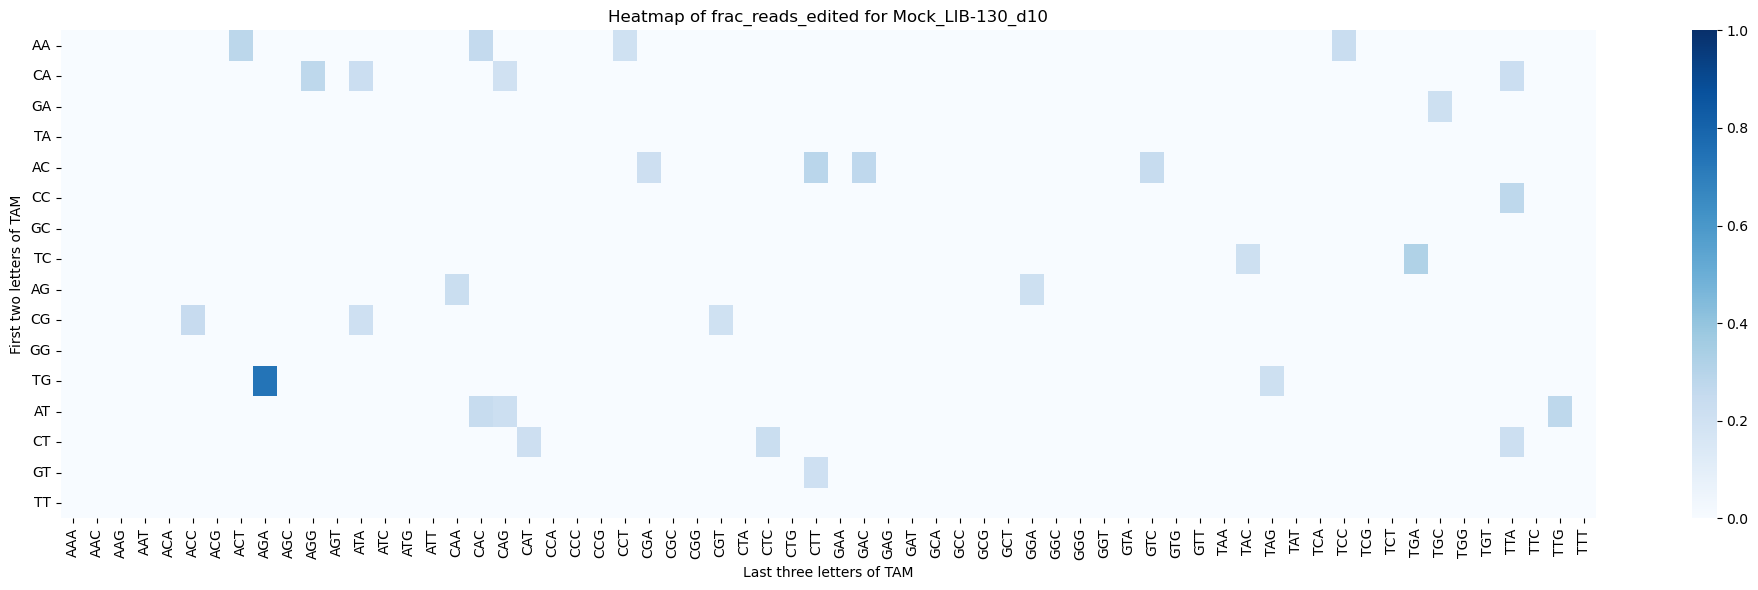

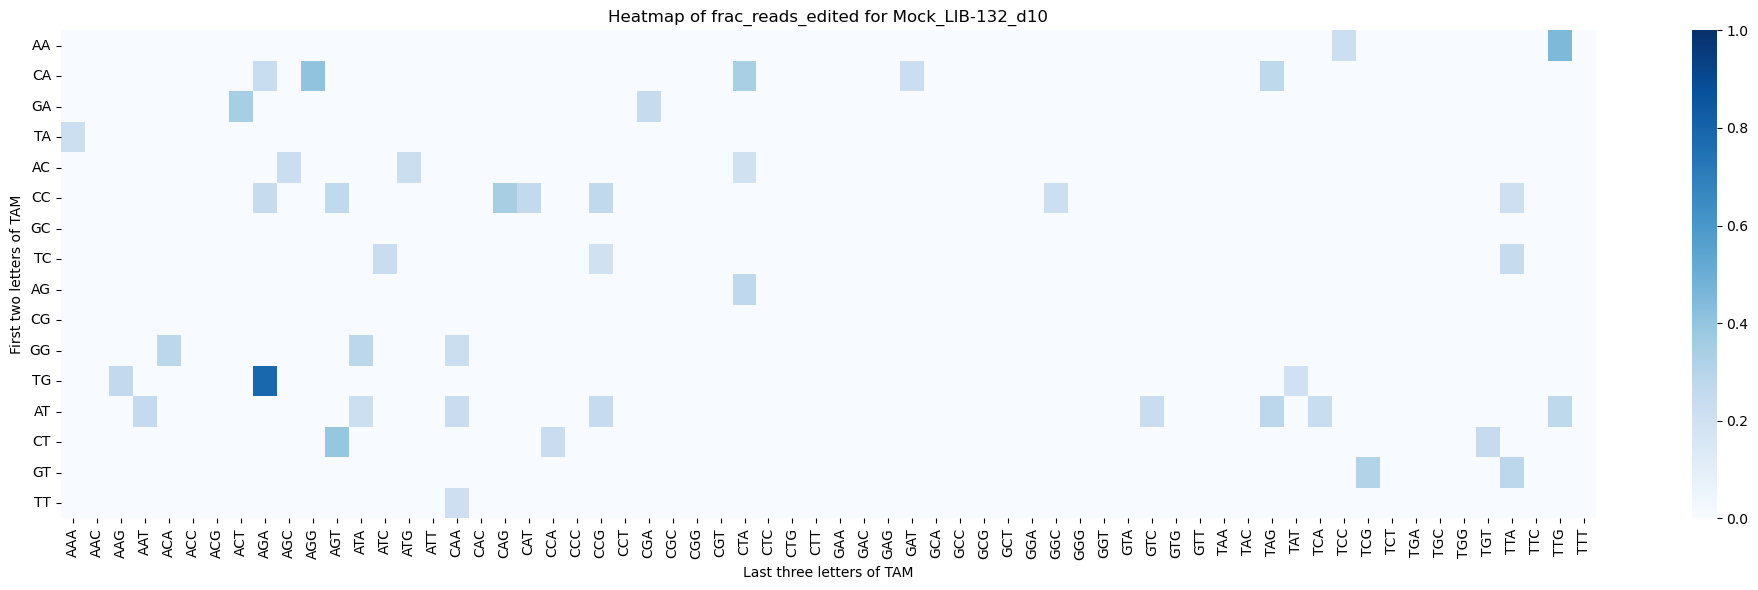

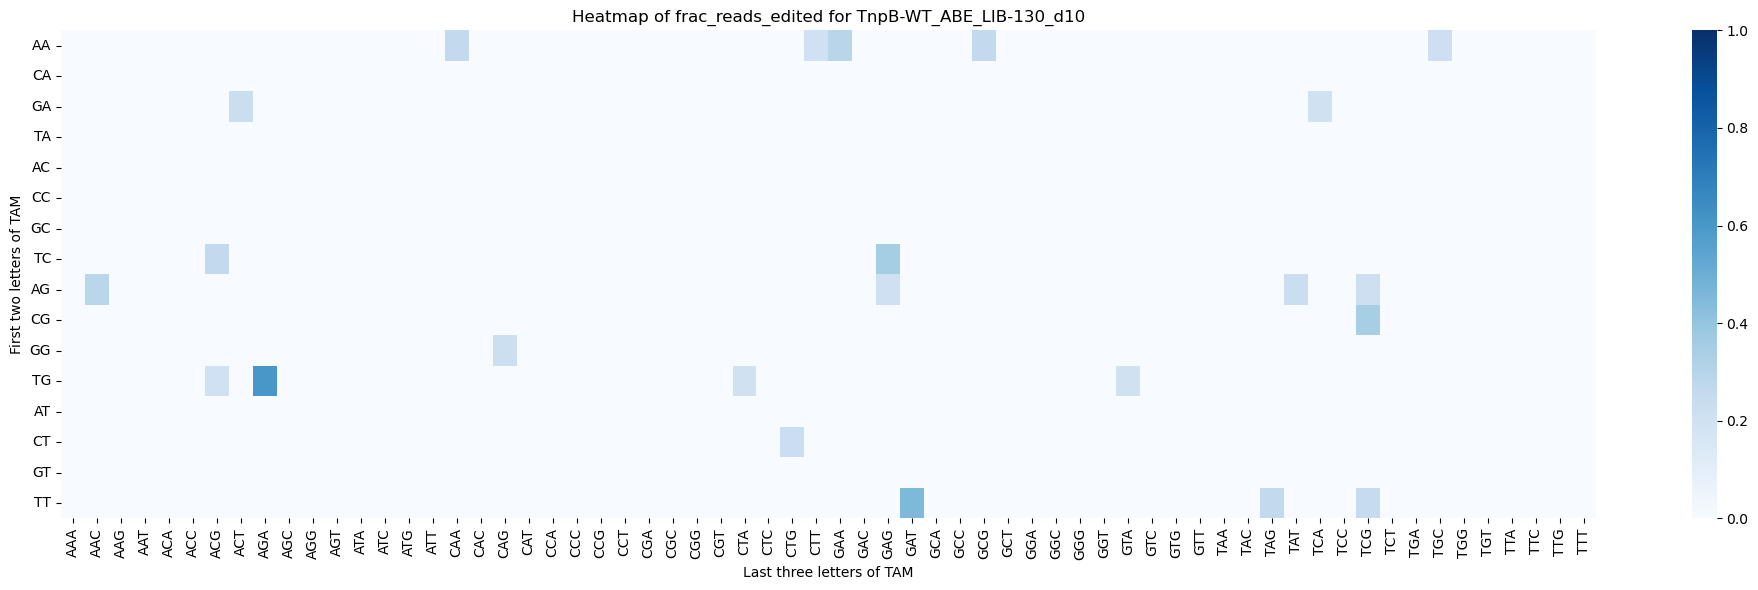

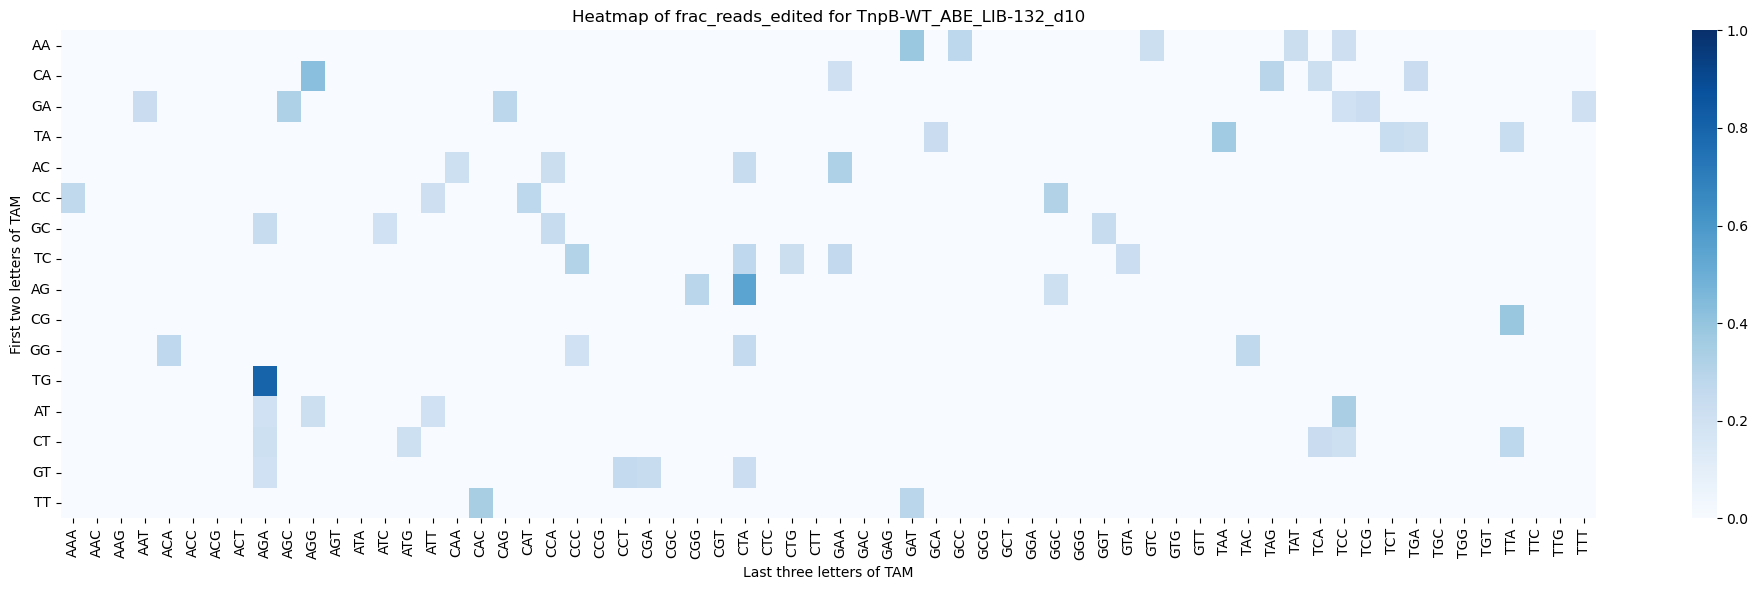

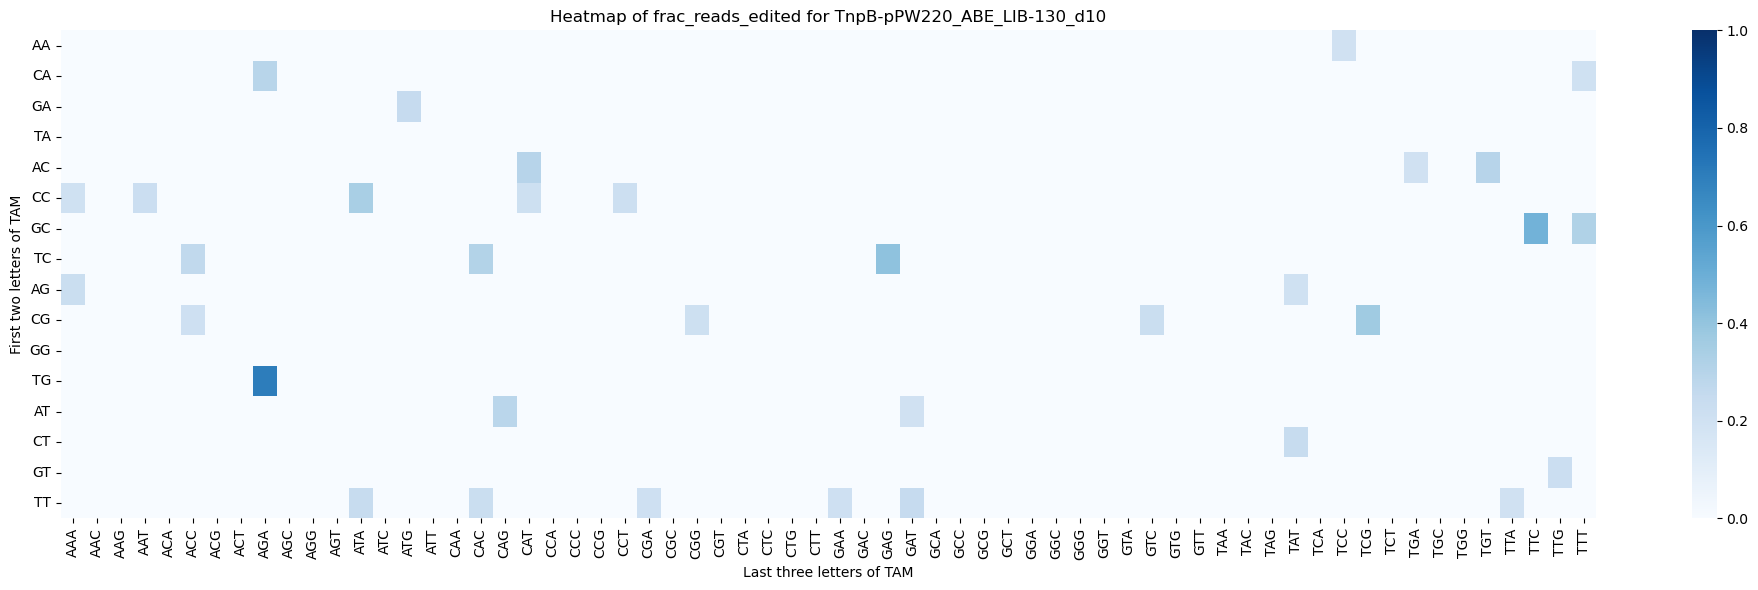

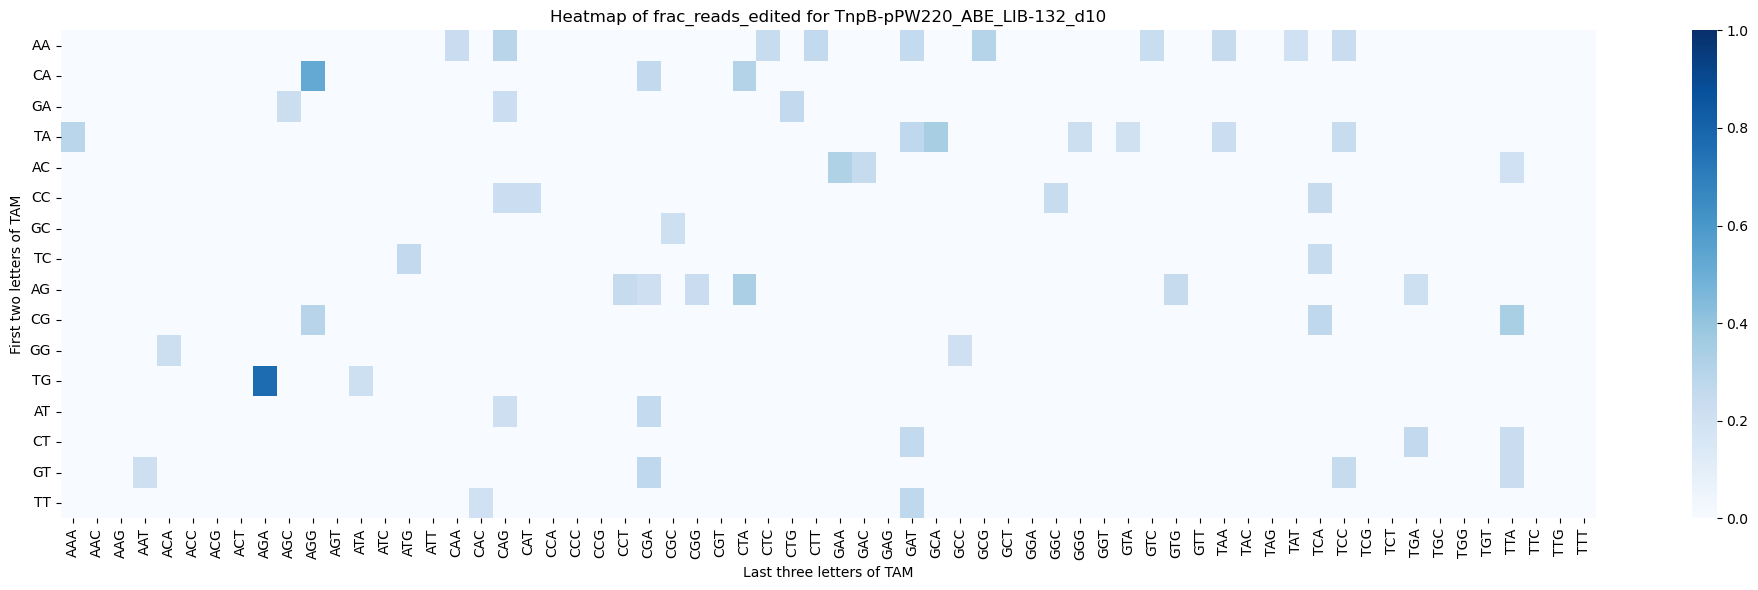

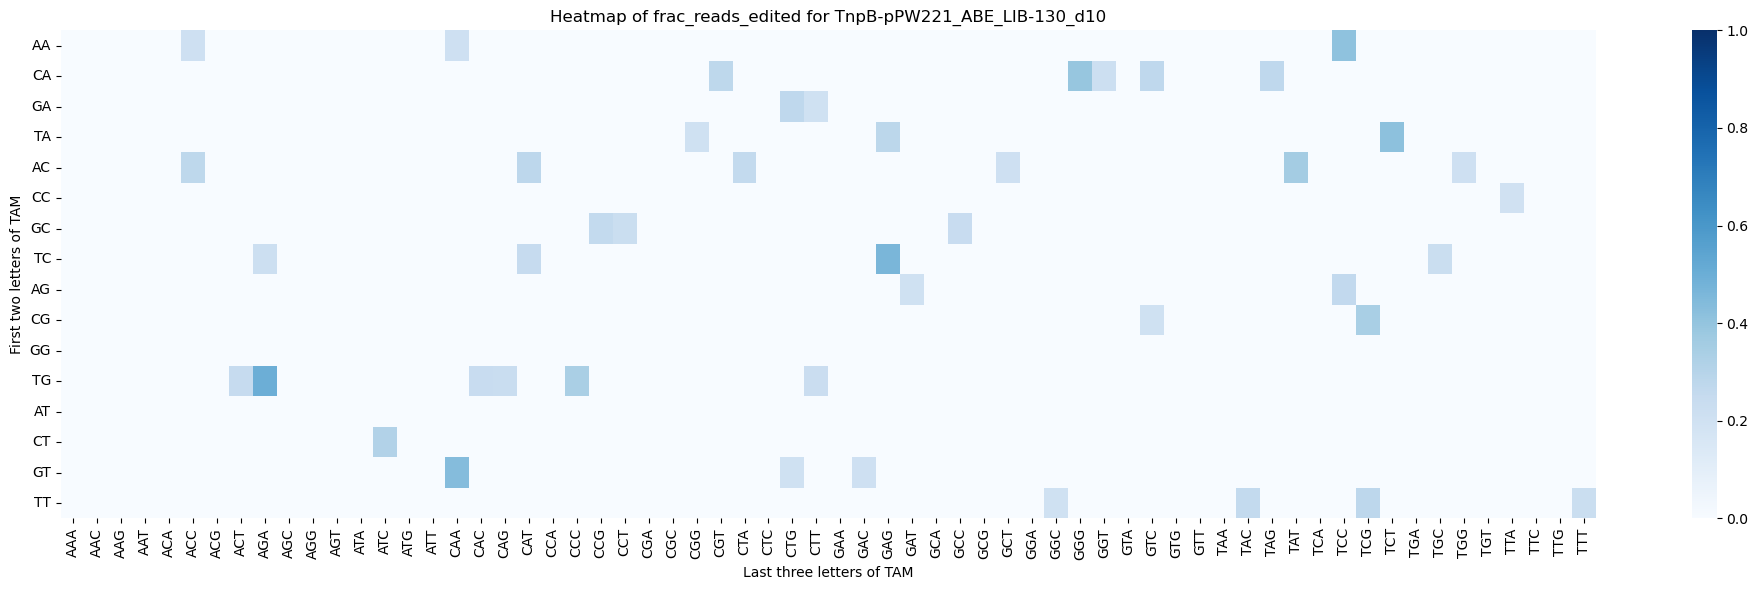

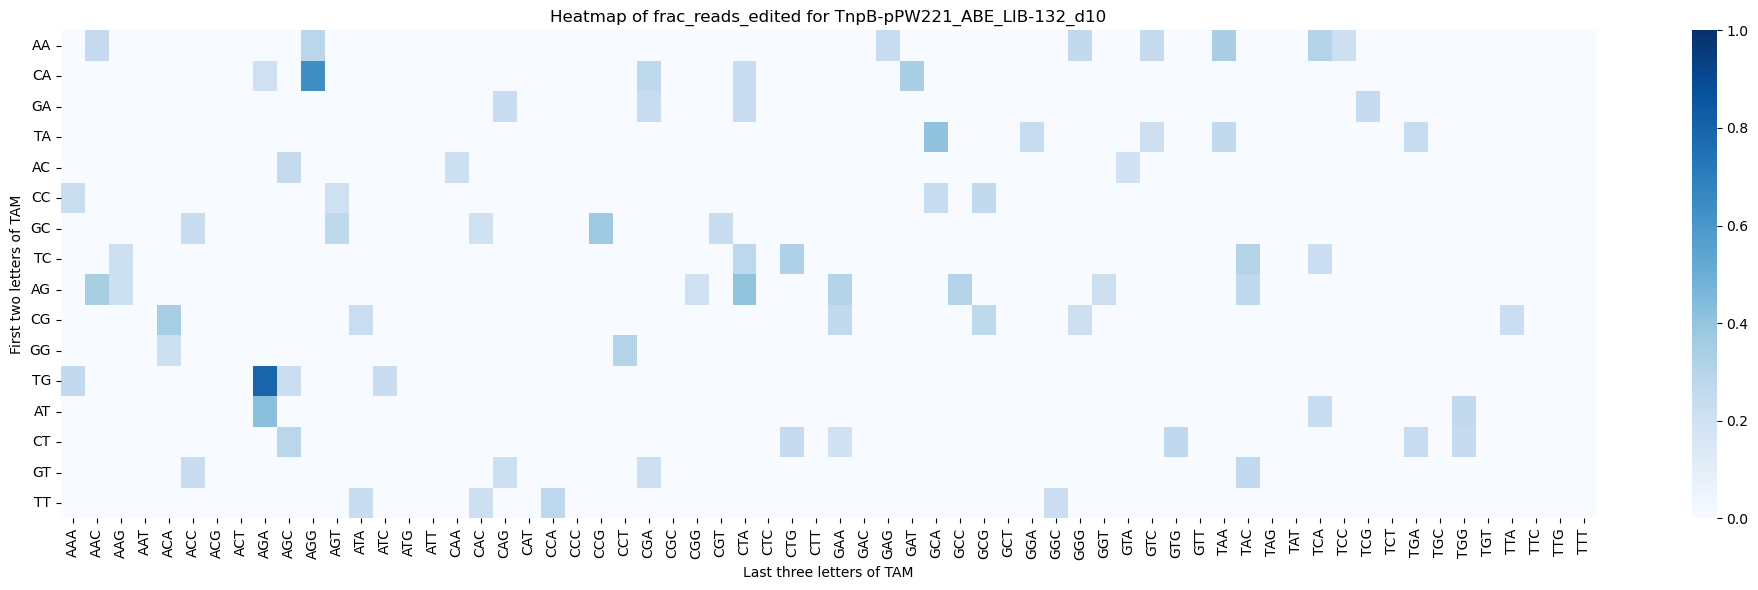

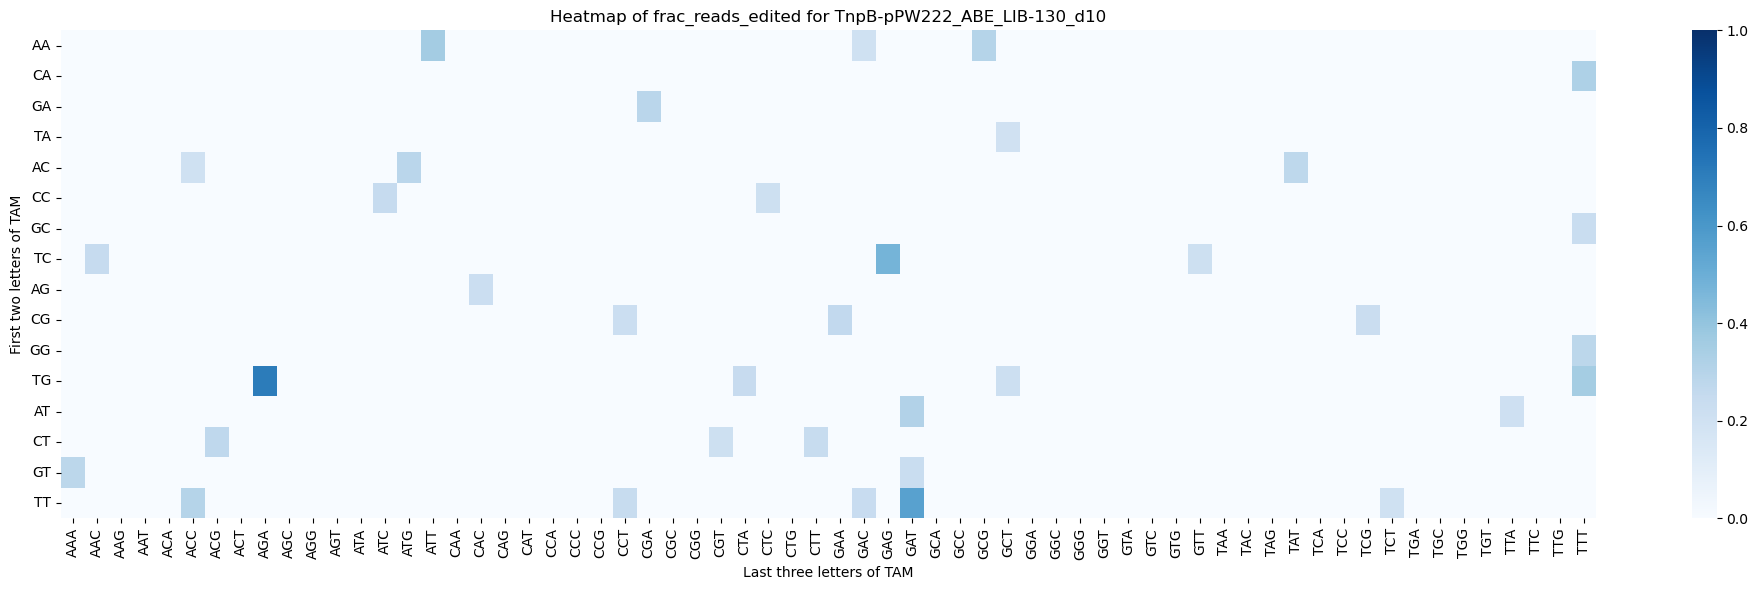

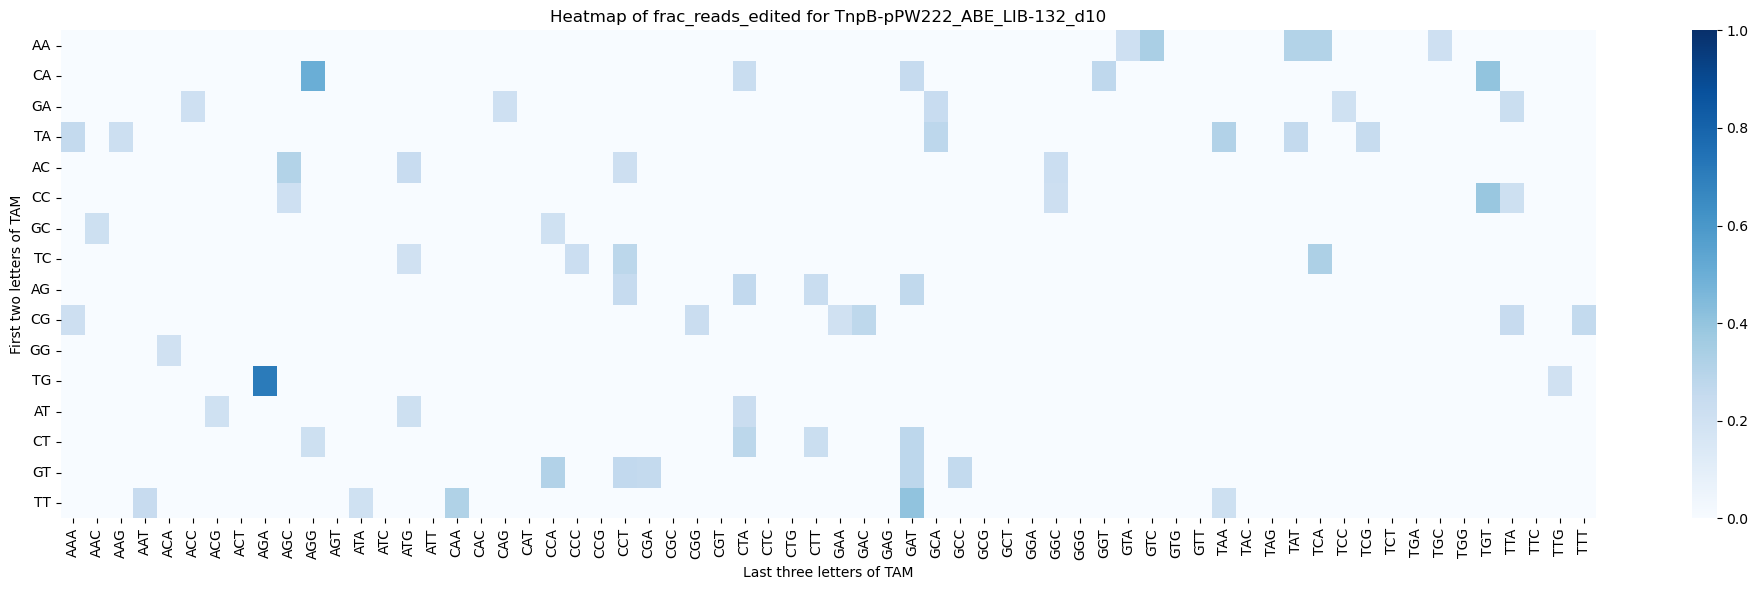

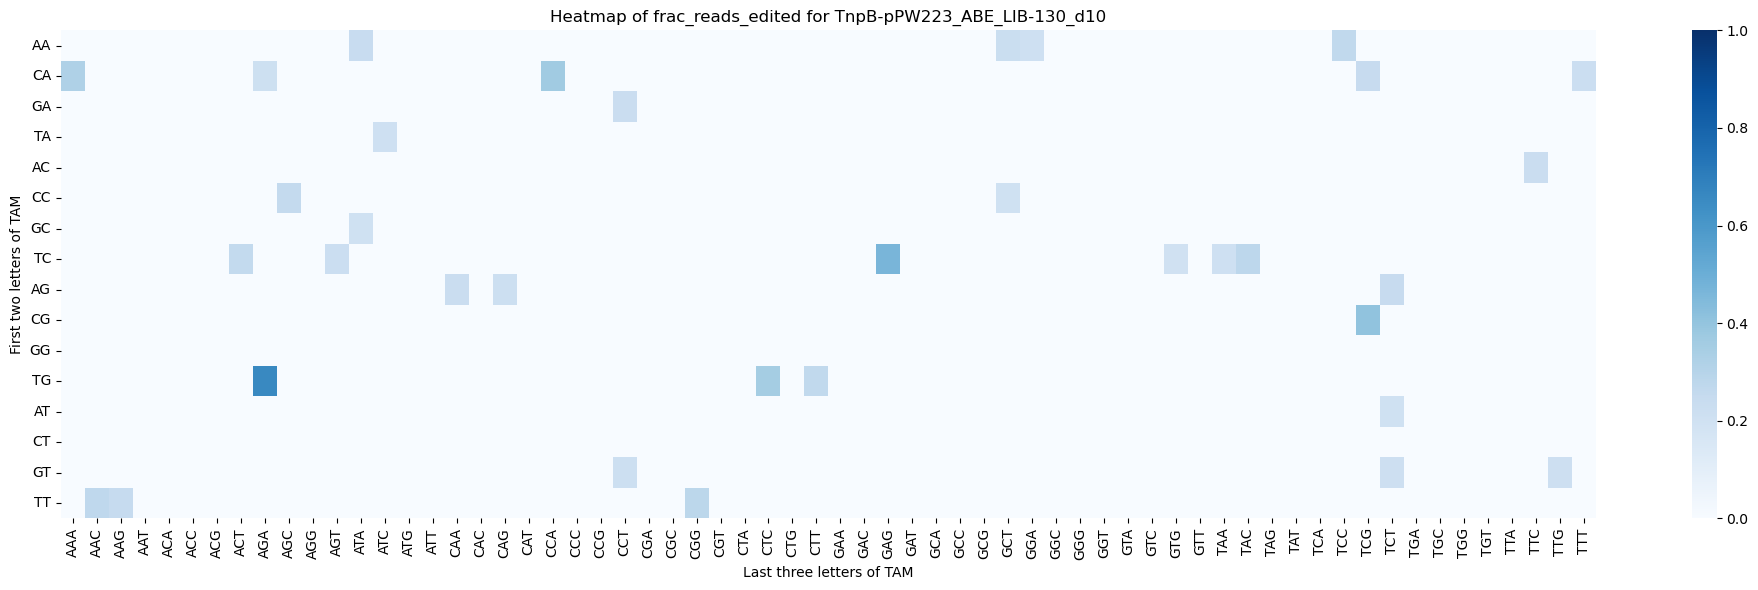

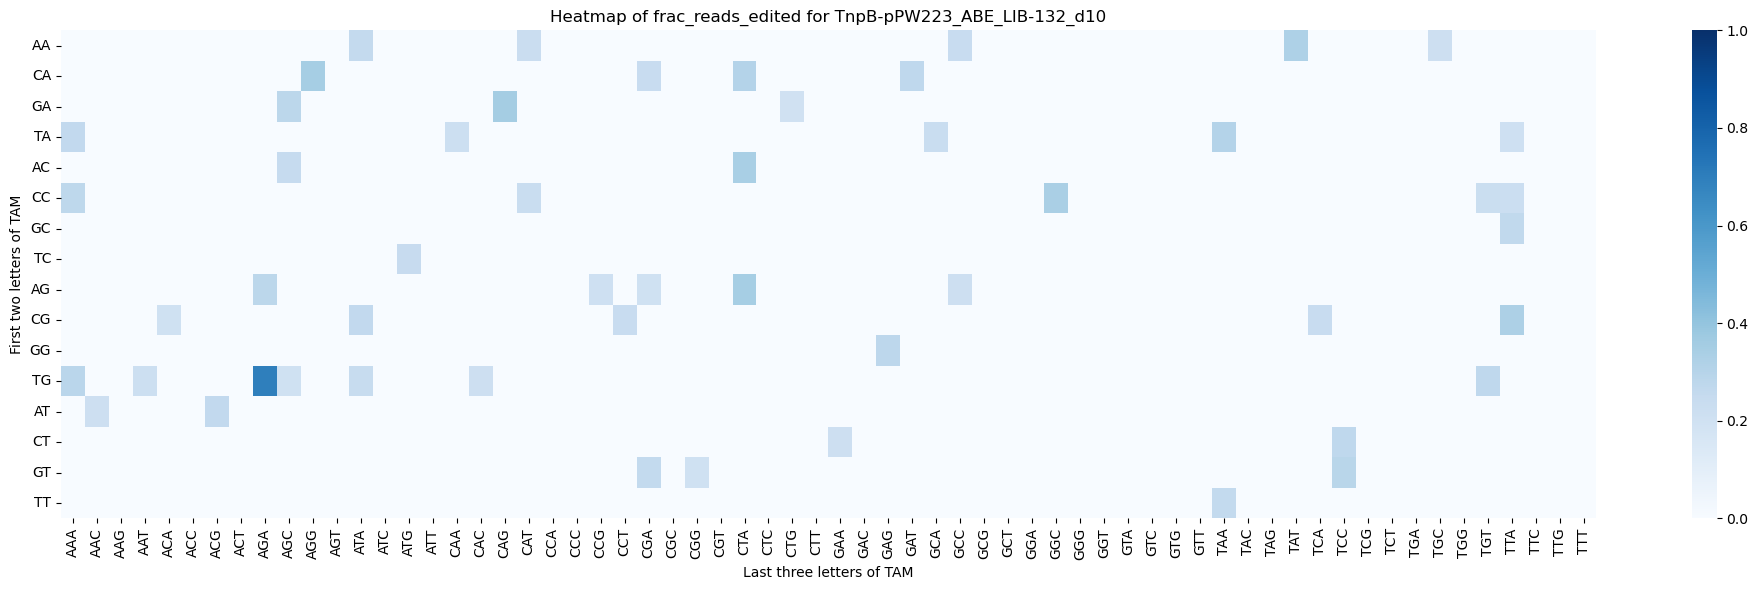

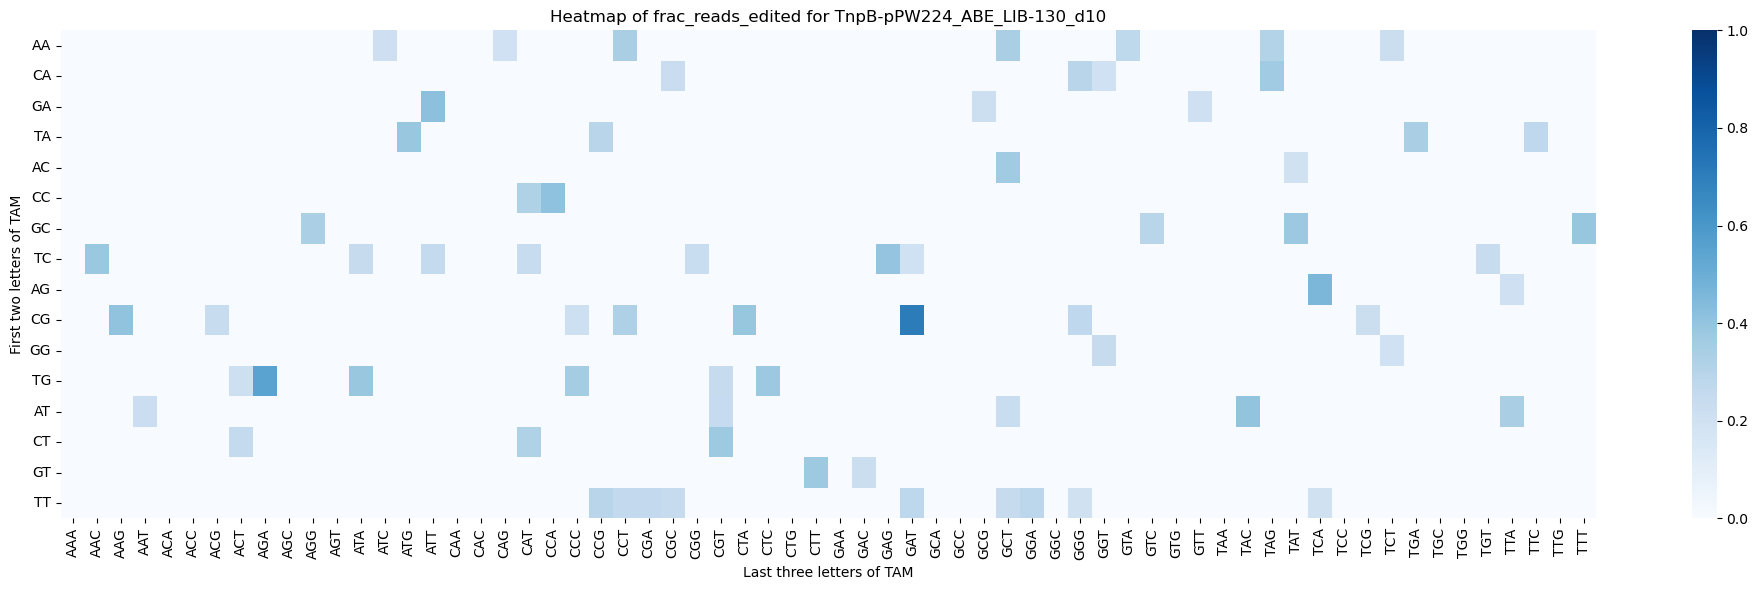

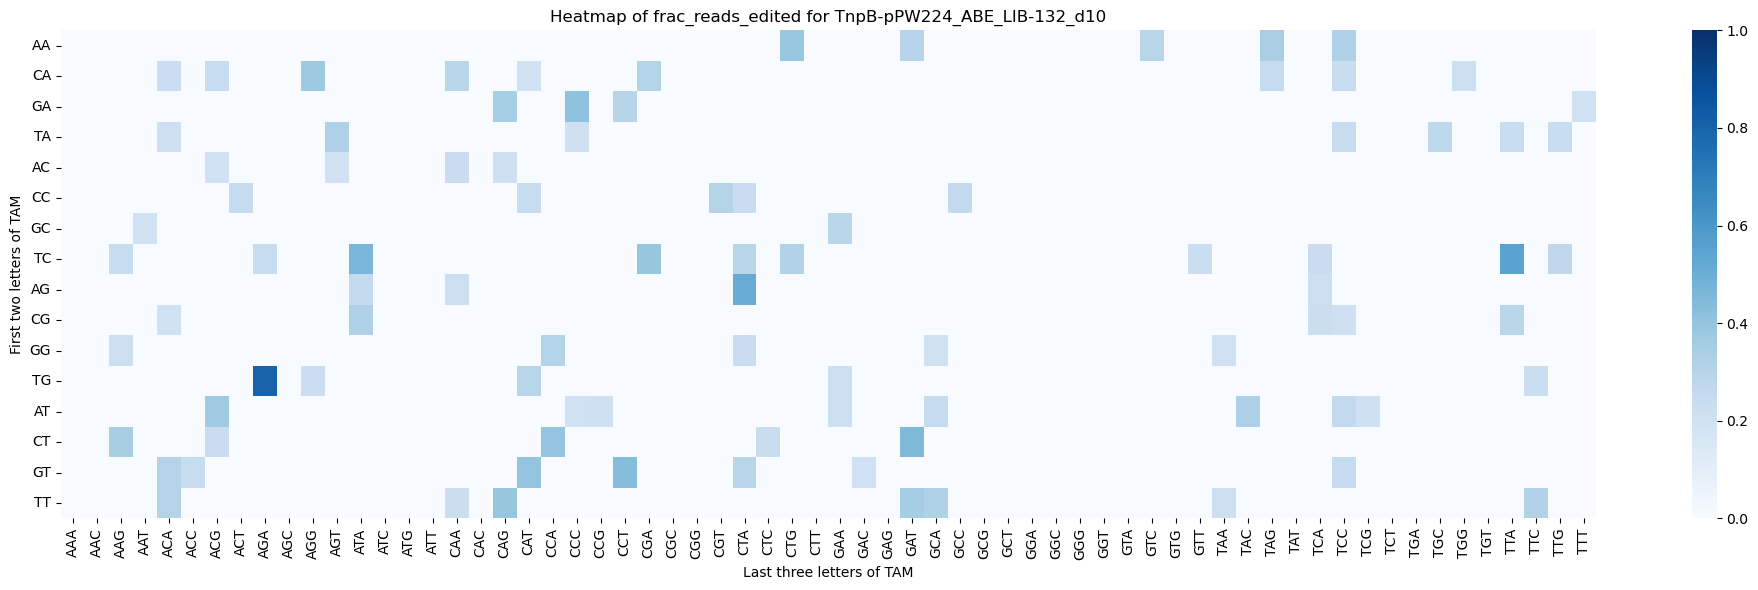

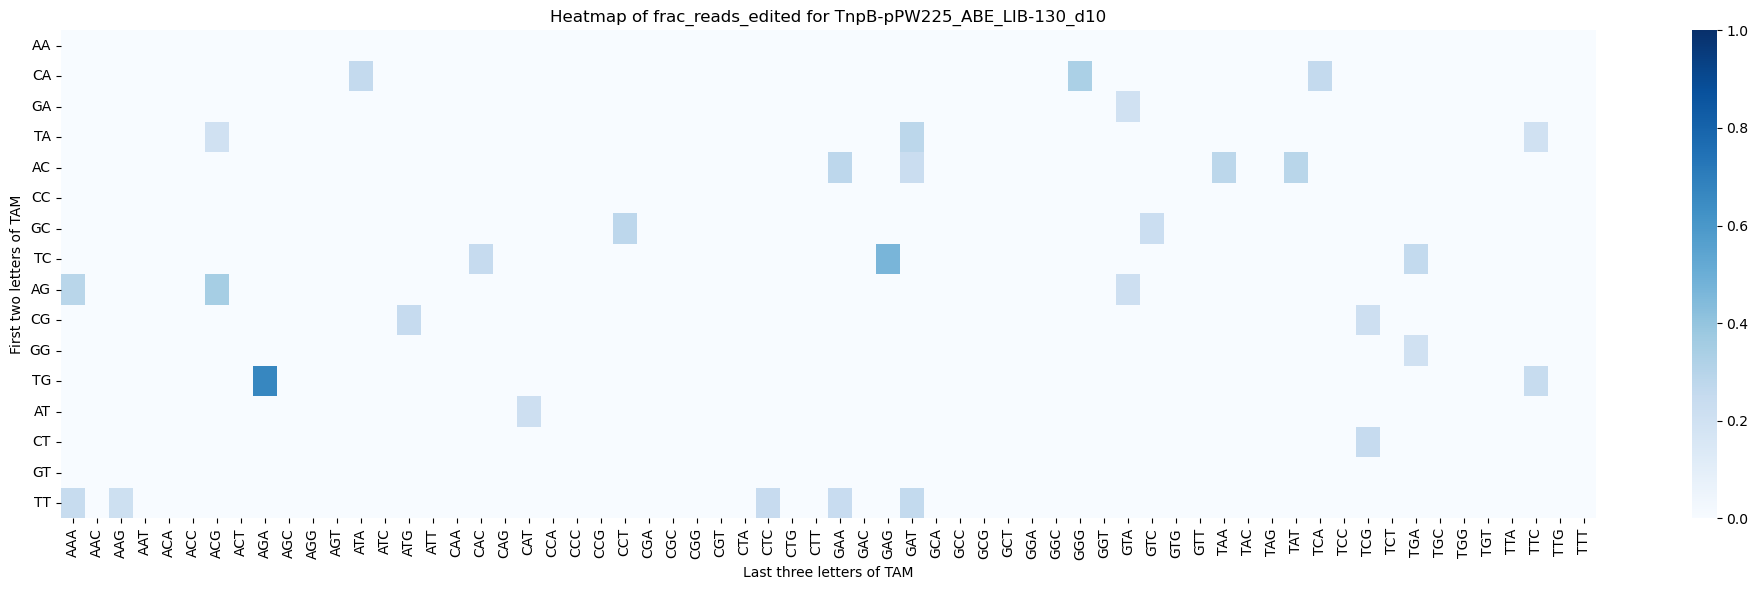

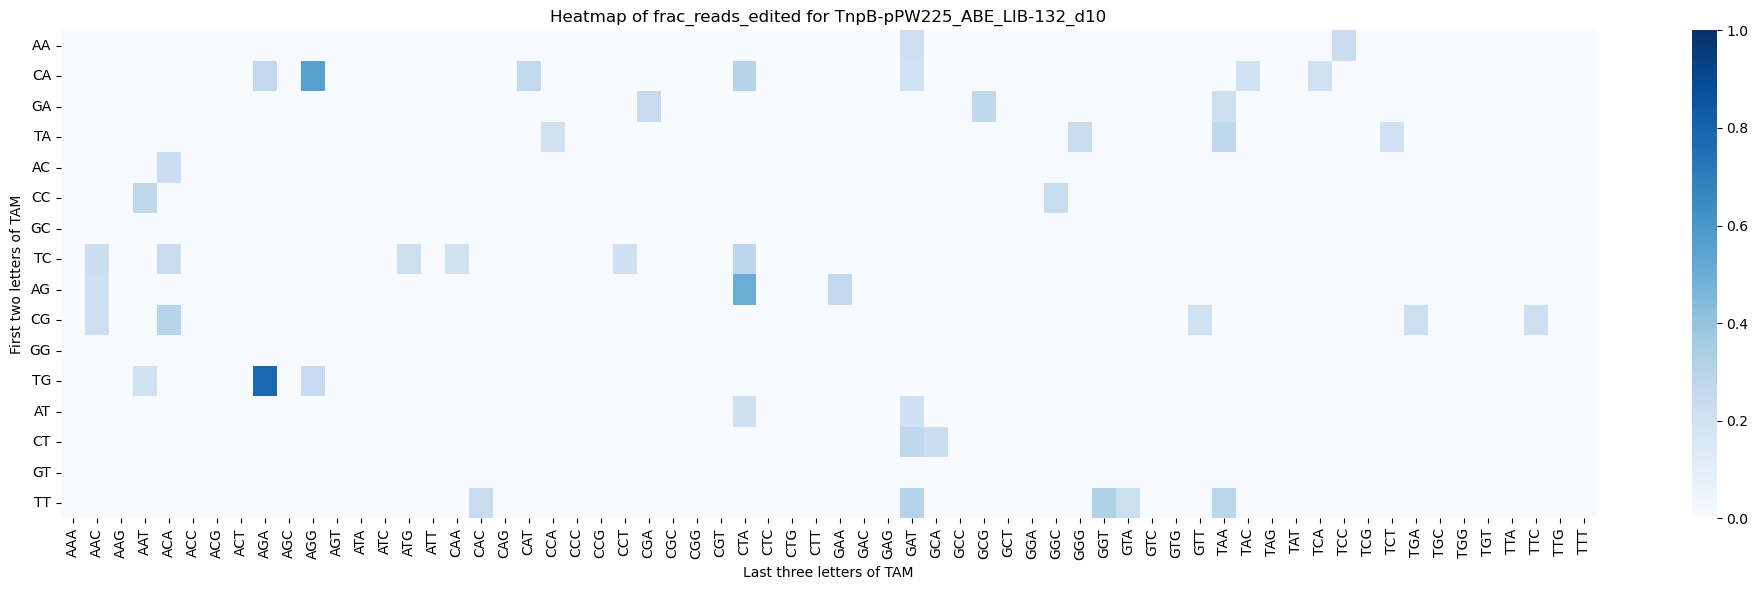

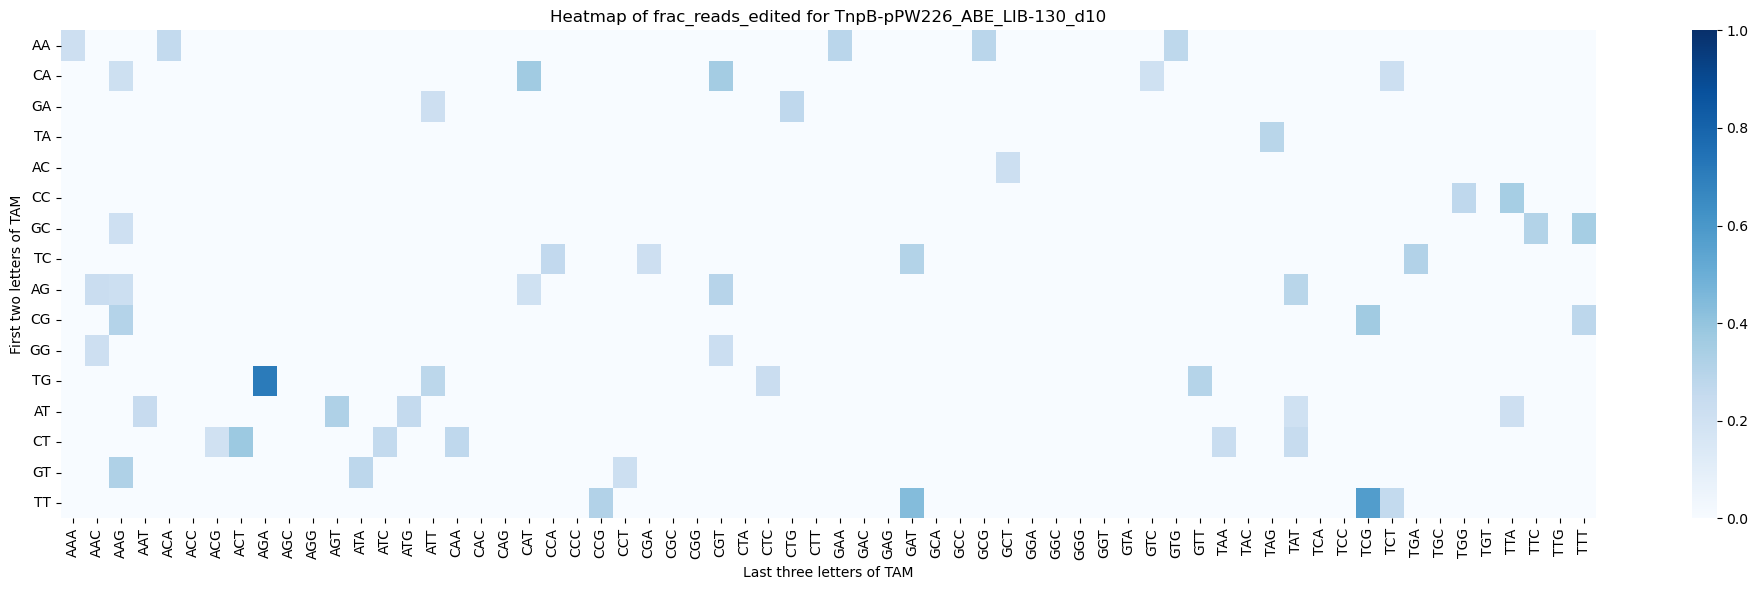

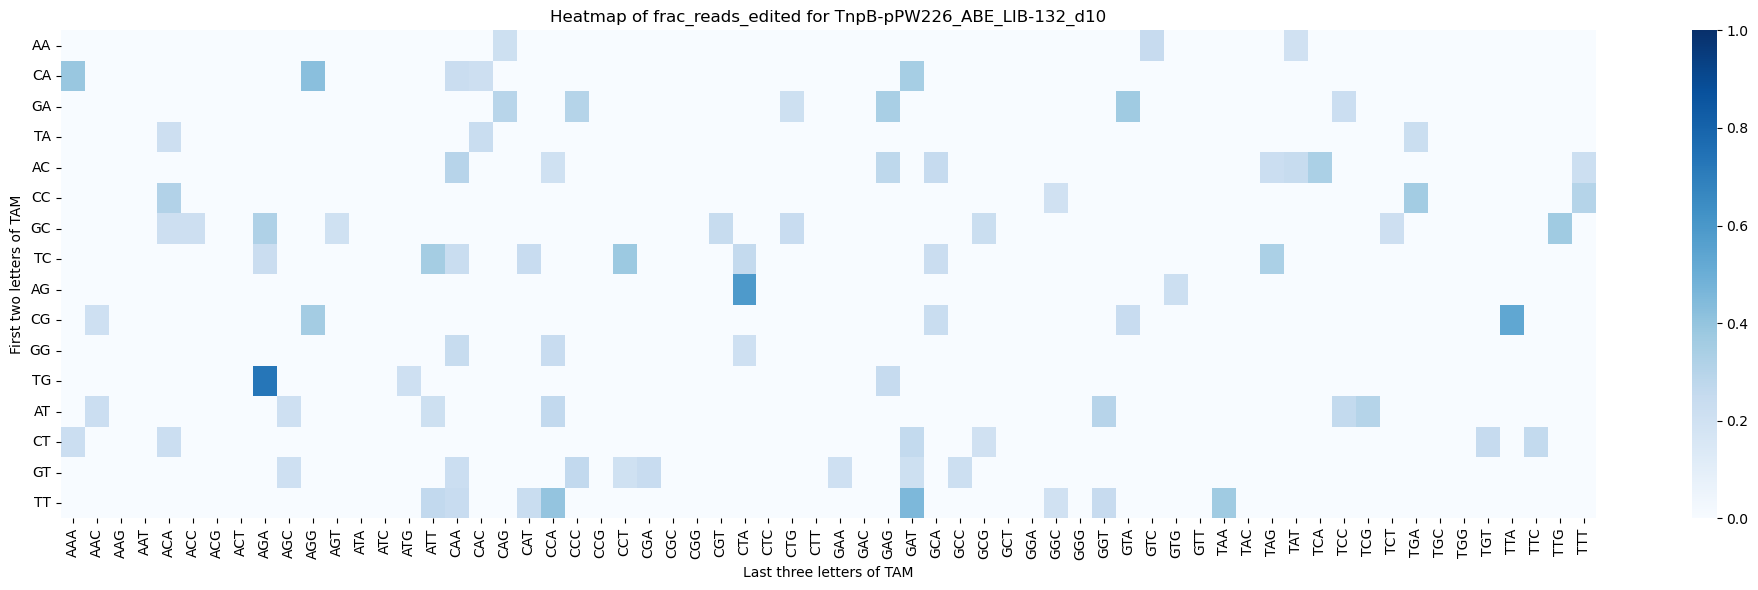

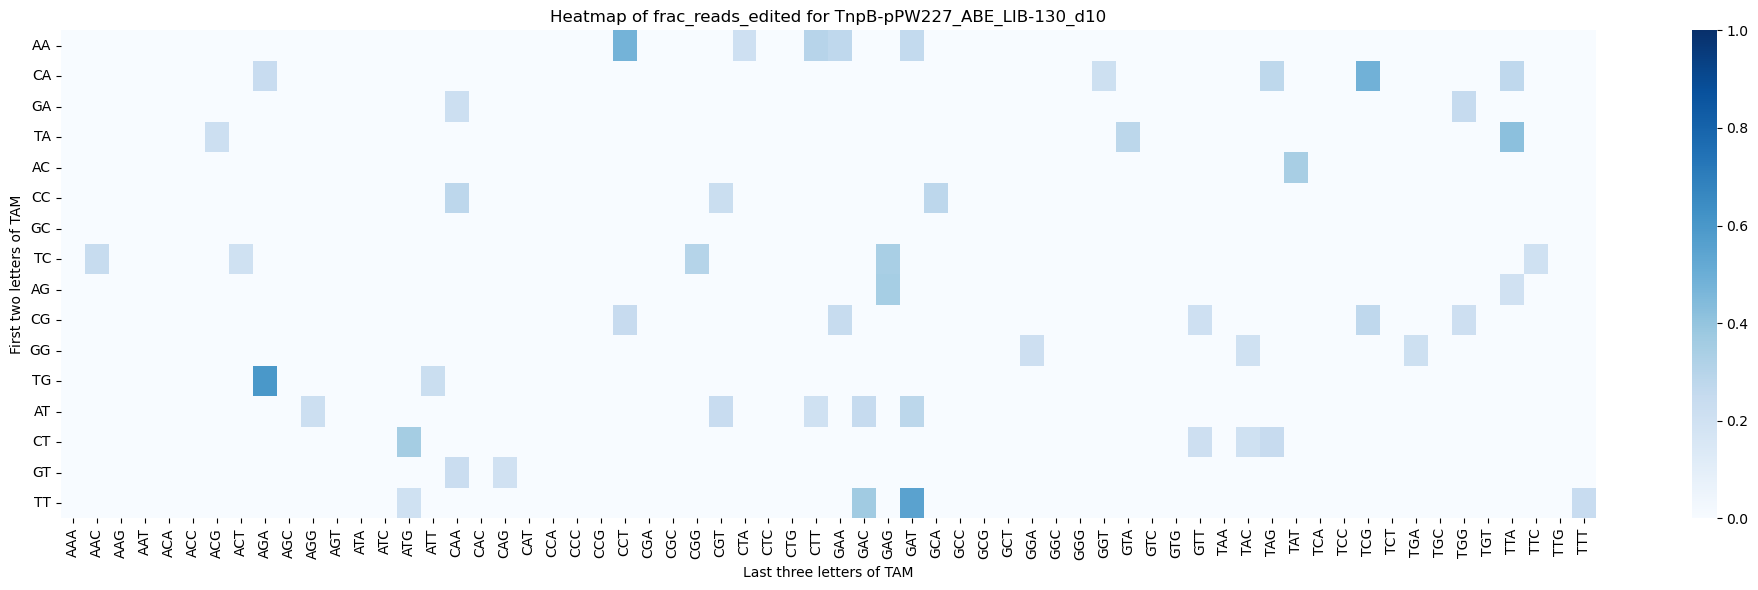

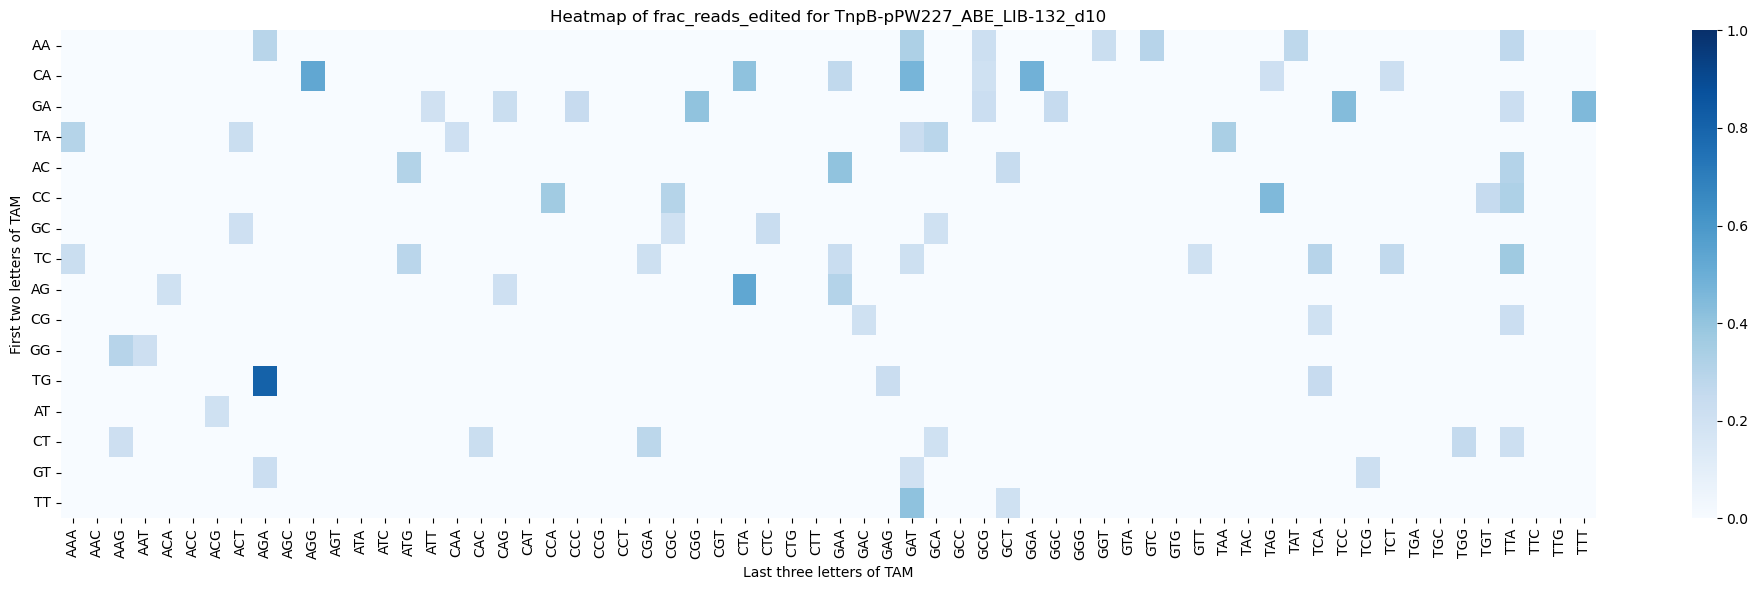

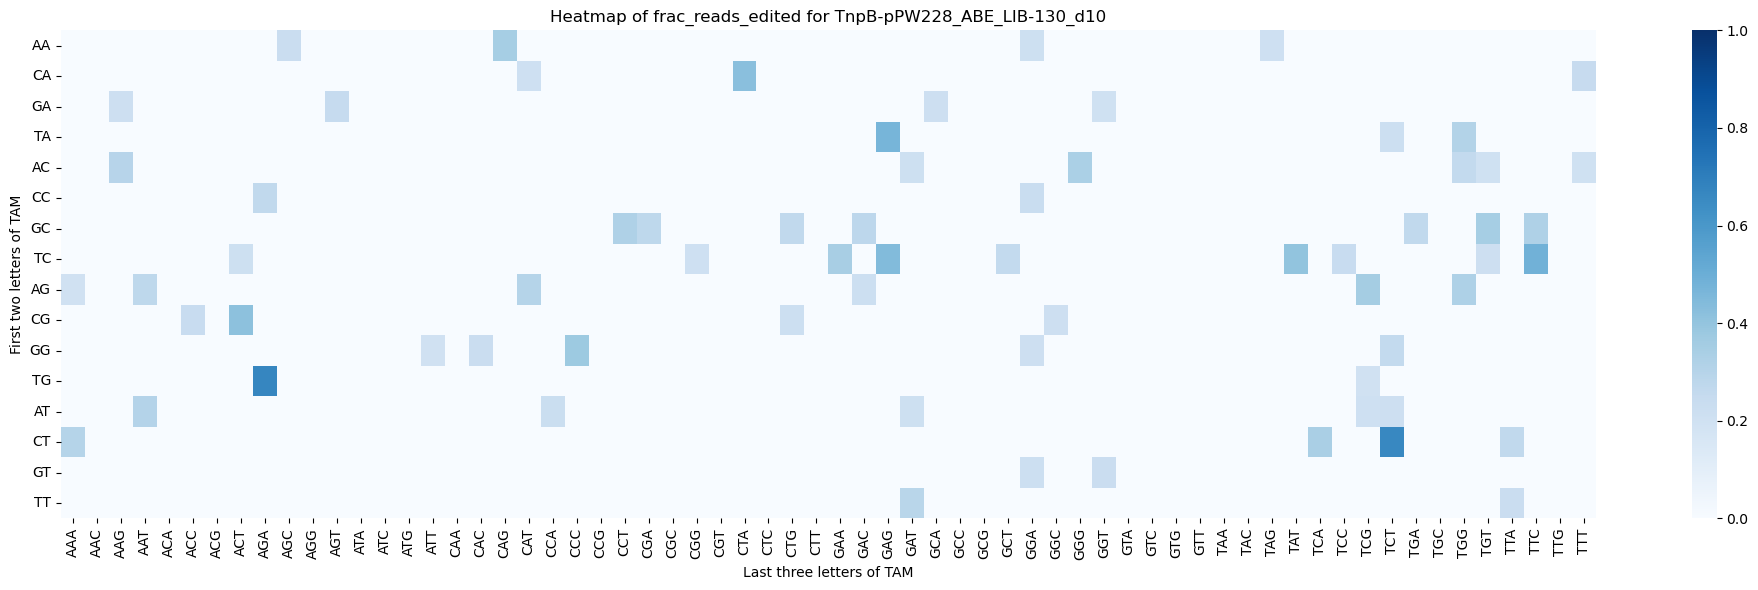

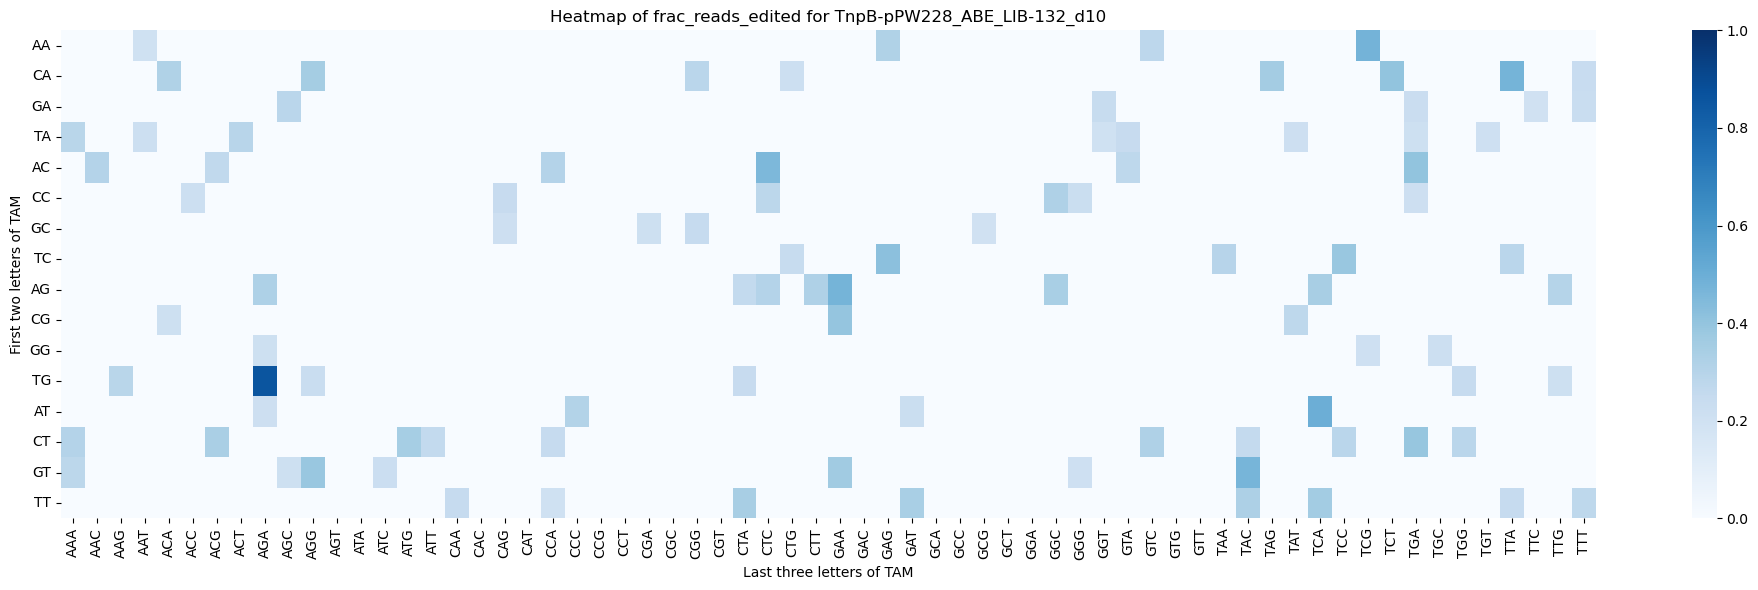

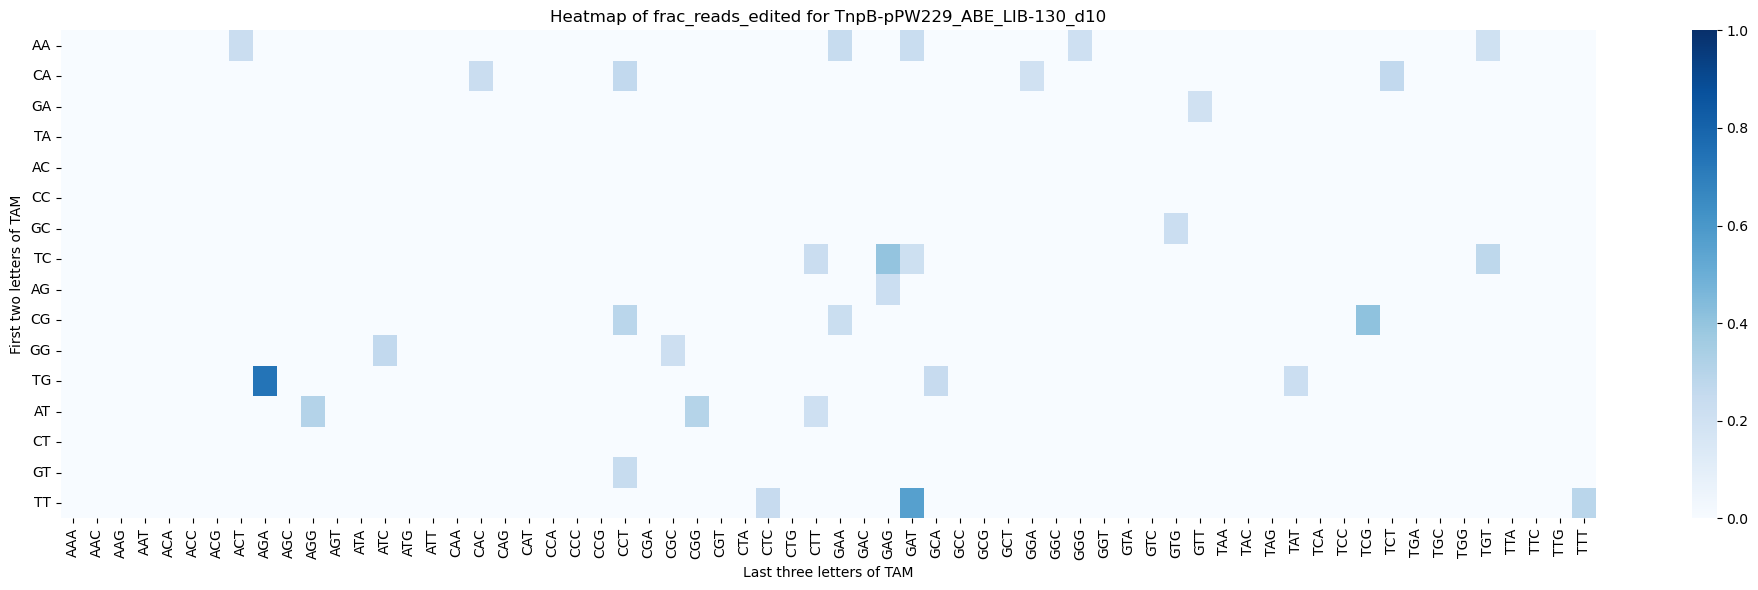

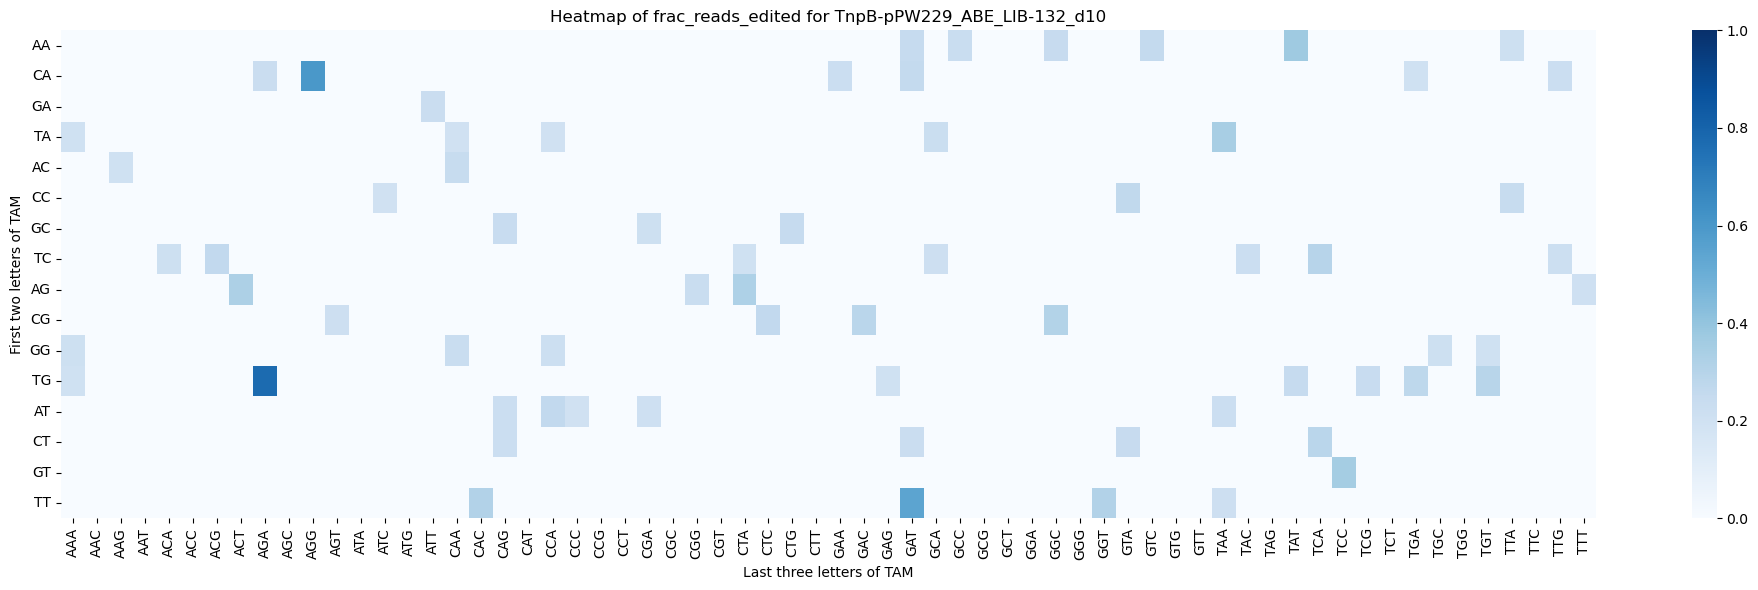

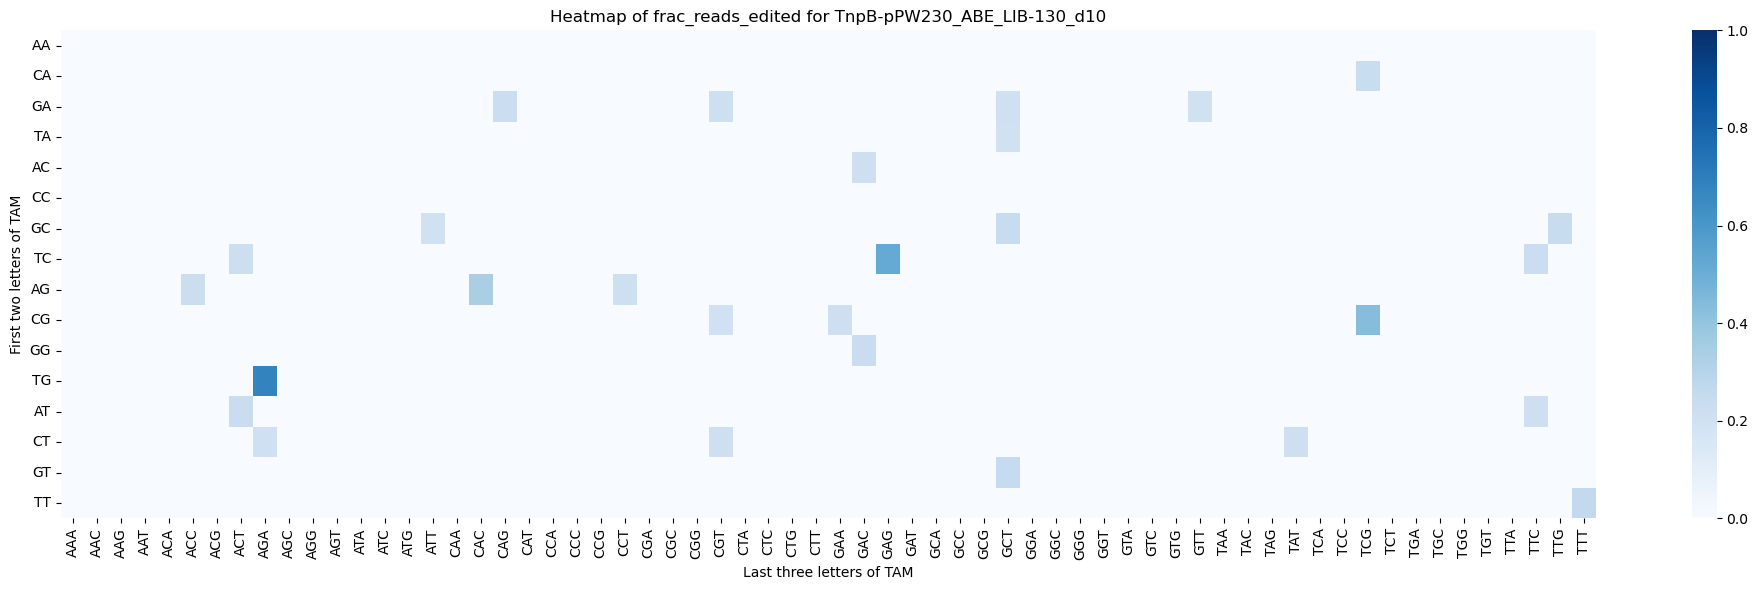

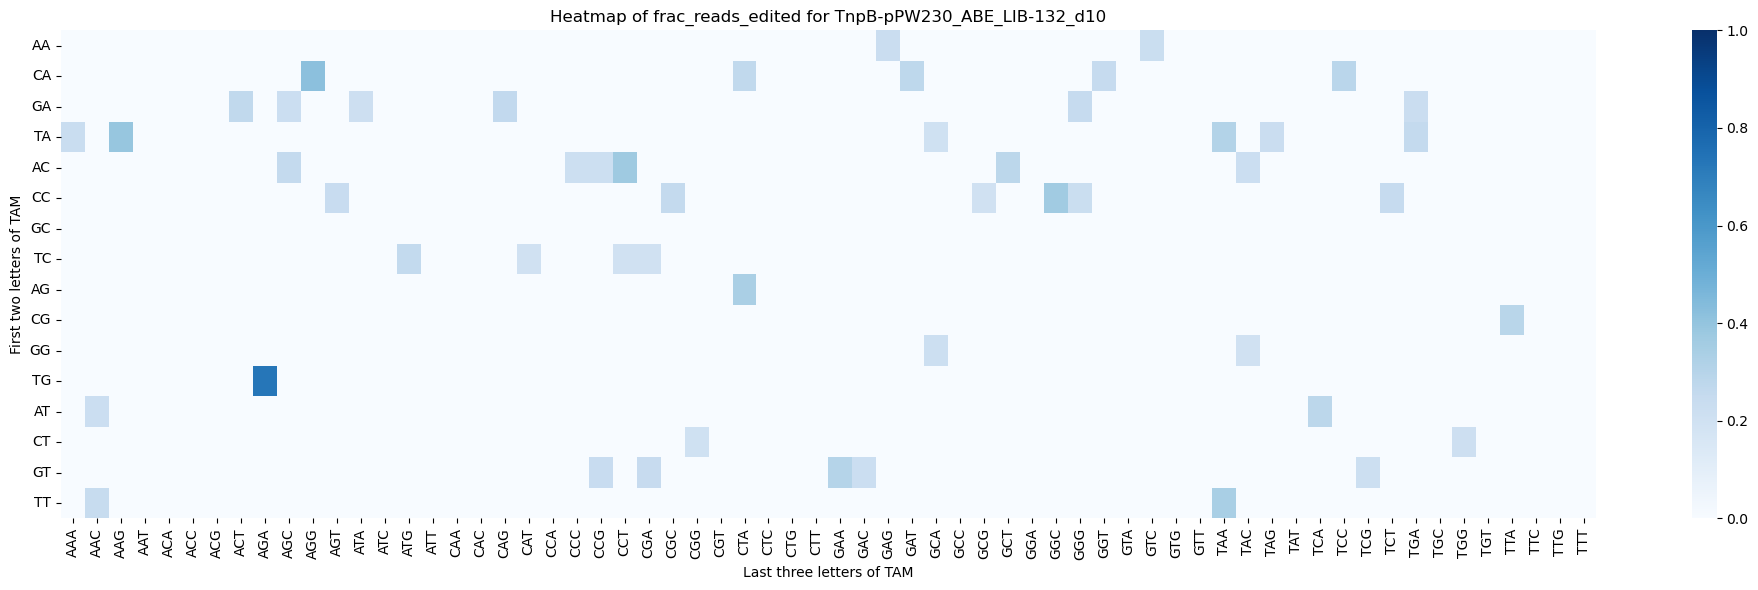

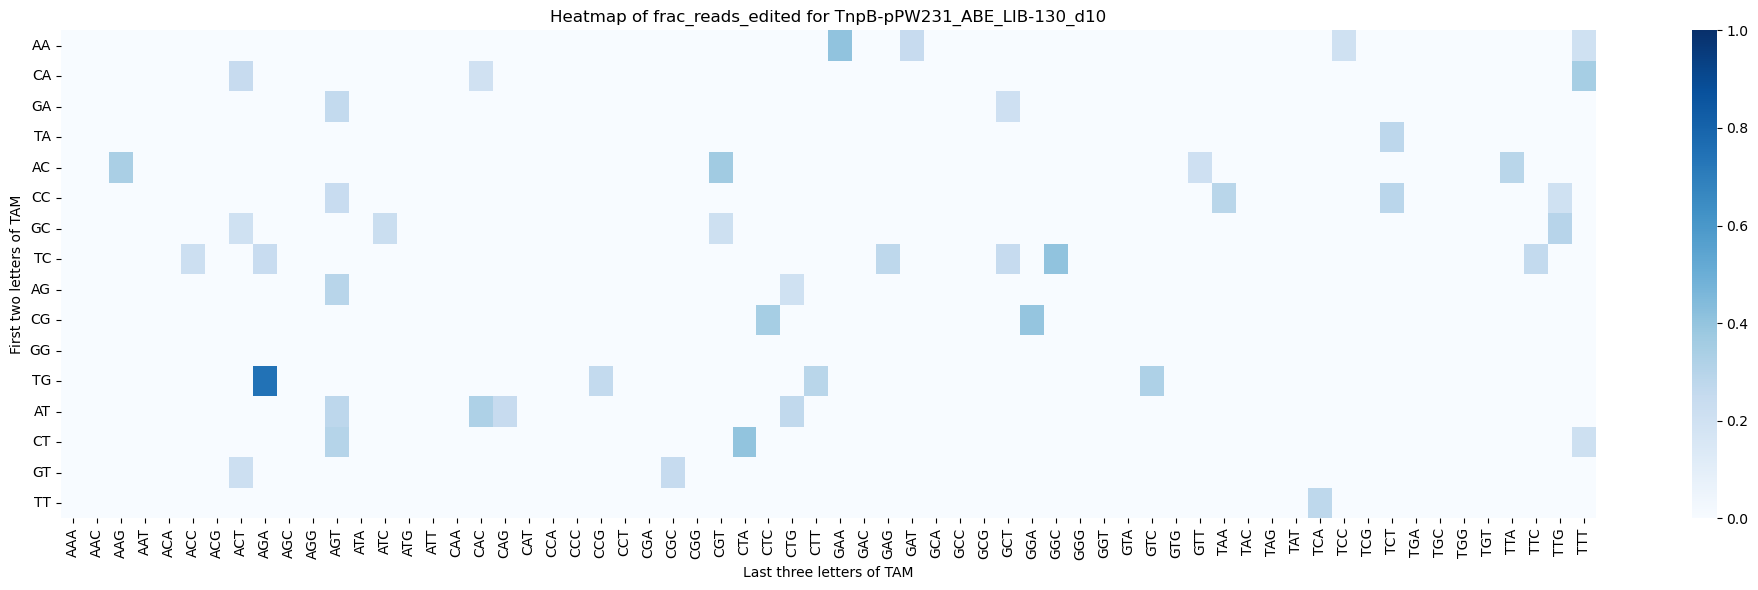

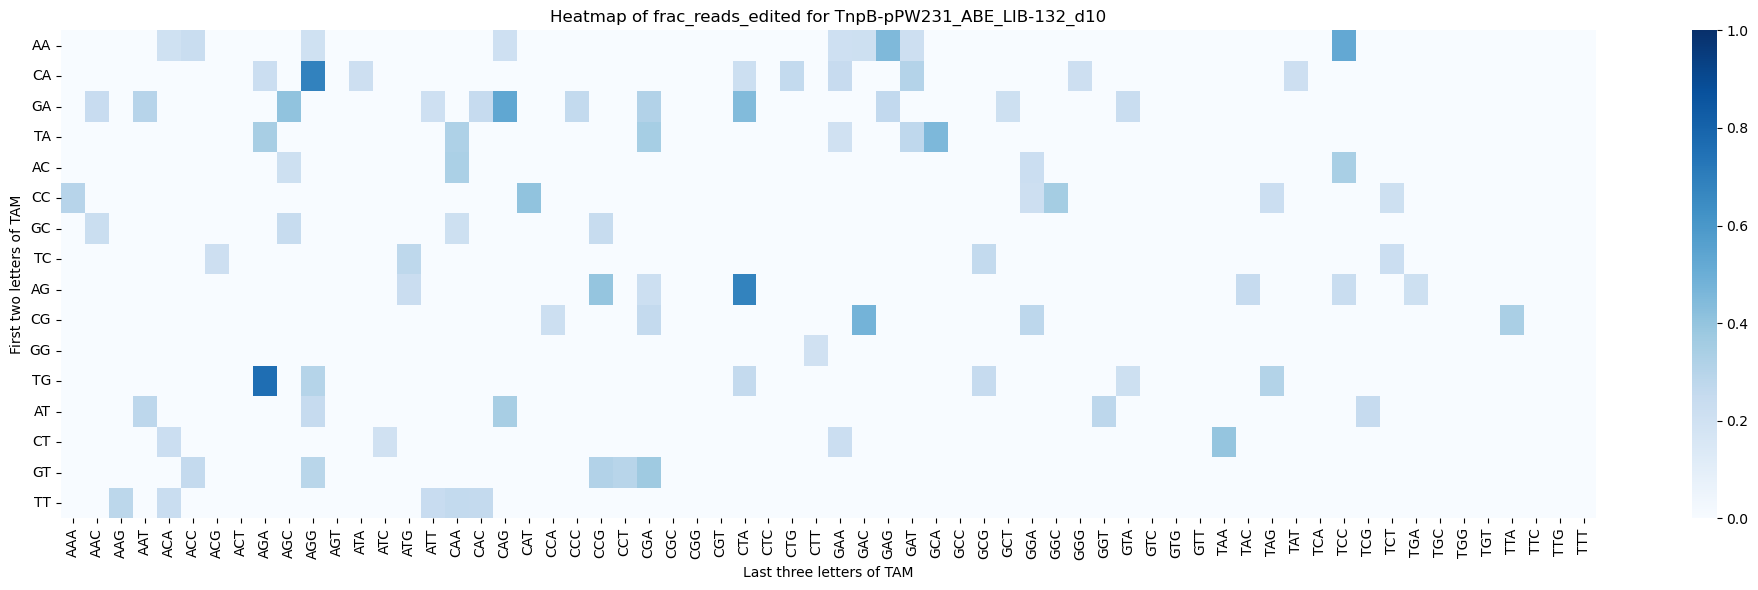

In [27]:
NAS_folder = "/mnt/G_Pharma/Users/tfang/Cell_Screen/Priscilla_A9-07_Screen/plots"
os.makedirs(NAS_folder, exist_ok=True)

def plot_heatmap_for_bioreplicate(mean_fracs, bioreplicate, vis_edit_thres=0.1, figsize=(8,6), cmap="viridis", save_figure=True, prefix="notNormalized"):

    # Filter for the specified bioreplicate and compute heatmap data
    df_heat = mean_fracs[mean_fracs["bioreplicate"] == bioreplicate].copy()
    df_heat.loc[df_heat['frac_reads_edited'] < vis_edit_thres, 'frac_reads_edited'] = 0
    # Check if all PAMs from config.PAMS are present in df_heat["TAM"]
    missing_pams = set(config.PAMS) - set(df_heat["TAM"].unique())
    if missing_pams:
        # For each missing PAM, add a row with frac_reads_edited set to 0
        df_missing = pd.DataFrame({'TAM': list(missing_pams), 'frac_reads_edited': 0})
        df_heat = pd.concat([df_heat, df_missing], ignore_index=True)
    df_heat["TAM_row"] = df_heat["TAM"].str[:2]
    df_heat["TAM_col"] = df_heat["TAM"].str[-3:]
    pivot_heat = df_heat.pivot_table(index="TAM_row",
                                     columns="TAM_col",
                                     values="frac_reads_edited",
                                     aggfunc="mean").fillna(0)

    # Plot the heatmap
    pivot_heat = pivot_heat.sort_index(key=lambda x: [s[1] + s[0] for s in x], ascending=True)

    plt.figure(figsize=figsize)
    sns.heatmap(pivot_heat, fmt=".3f", cmap=cmap, vmin=0, vmax=1)
    plt.yticks(rotation=0)
    plt.title(f"Heatmap of frac_reads_edited for {bioreplicate}")
    plt.ylabel("First two letters of TAM")
    plt.xlabel("Last three letters of TAM")
    plt.tight_layout()

    #Save the figure to NAS_folder
    if save_figure:
        save_path = os.path.join(NAS_folder, f"{prefix}_heatmap_{bioreplicate}_{vis_edit_thres}.png")
        plt.savefig(save_path)
        plt.show()

mean_fracs_not_normalized = all_abe_samples_reads_editedrates_not_normalized.groupby(['bioreplicate','TAM', 'spacer'])['frac_reads_edited'].mean().reset_index()
mean_fracs_not_normalized.sort_values(by=['TAM',], inplace=True)
mean_fracs_not_normalized

vis_bioreplicates=sorted(mean_fracs_not_normalized.bioreplicate.unique())
for bioreplicate in vis_bioreplicates:
    plot_heatmap_for_bioreplicate(mean_fracs_not_normalized, bioreplicate, vis_edit_thres=0.2,
                                  figsize=(20,6), cmap="Blues", save_figure=False, prefix="notNormalized")

    

,editor,bioreplicate,TAM,spacer,frac_reads_edited
0,NOEDITOR,Mock_LIB-130_d10,AAAAA,TATTATATATGAGTTCACTG,0.034423
3072,TnpB-WT_ABE,TnpB-WT_ABE_LIB-132_d10,AAAAA,ATACTGTAAAGAAGCAGAAA,0.076380
4096,TnpB-pPW220_ABE,TnpB-pPW220_ABE_LIB-130_d10,AAAAA,TATTATATATGAGTTCACTG,0.152460


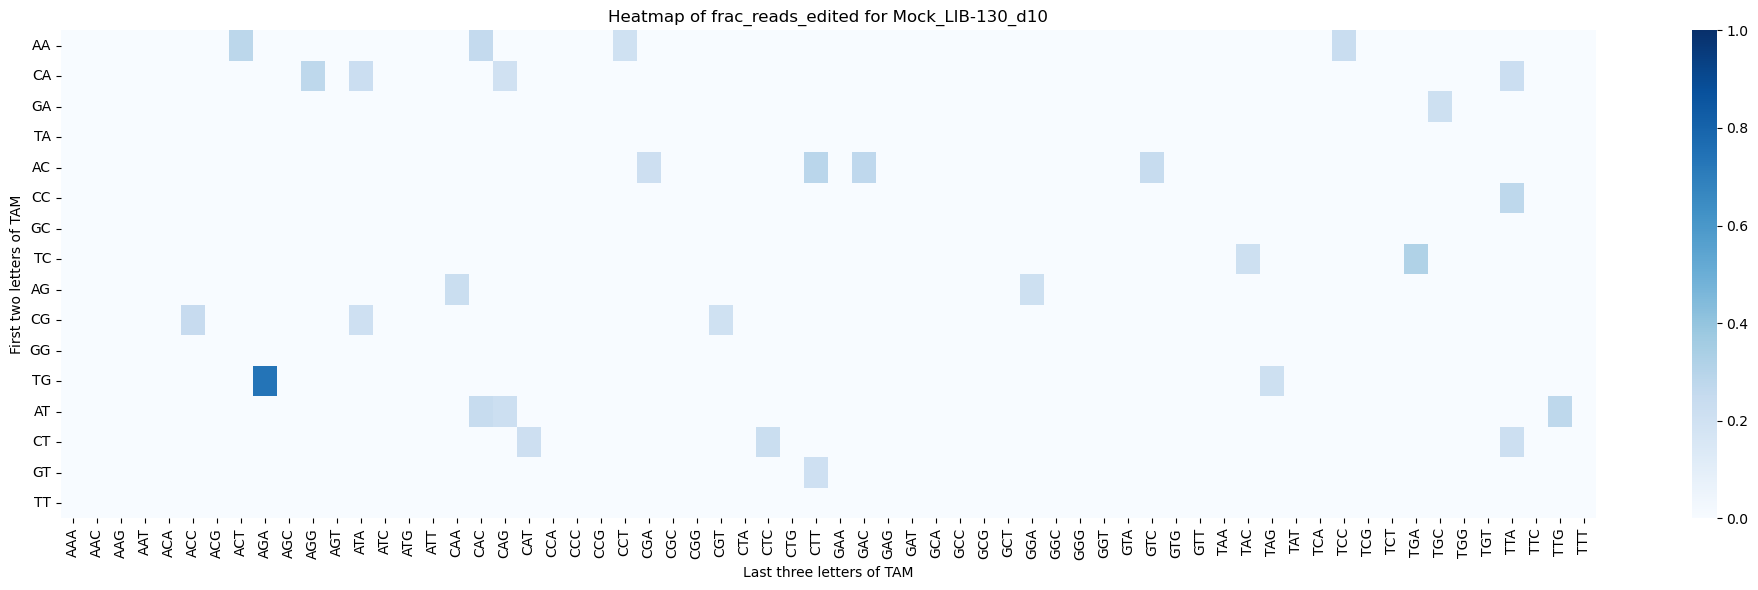

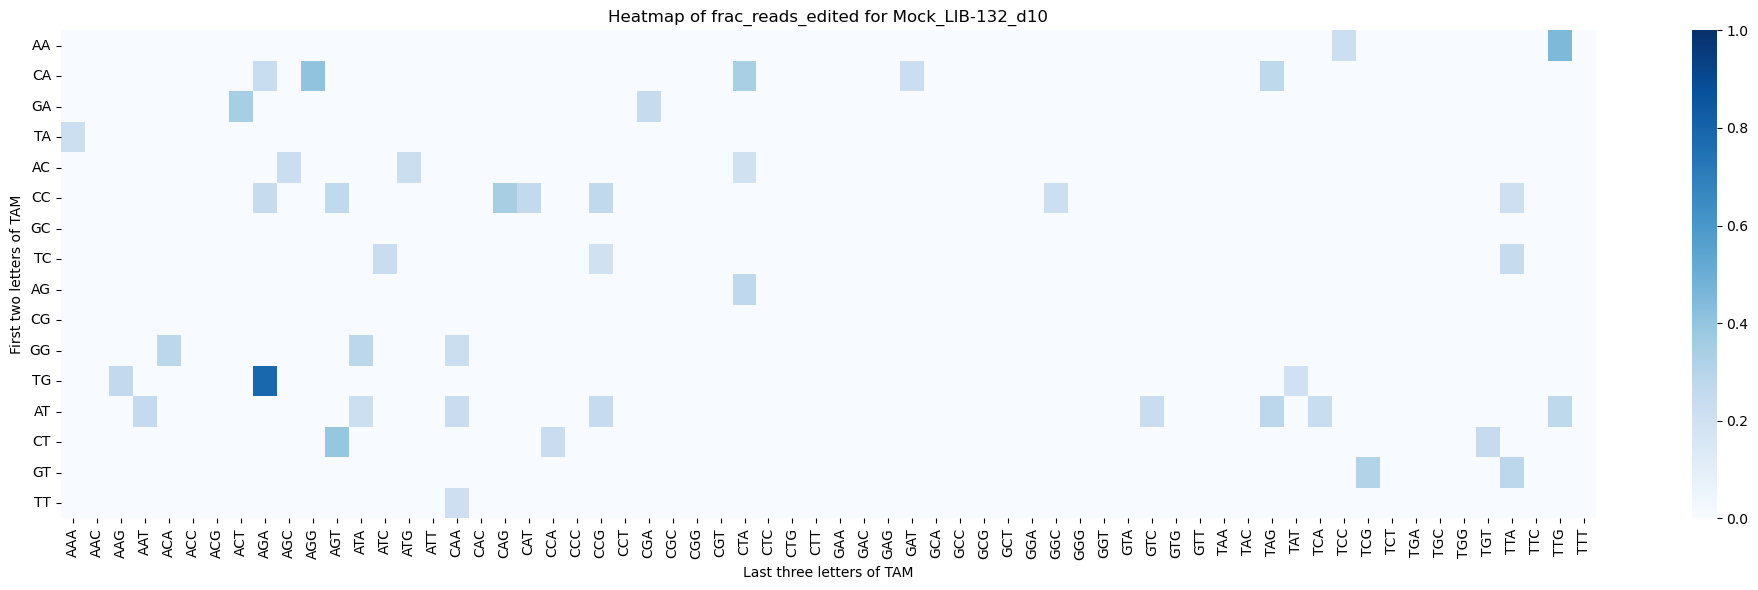

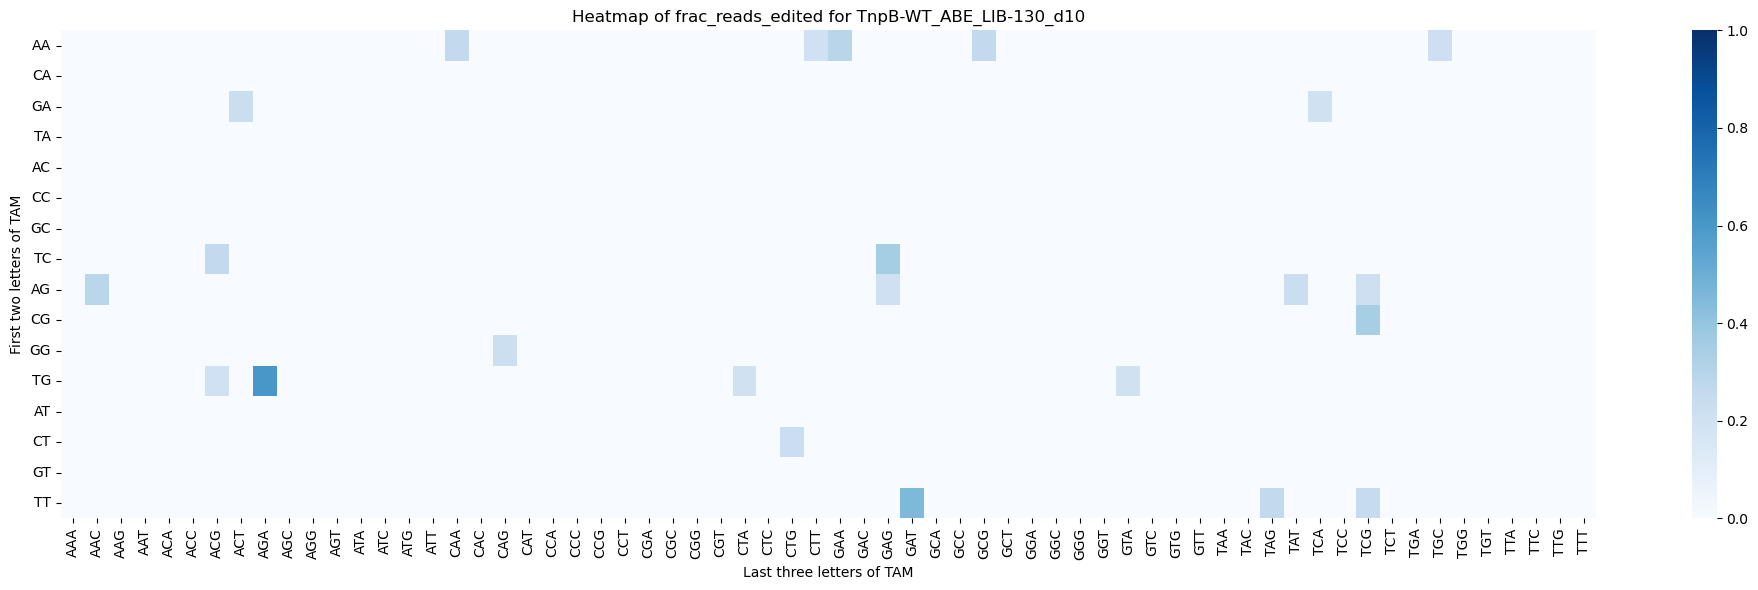

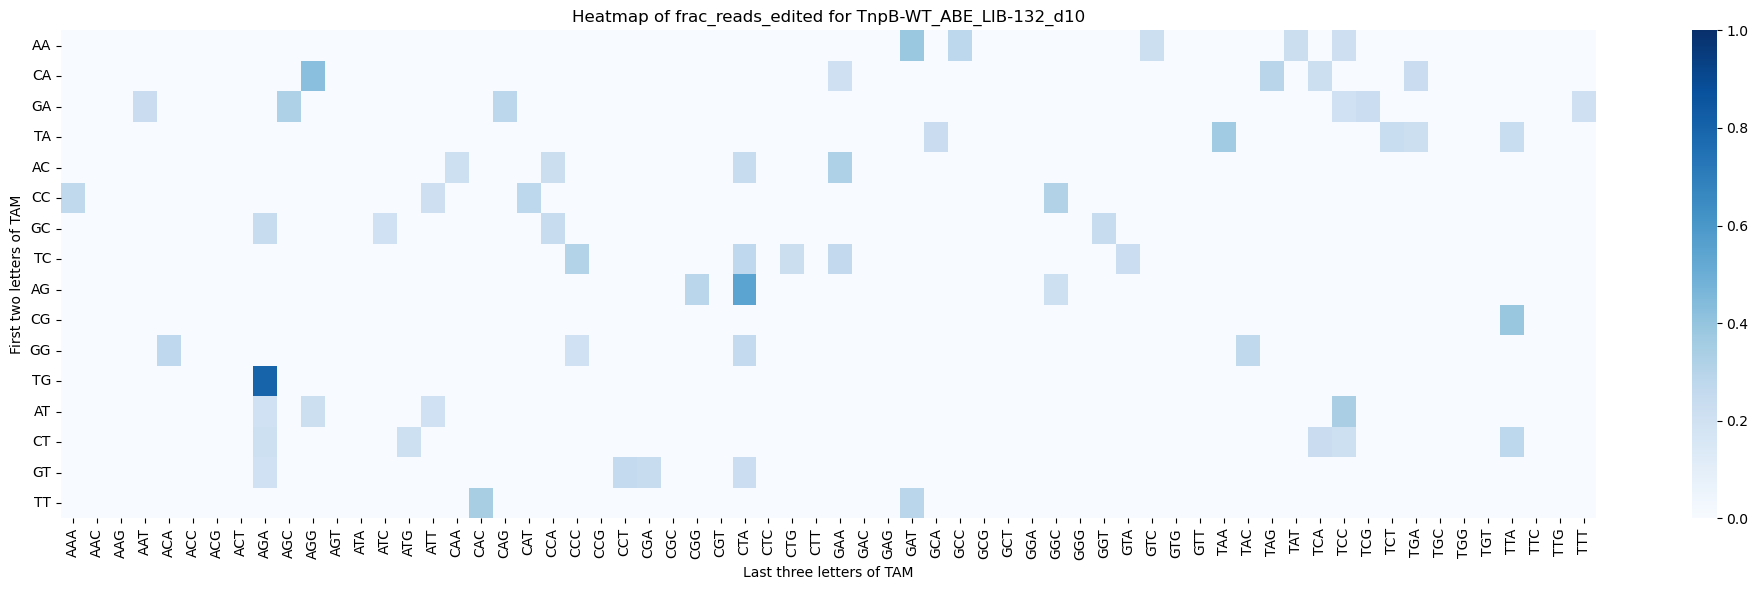

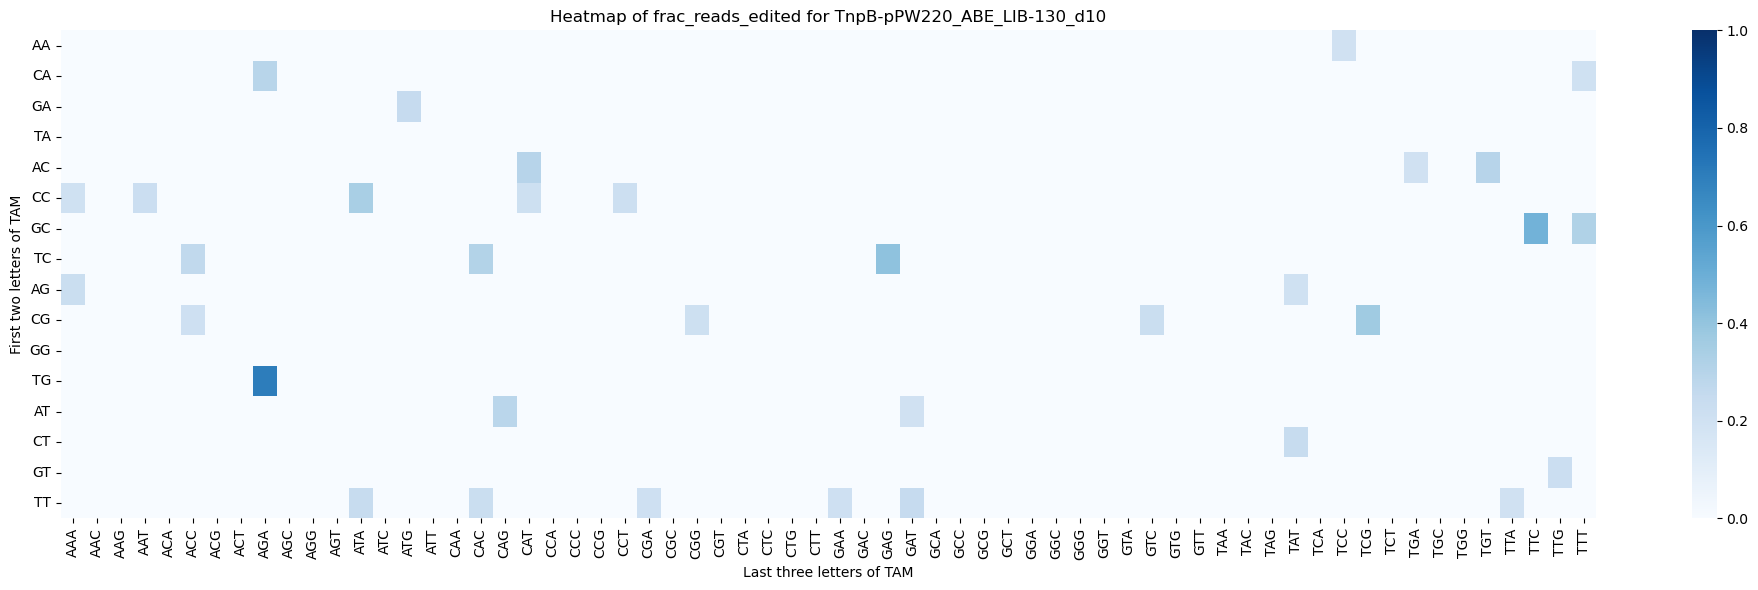

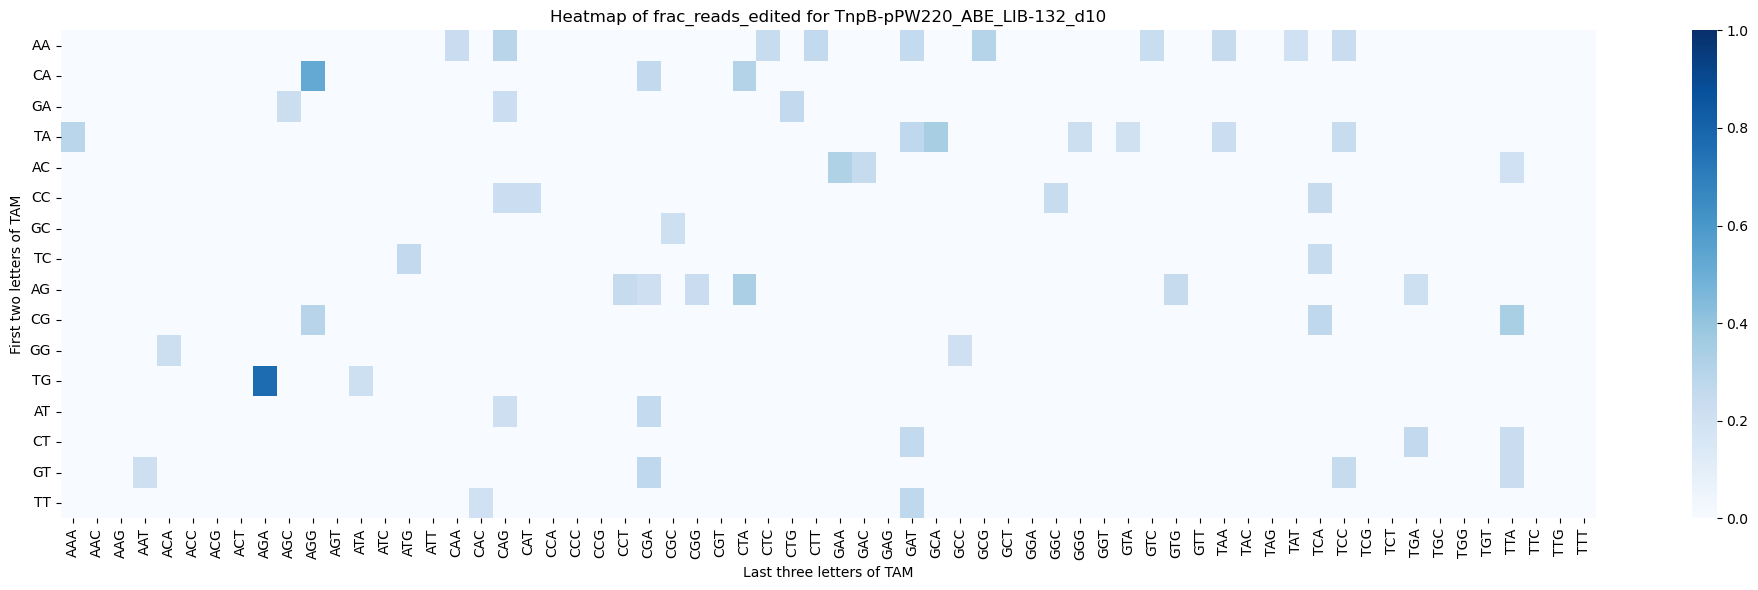

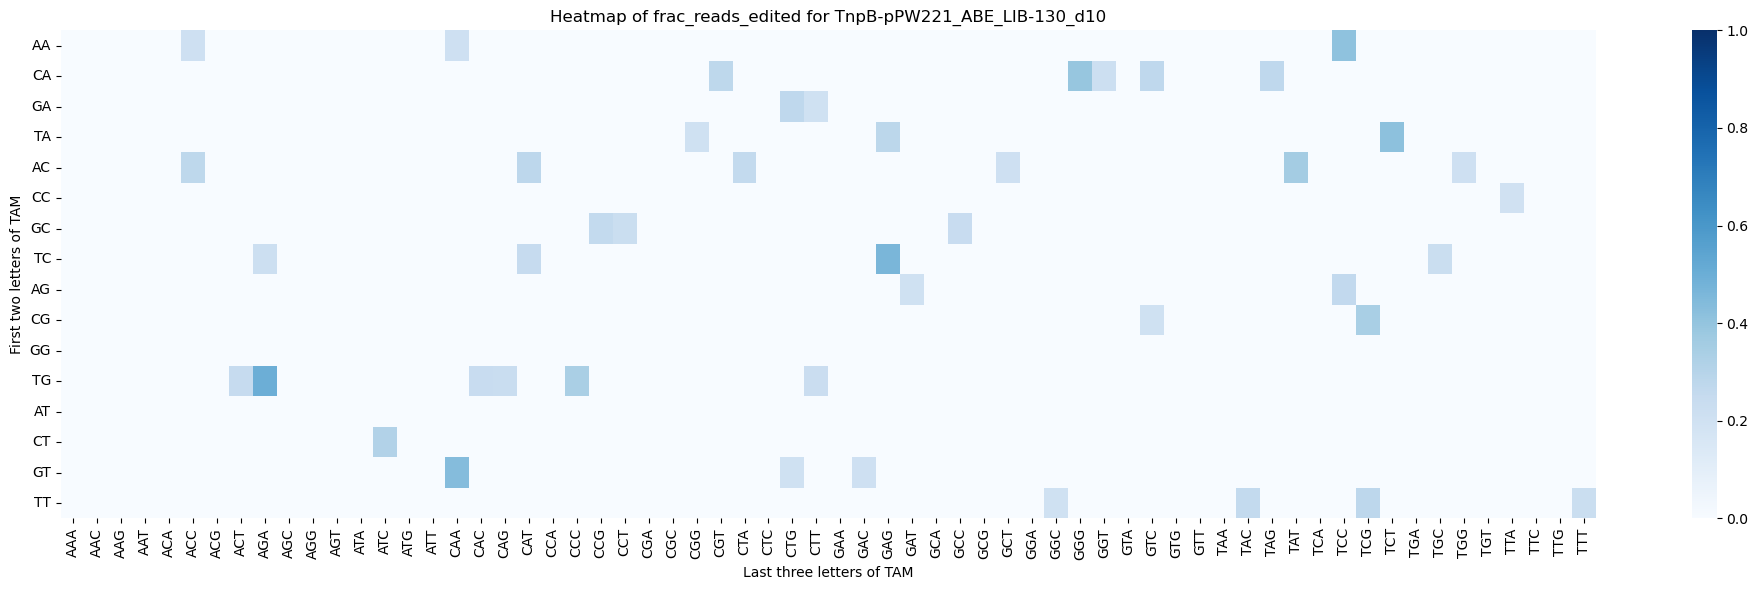

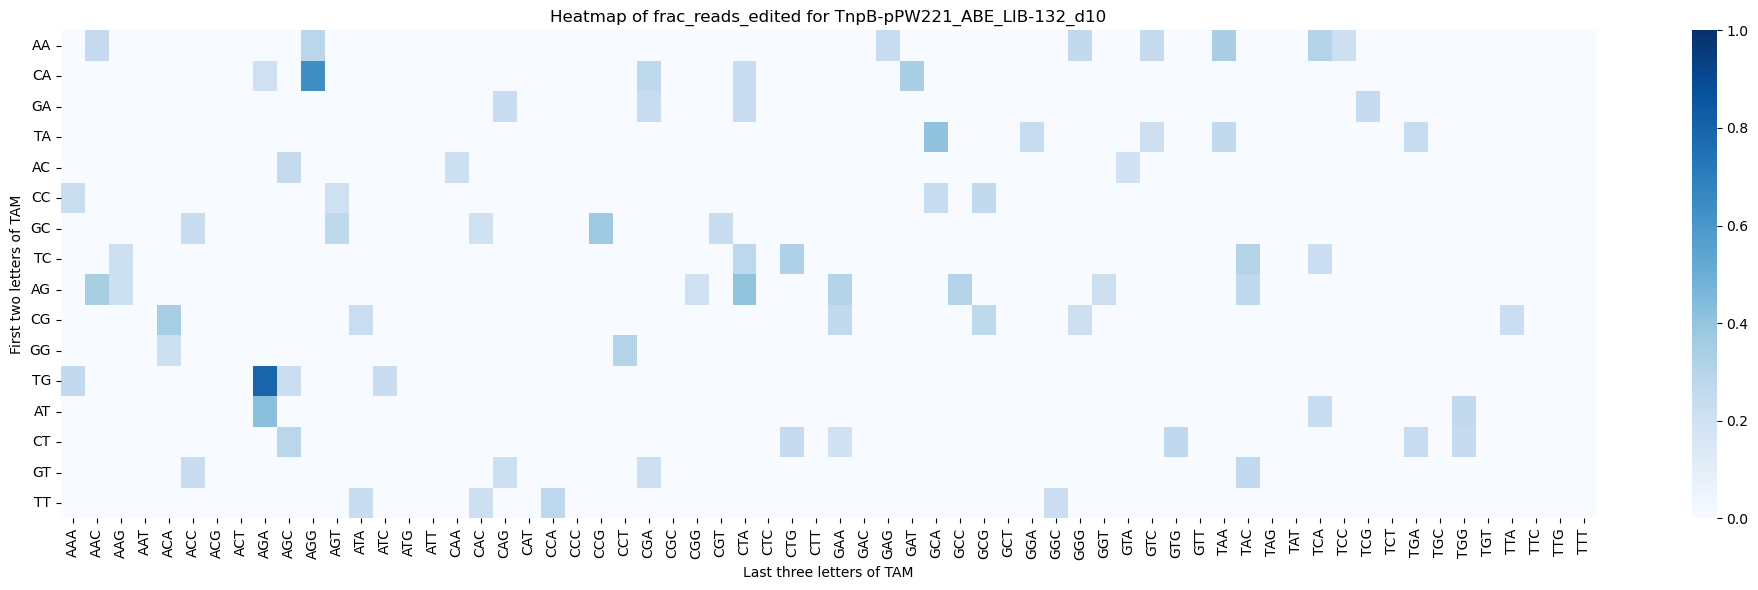

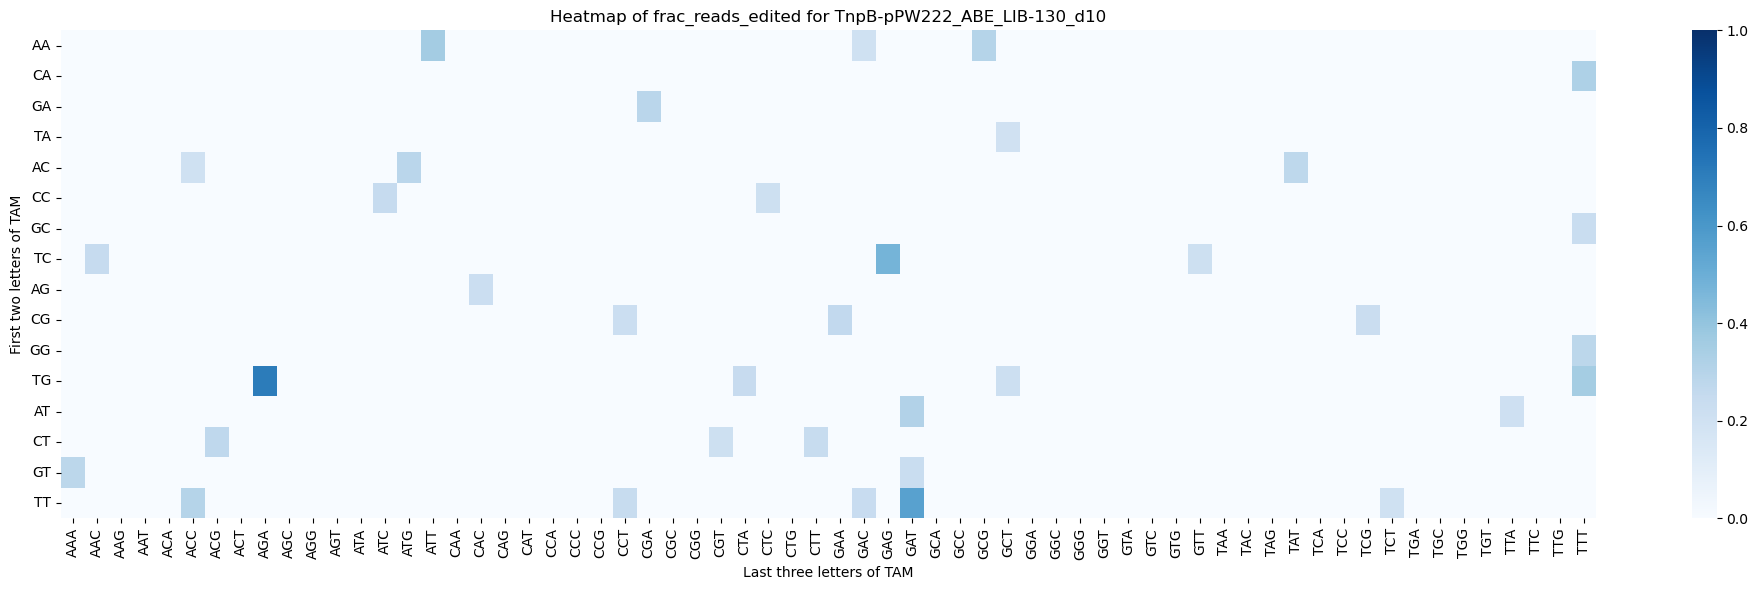

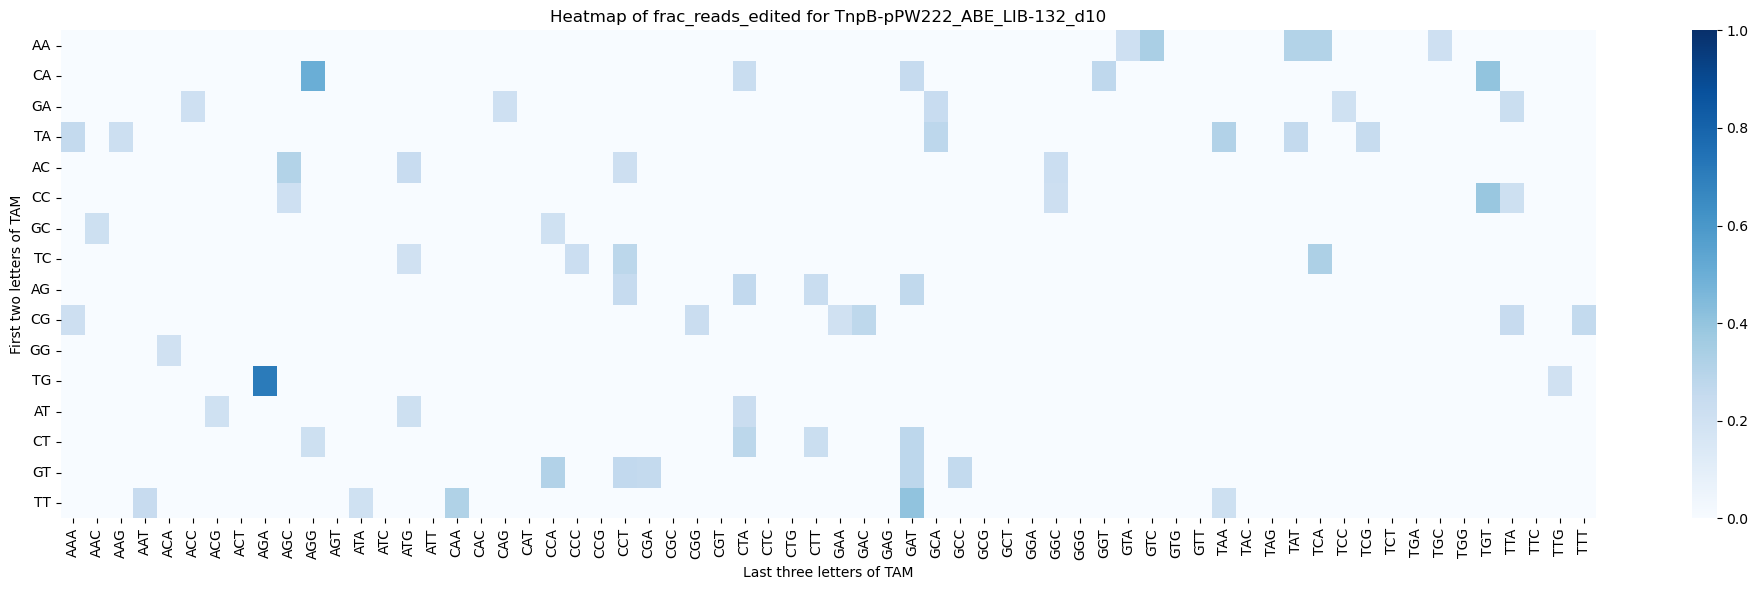

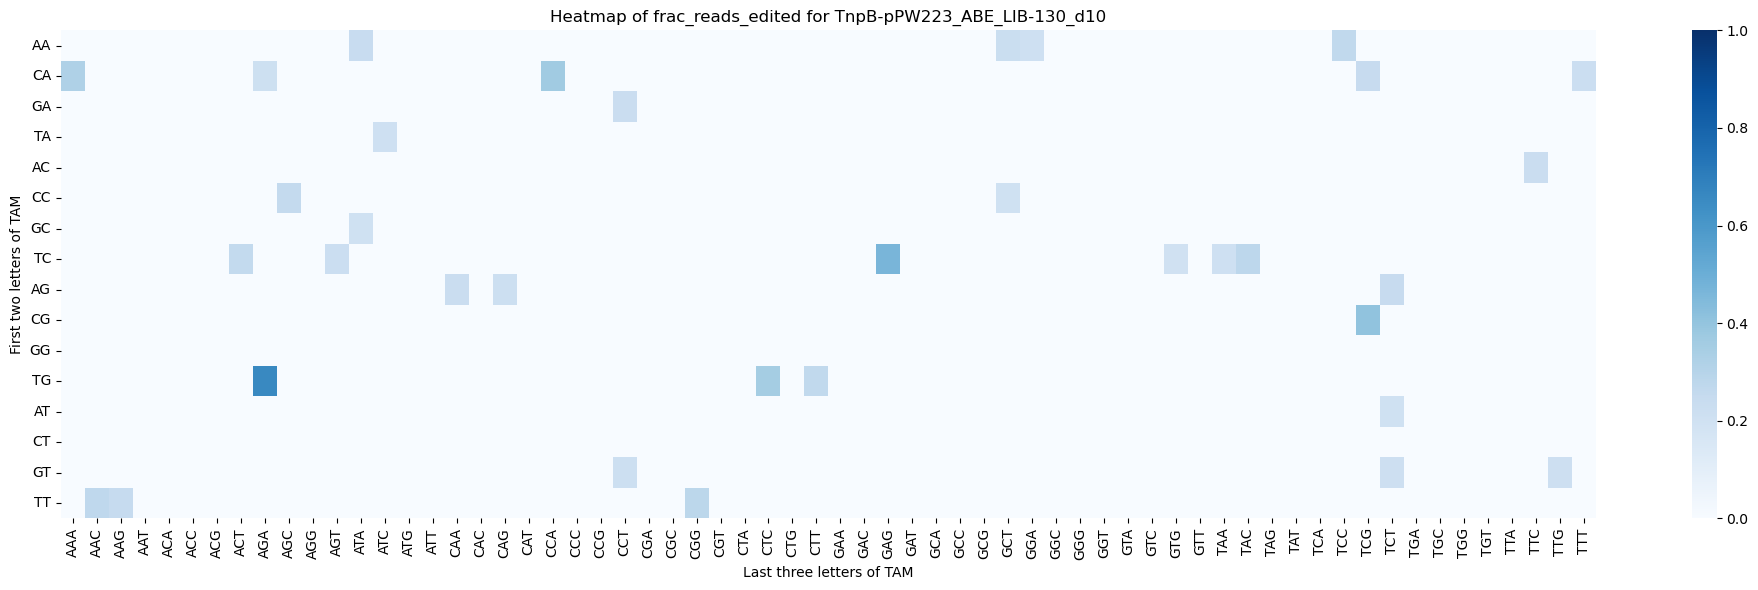

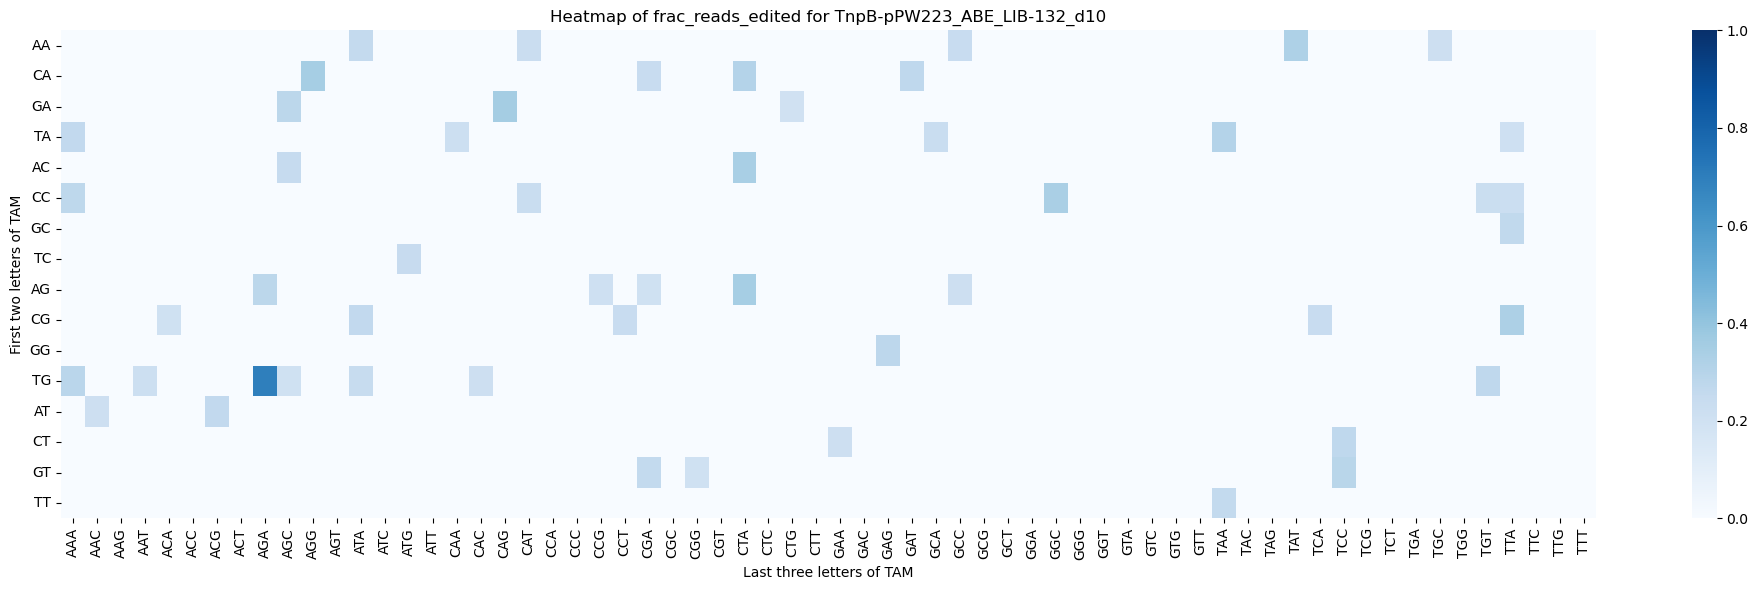

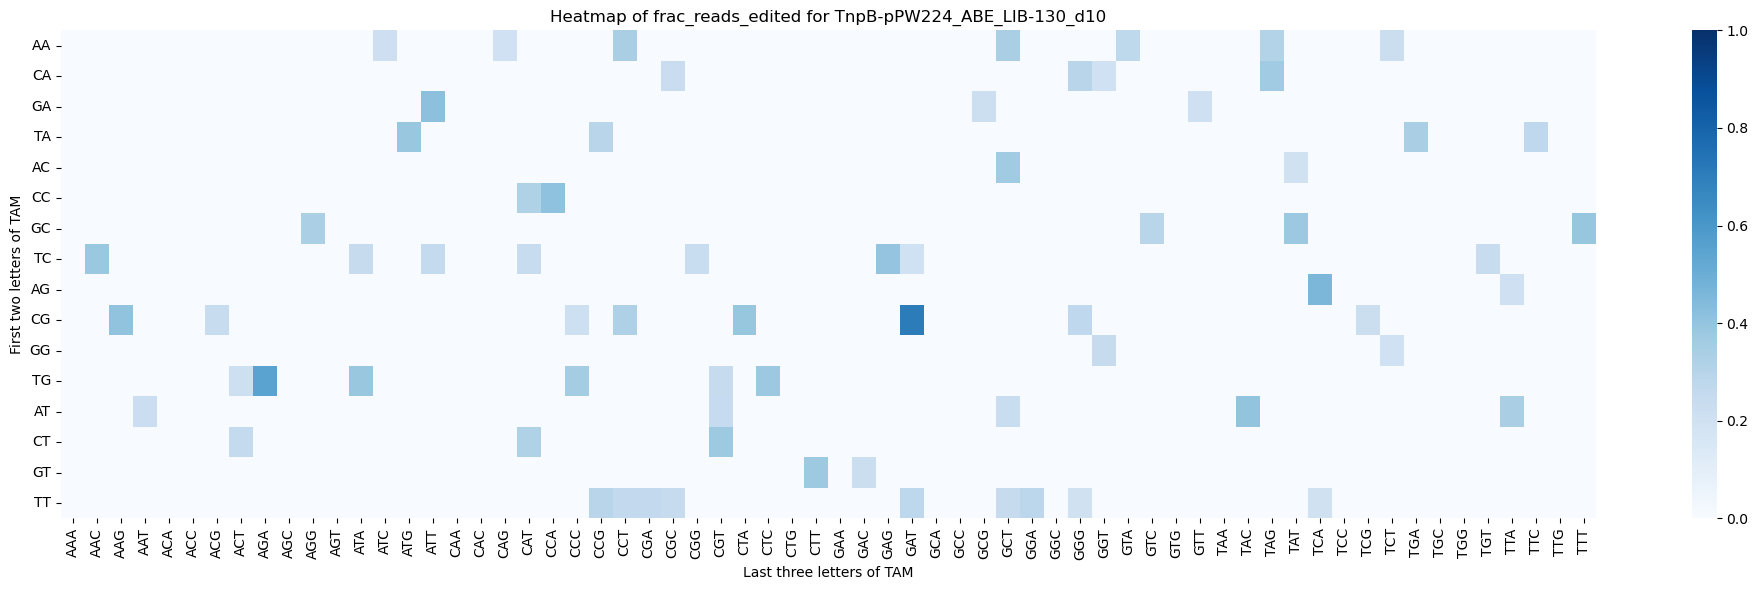

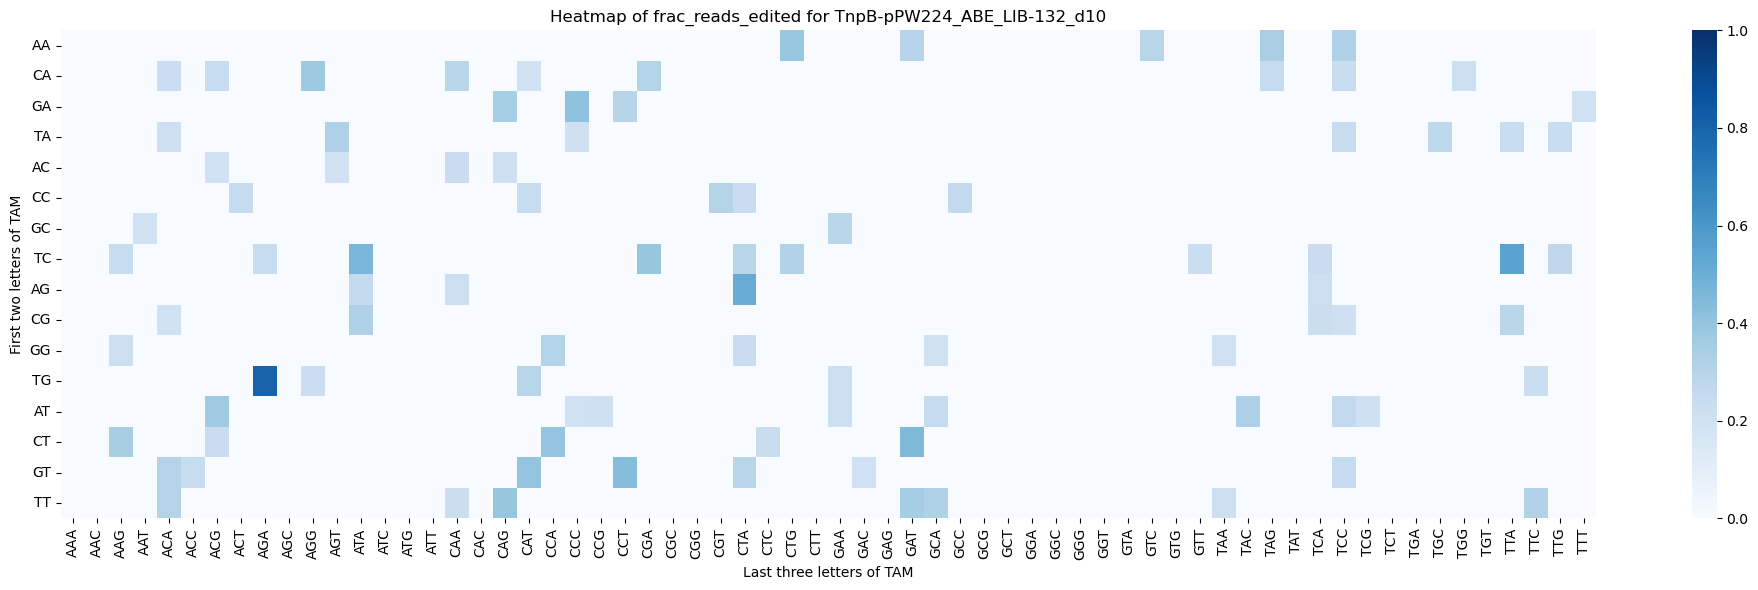

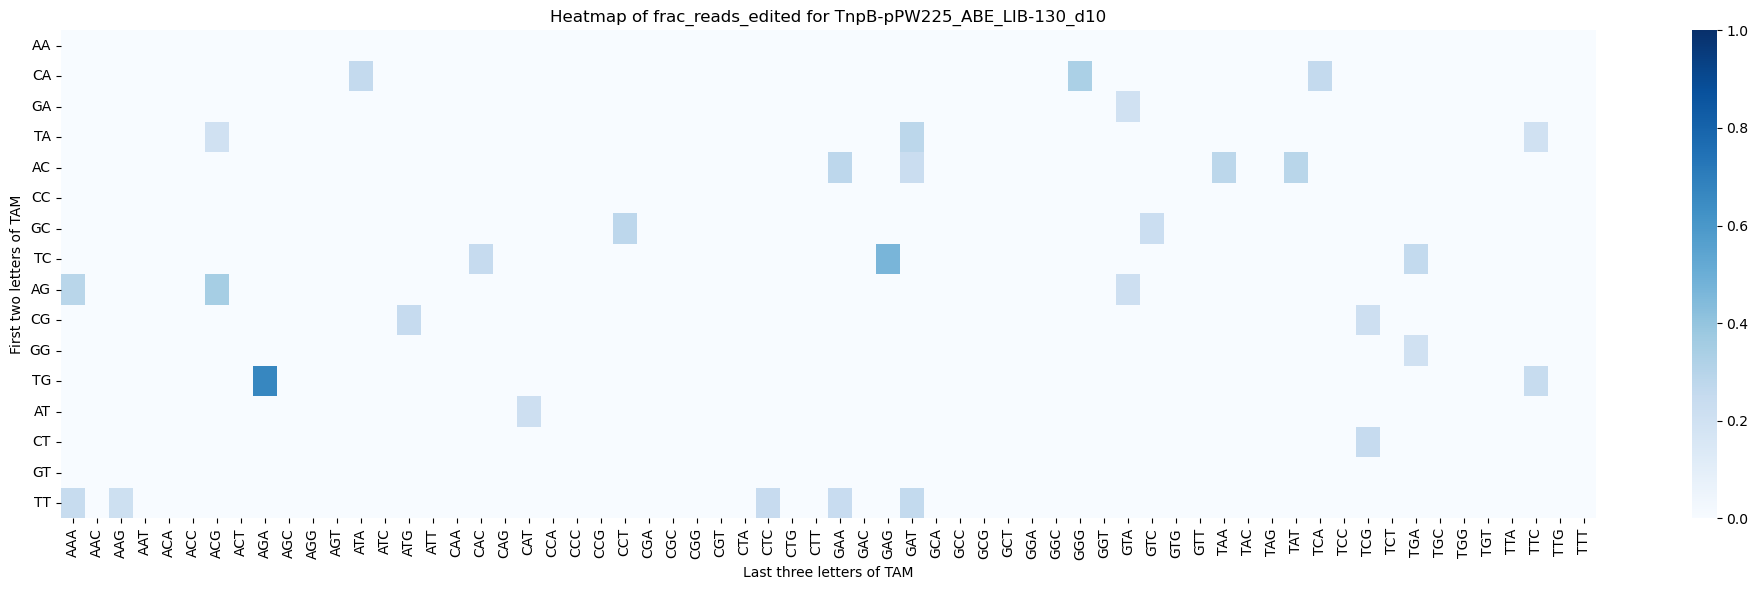

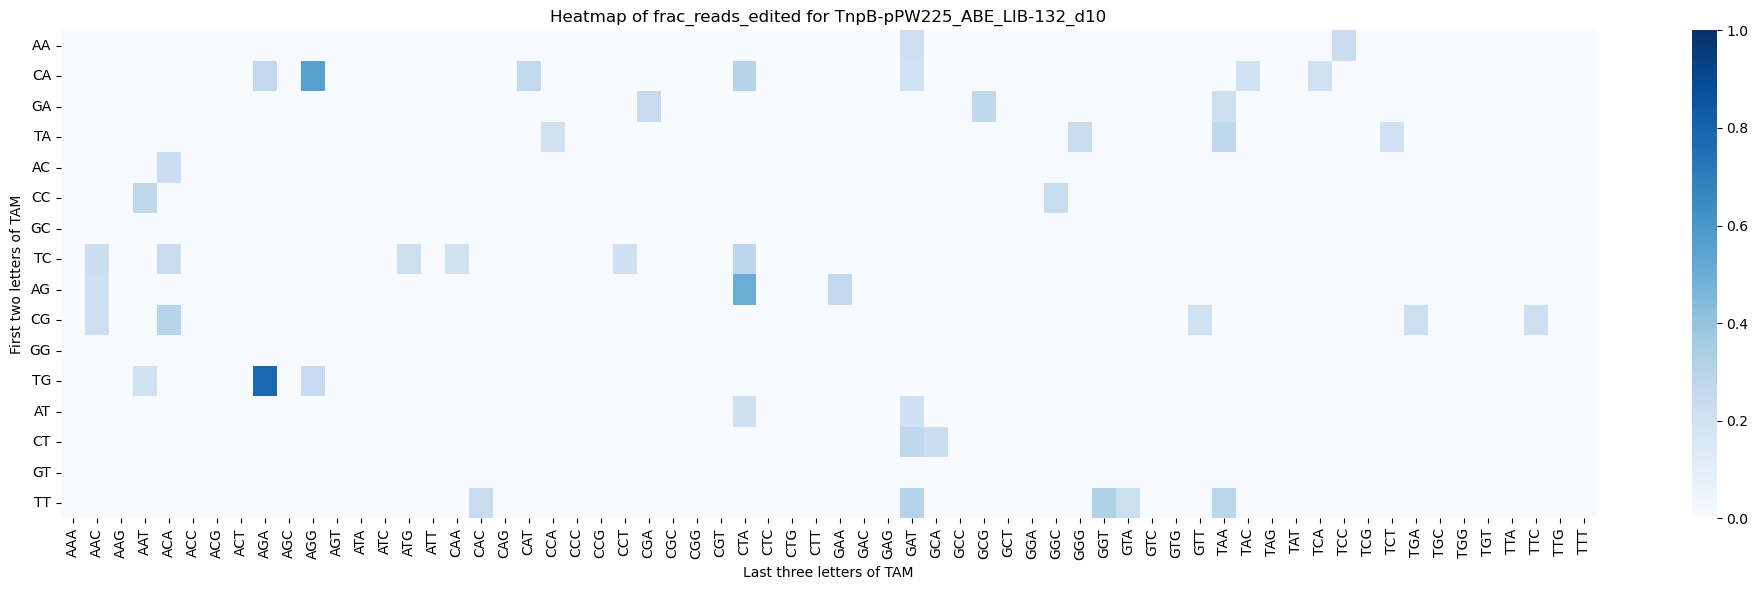

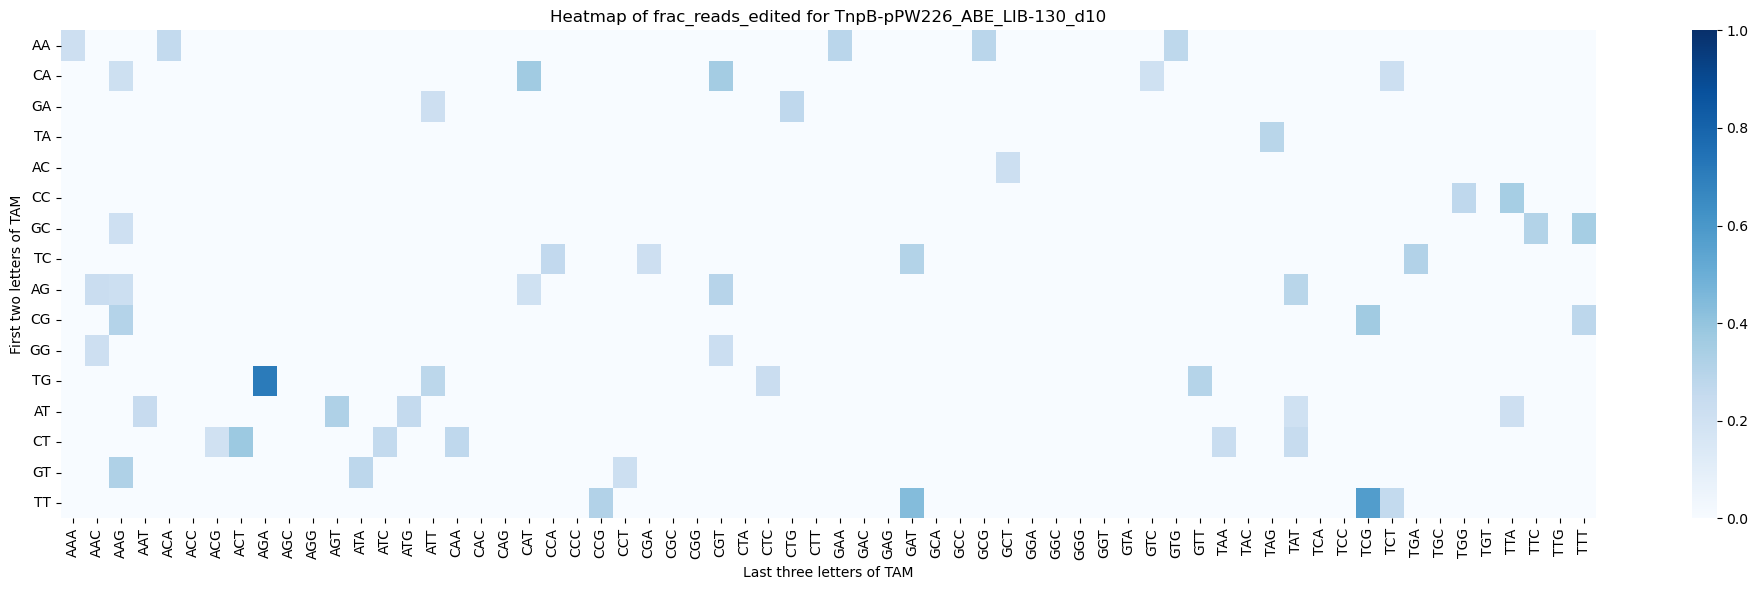

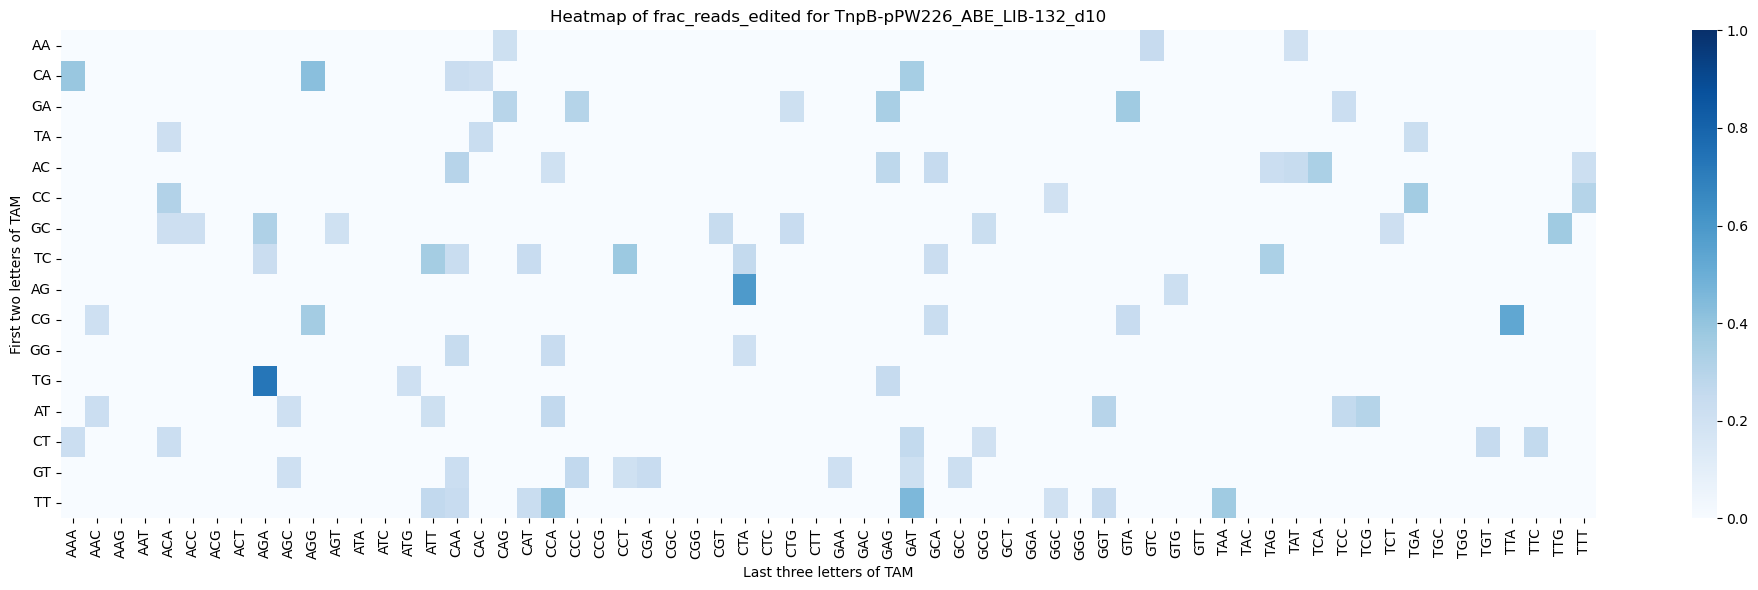

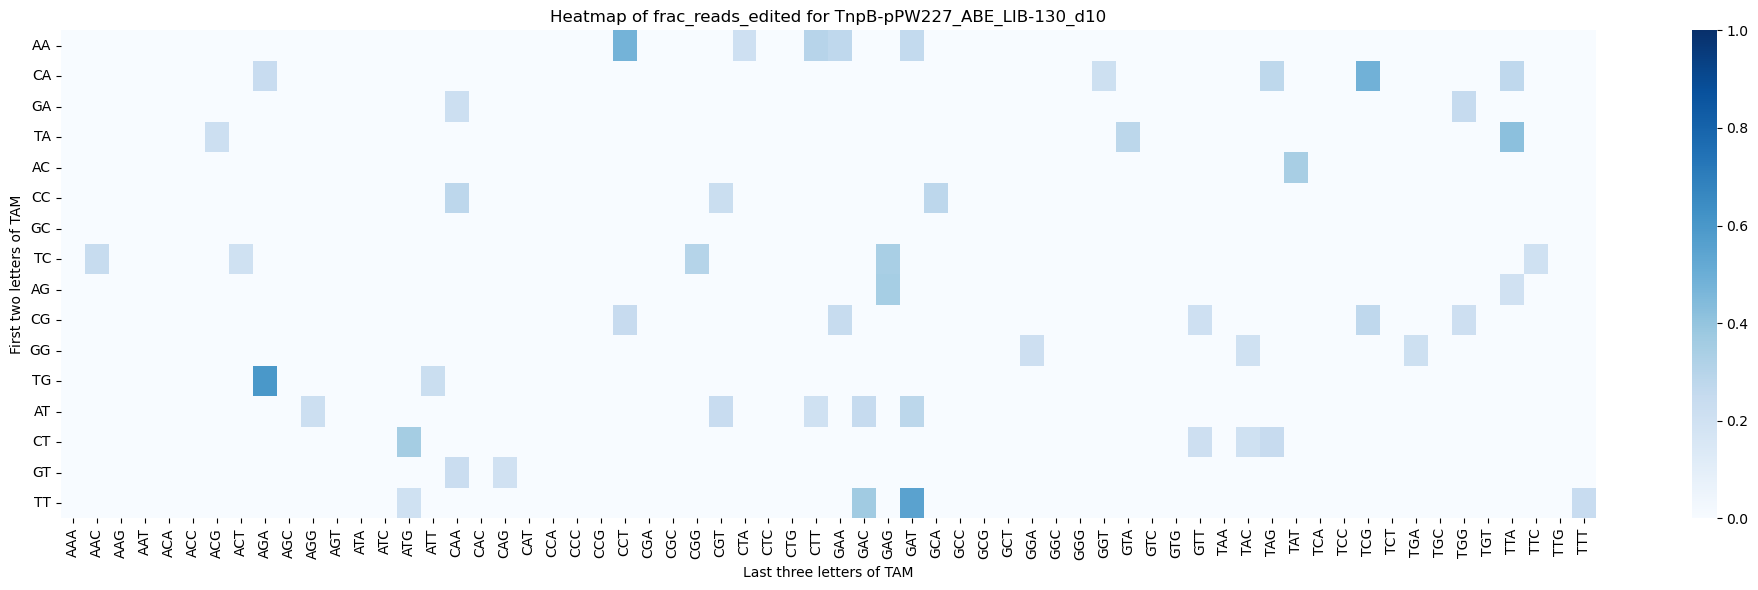

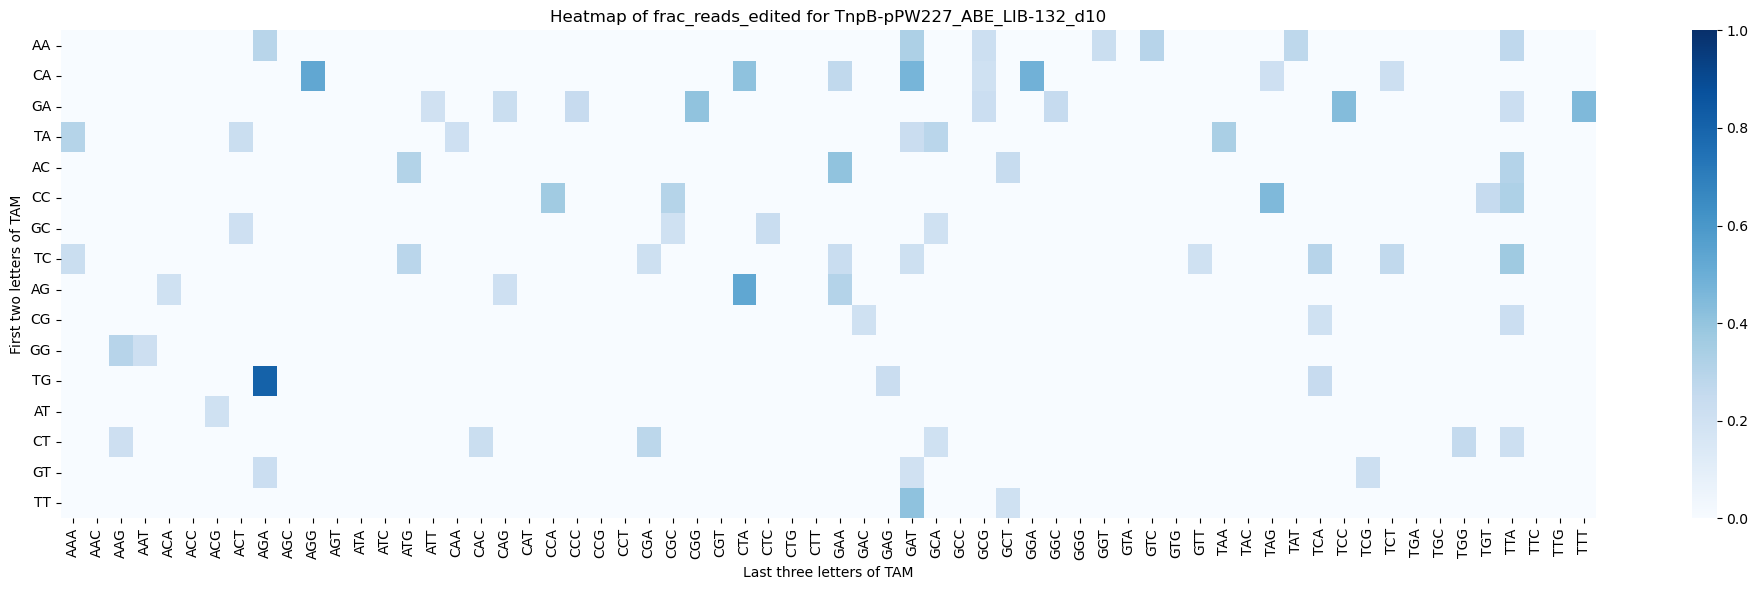

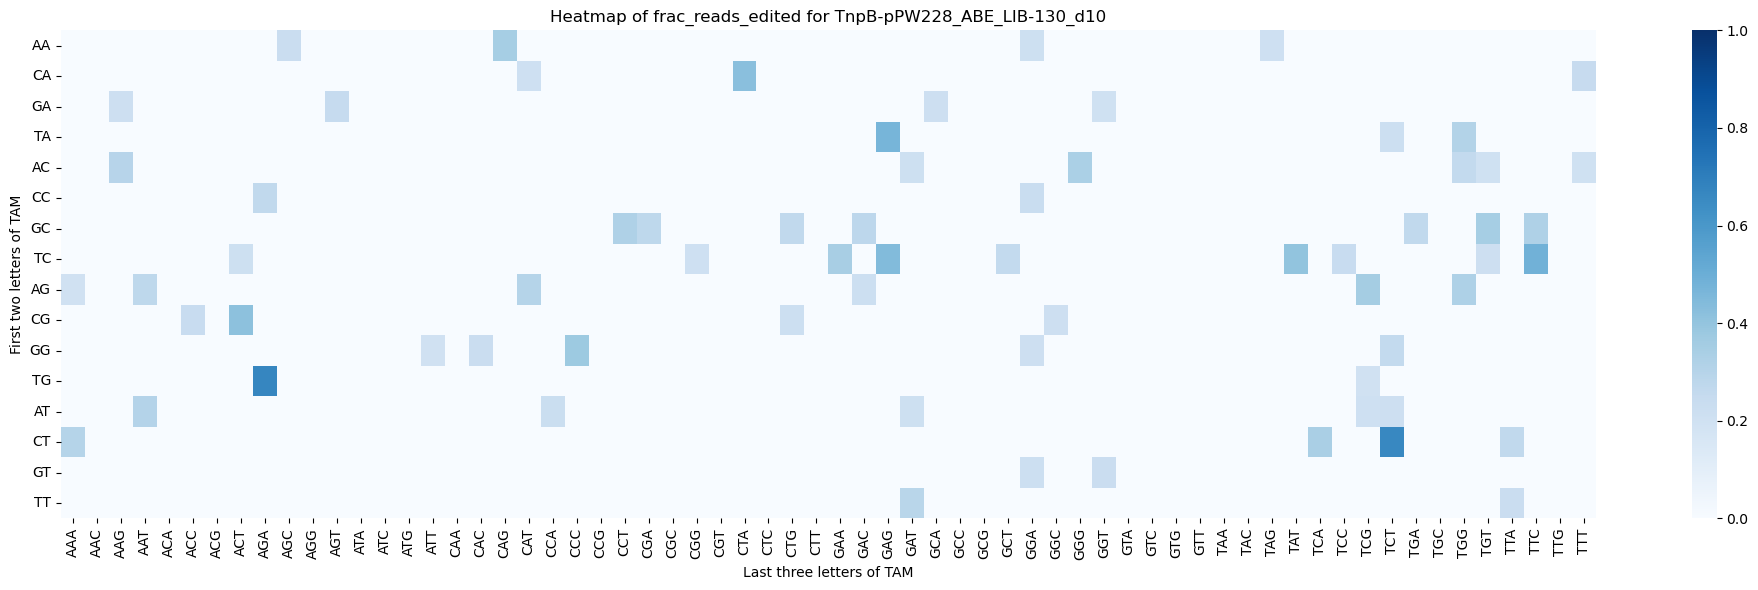

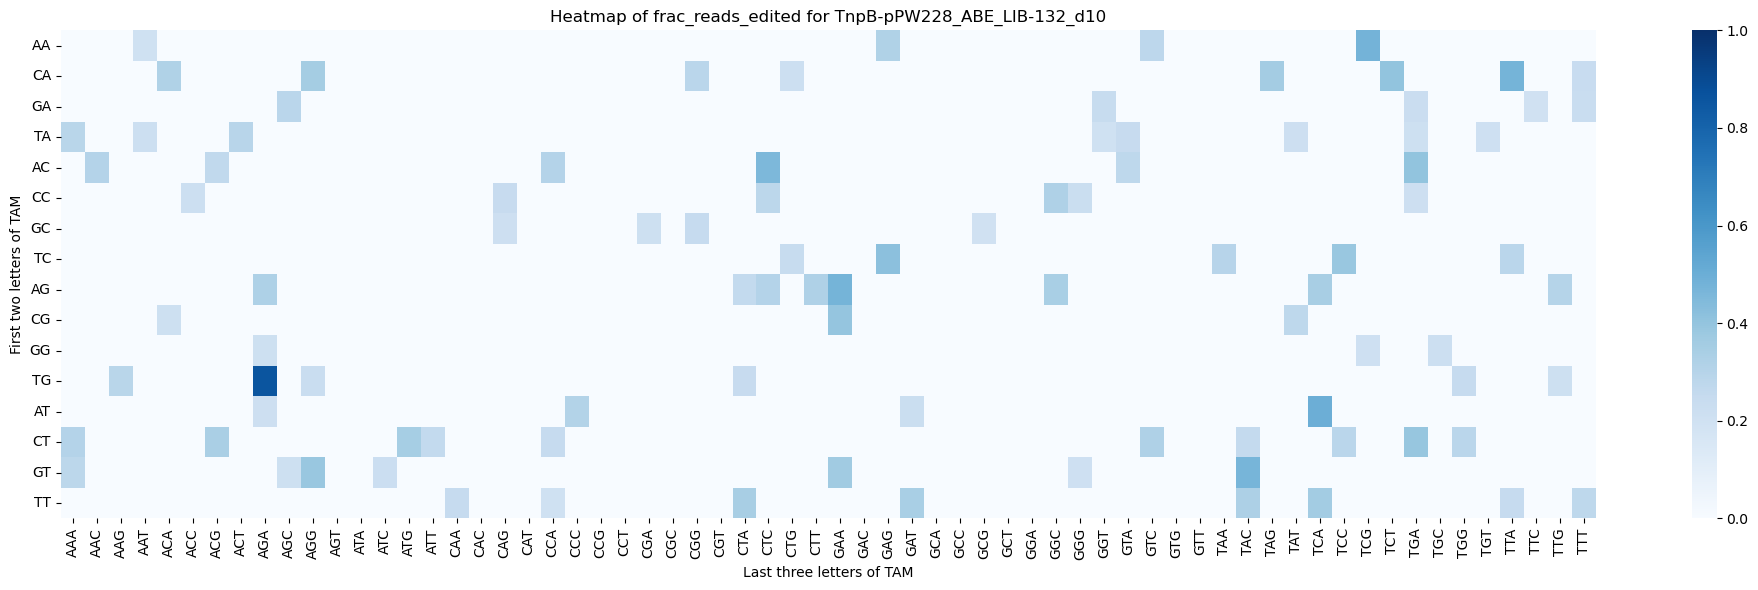

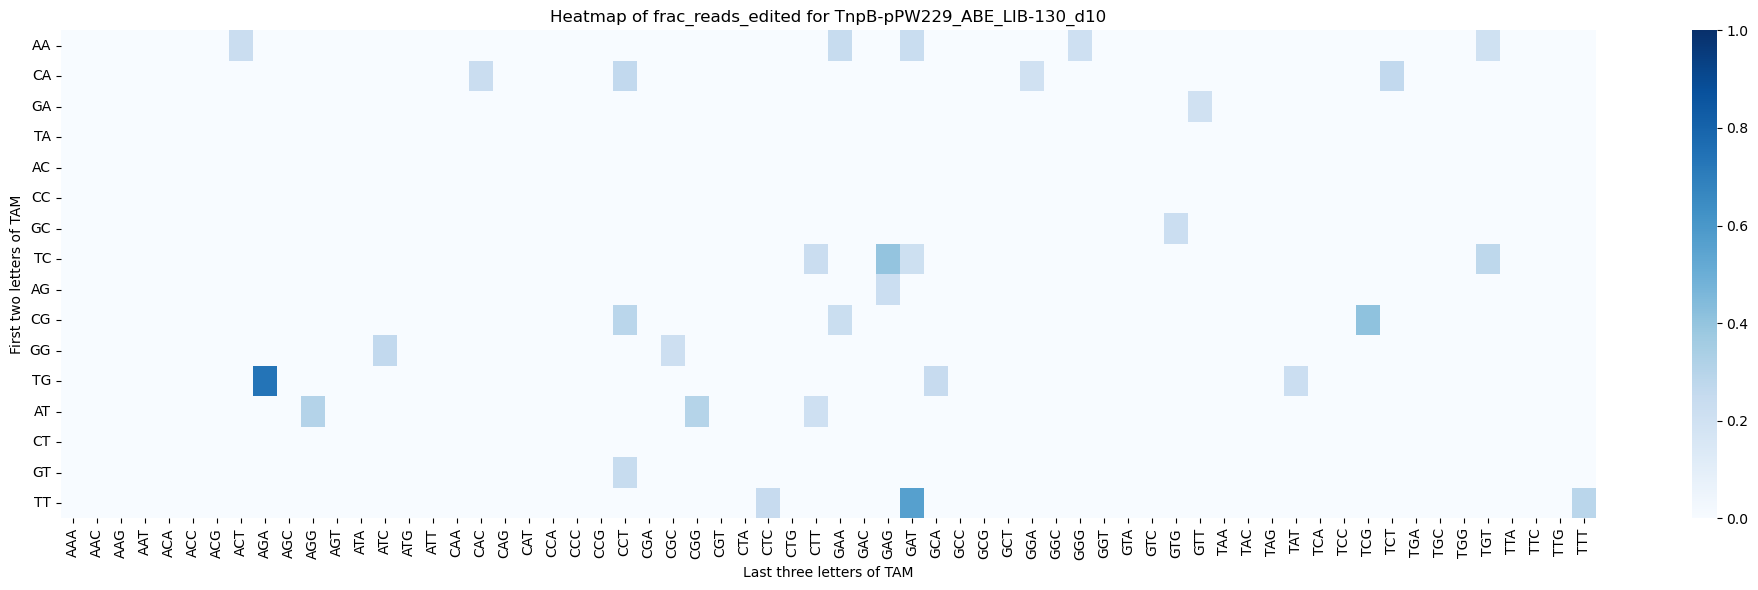

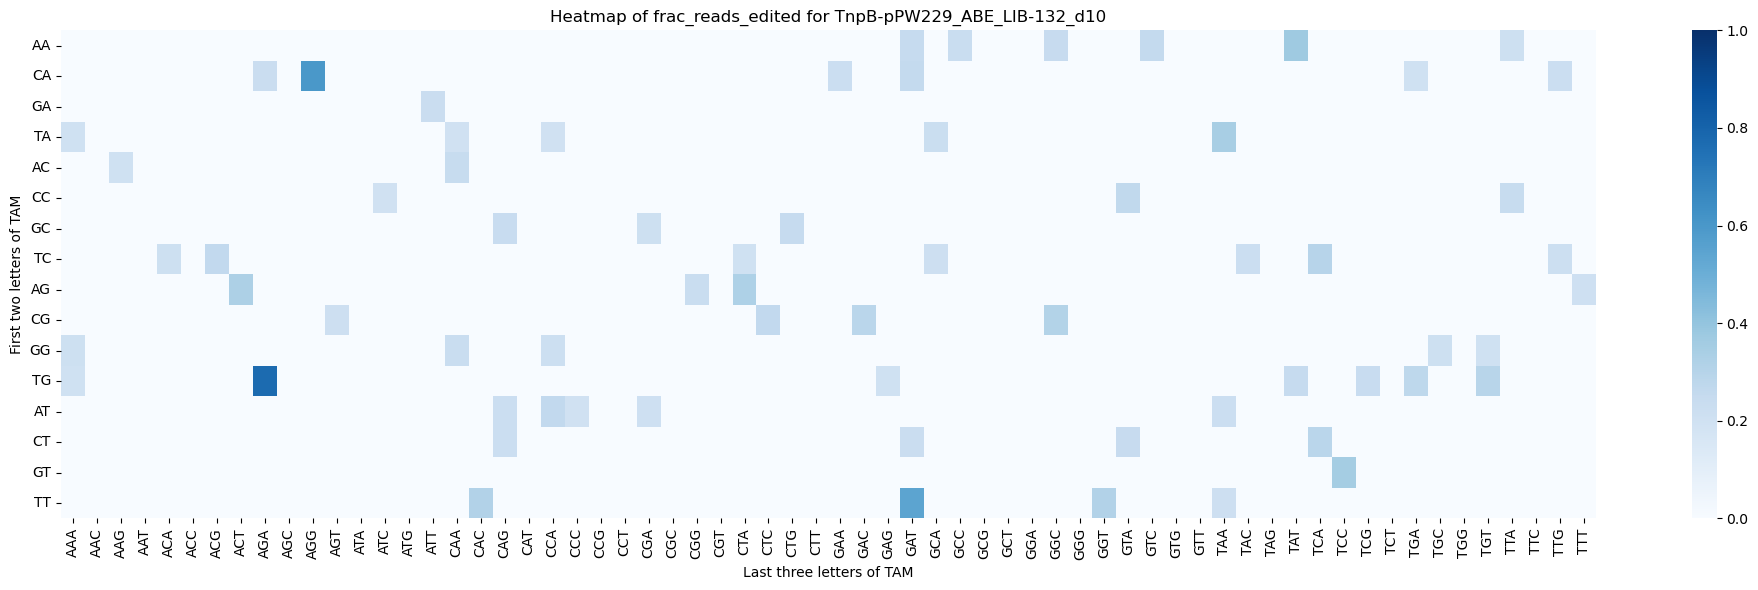

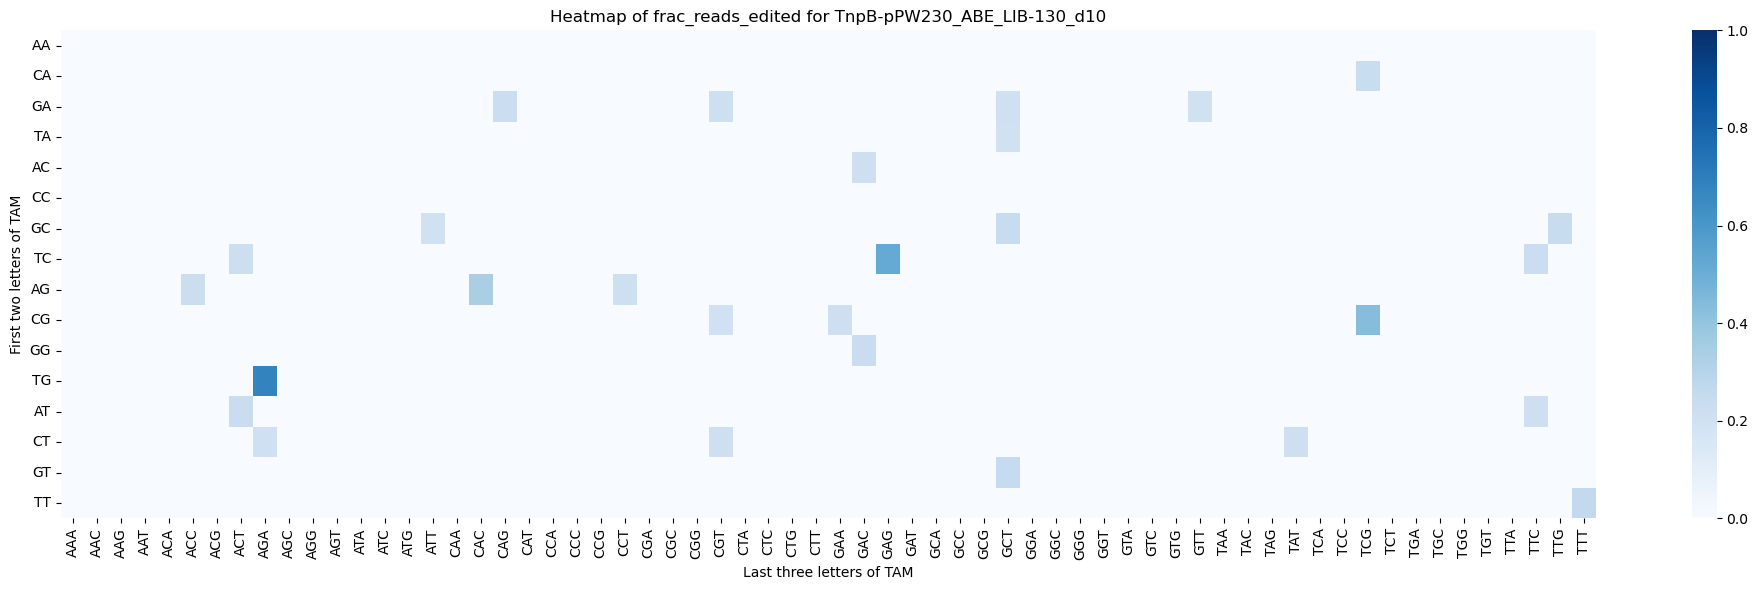

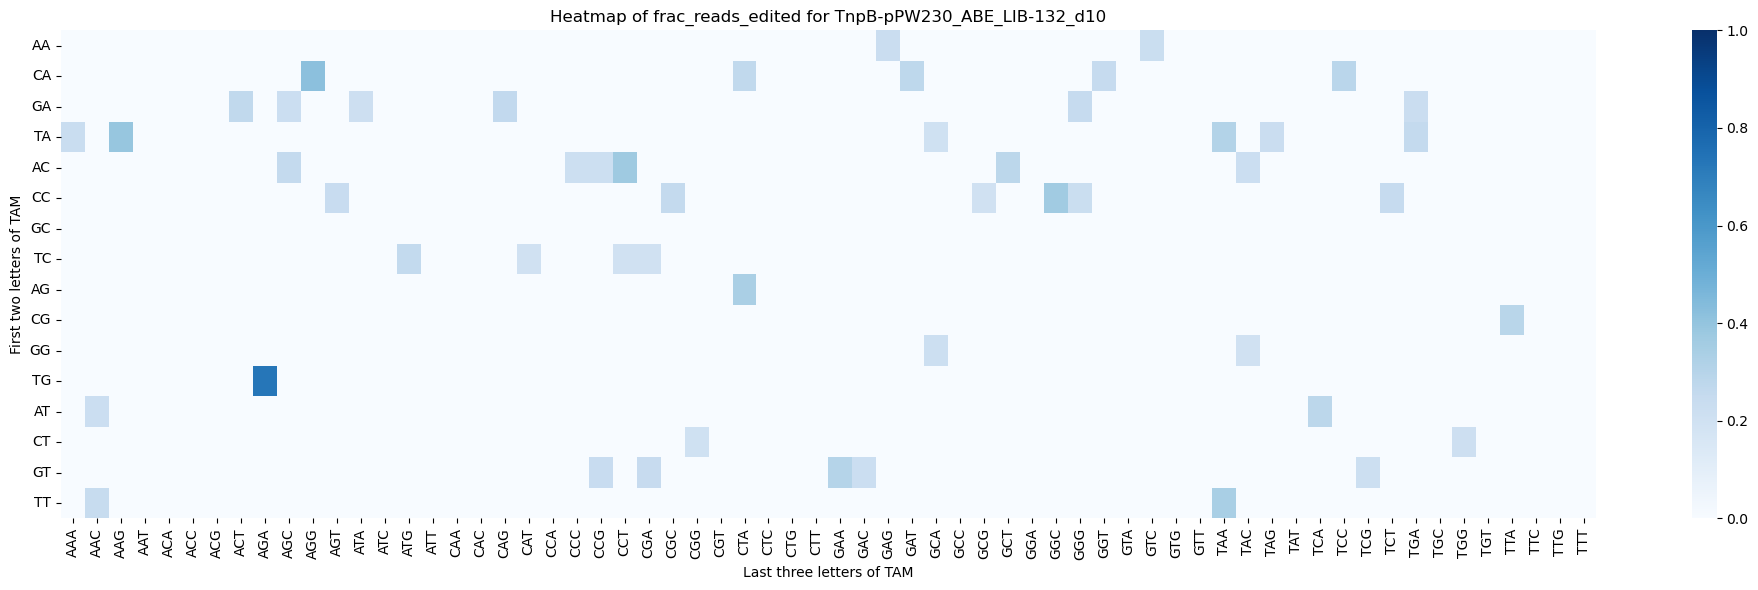

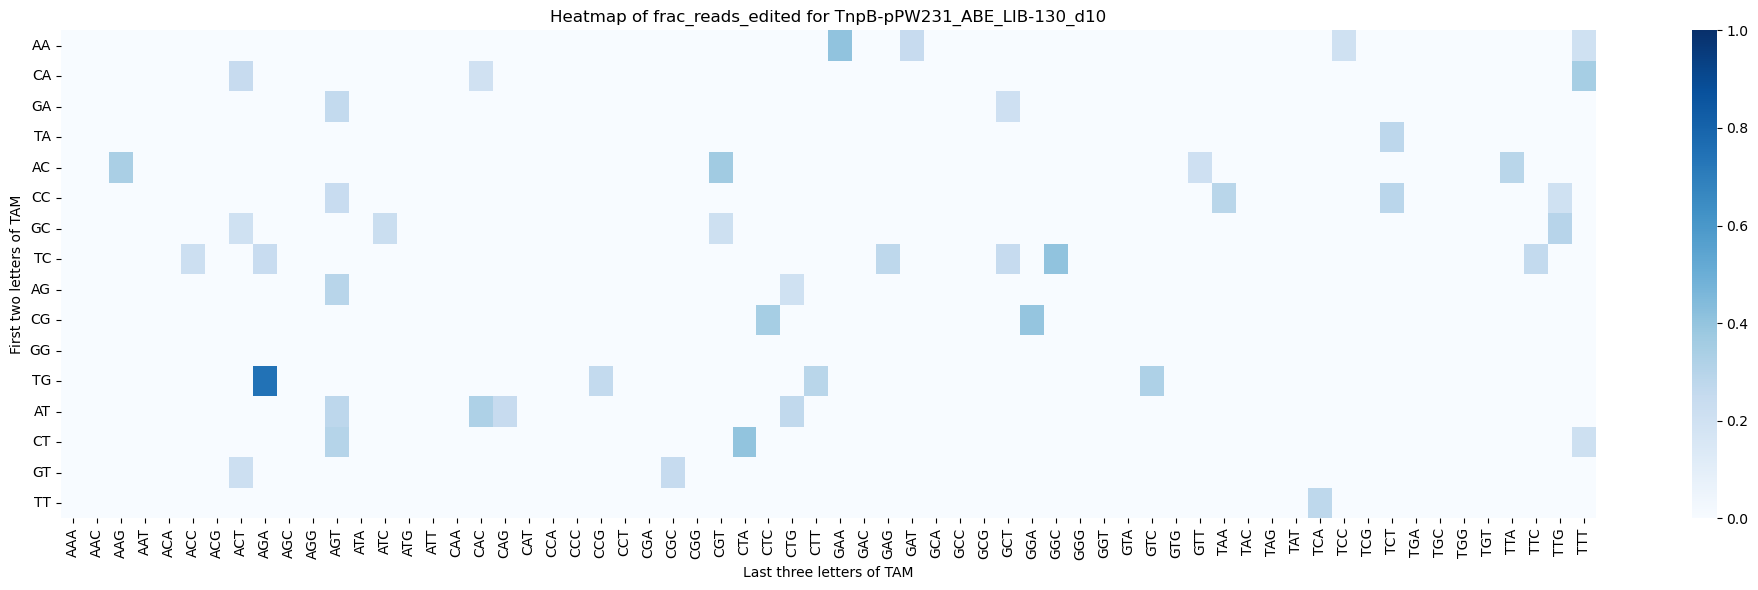

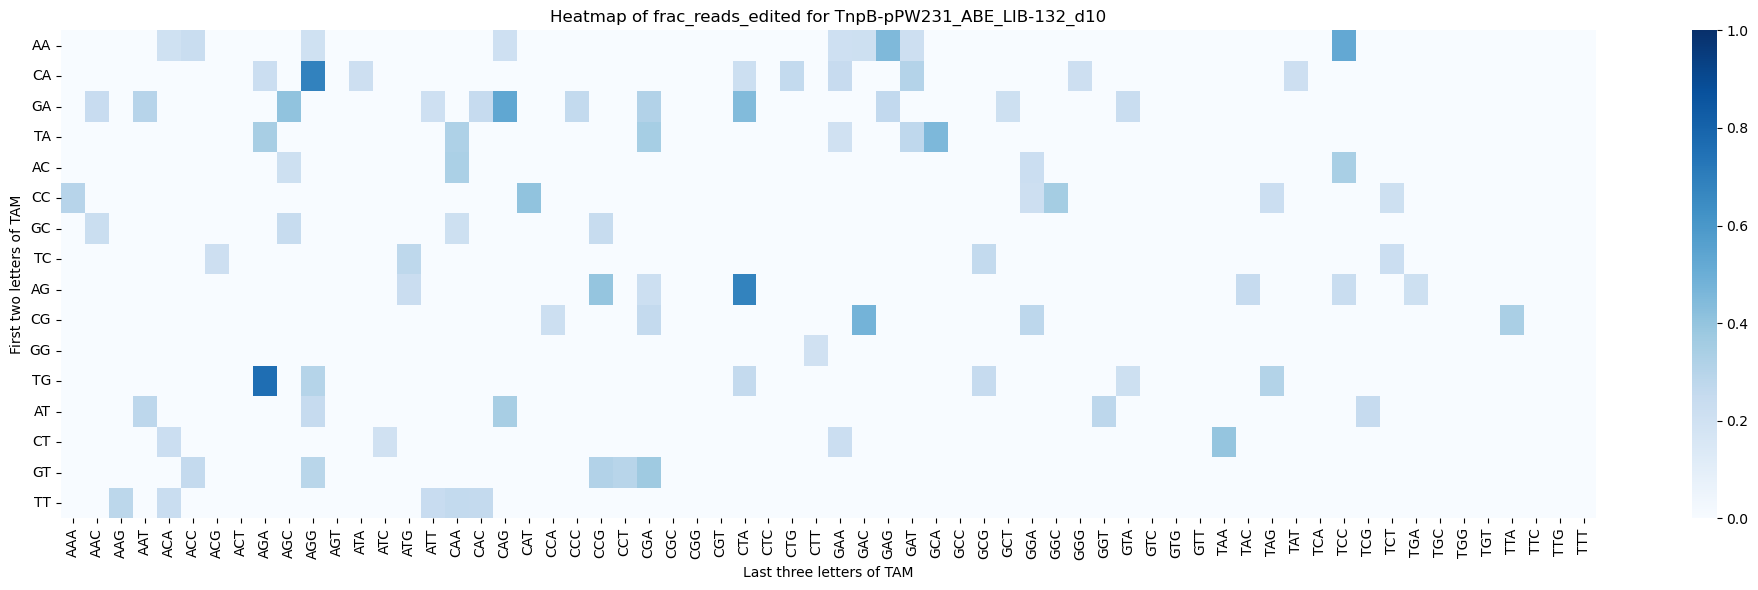

In [28]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

mean_fracs_not_normalized = all_abe_samples_reads_editedrates_not_normalized.groupby(['editor','bioreplicate','TAM', 'spacer'])['frac_reads_edited'].mean().reset_index()
mean_fracs_not_normalized.sort_values(by=['TAM',], inplace=True)
display(mean_fracs_not_normalized.head(n=3))

vis_bioreplicates=sorted(mean_fracs_not_normalized.bioreplicate.unique())
for bioreplicate in vis_bioreplicates:
    plot_heatmap_for_bioreplicate(mean_fracs_not_normalized, bioreplicate, vis_edit_thres=0.2,
                                  figsize=(20,6), cmap="Blues", save_figure=True, prefix="notNormalized")

In [29]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

In [ ]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates,_=normalize_editing_rate_reads(all_abe_samples_reads_editedrates_not_normalized,
        col_normalize_over=['spacer','TAM',"lib_section"],
        col_rate='frac_reads_edited',
        col_control='is_ctrl',
        th_ctrl_missing=1, #
        ctrl_edit_rate_thres=0.2, # 0.3
        ignore_control=['spacer', 'TAM',"lib_section"],
    )

all_abe_samples_reads_editedrates.head(n=3)


frac_low_num_read_in_control: 0.0. Drop these records
frac_unintendededit_in_control: 0.07768729641693811. Drop these records
0 out of 1629 sites are missing control editing rate. drop these sites


,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
0,TATTATATATGAGTTCACTG,AAAAA,0.046731,264,ATTATATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130,TATTATATATGAGTTCACTG
1,TATTATATATGAGTTCACTG,AAAAC,0.000000,209,ATACTGTAAAGAAGCAGAAA,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130,TATTATATATGAGTTCACTG
2,TATTATATATGAGTTCACTG,AAAAG,0.000000,650,CATTAATATGAGTTCACTGG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10_rep1,False,1,TnpB-WT_ABE_LIB-130_d10,LIB-130,TATTATATATGAGTTCACTG


In [31]:
all_abe_samples_reads_editedrates.to_csv(f"{NAS_folder}/all_abe_samples_reads_editedrates.csv")
print(f"{NAS_folder}/all_abe_samples_reads_editedrates.csv")

/mnt/G_Pharma/Users/tfang/Cell_Screen/Priscilla_A9-07_Screen/plots/all_abe_samples_reads_editedrates.csv


In [32]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

mean_fracs = all_abe_samples_reads_editedrates.groupby(['editor','bioreplicate','TAM', 'spacer'])['frac_reads_edited'].mean().reset_index()
mean_fracs.sort_values(by=['TAM',], inplace=True)
mean_fracs.sort_values(by=['editor',], inplace=True)
mean_fracs

,editor,bioreplicate,TAM,spacer,frac_reads_edited
0,TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10,AAAAA,TATTATATATGAGTTCACTG,0.036881
1307,TnpB-WT_ABE,TnpB-WT_ABE_LIB-132_d10,GCTCC,ATACTGTAAAGAAGCAGAAA,0.004606
932,TnpB-WT_ABE,TnpB-WT_ABE_LIB-132_d10,ACTGC,ATACTGTAAAGAAGCAGAAA,0.008379
515,TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10,GCTCC,TATTATATATGAGTTCACTG,0.002294
514,TnpB-WT_ABE,TnpB-WT_ABE_LIB-130_d10,GCTCA,TATTATATATGAGTTCACTG,0.011388
...,...,...,...,...,...
20926,TnpB-pPW231_ABE,TnpB-pPW231_ABE_LIB-132_d10,GTAGT,ATACTGTAAAGAAGCAGAAA,0.053578
20140,TnpB-pPW231_ABE,TnpB-pPW231_ABE_LIB-130_d10,GTATA,TATTATATATGAGTTCACTG,0.030804
20458,TnpB-pPW231_ABE,TnpB-pPW231_ABE_LIB-132_d10,ACCTG,ATACTGTAAAGAAGCAGAAA,0.012990
20924,TnpB-pPW231_ABE,TnpB-pPW231_ABE_LIB-132_d10,GTAGA,ATACTGTAAAGAAGCAGAAA,0.000000


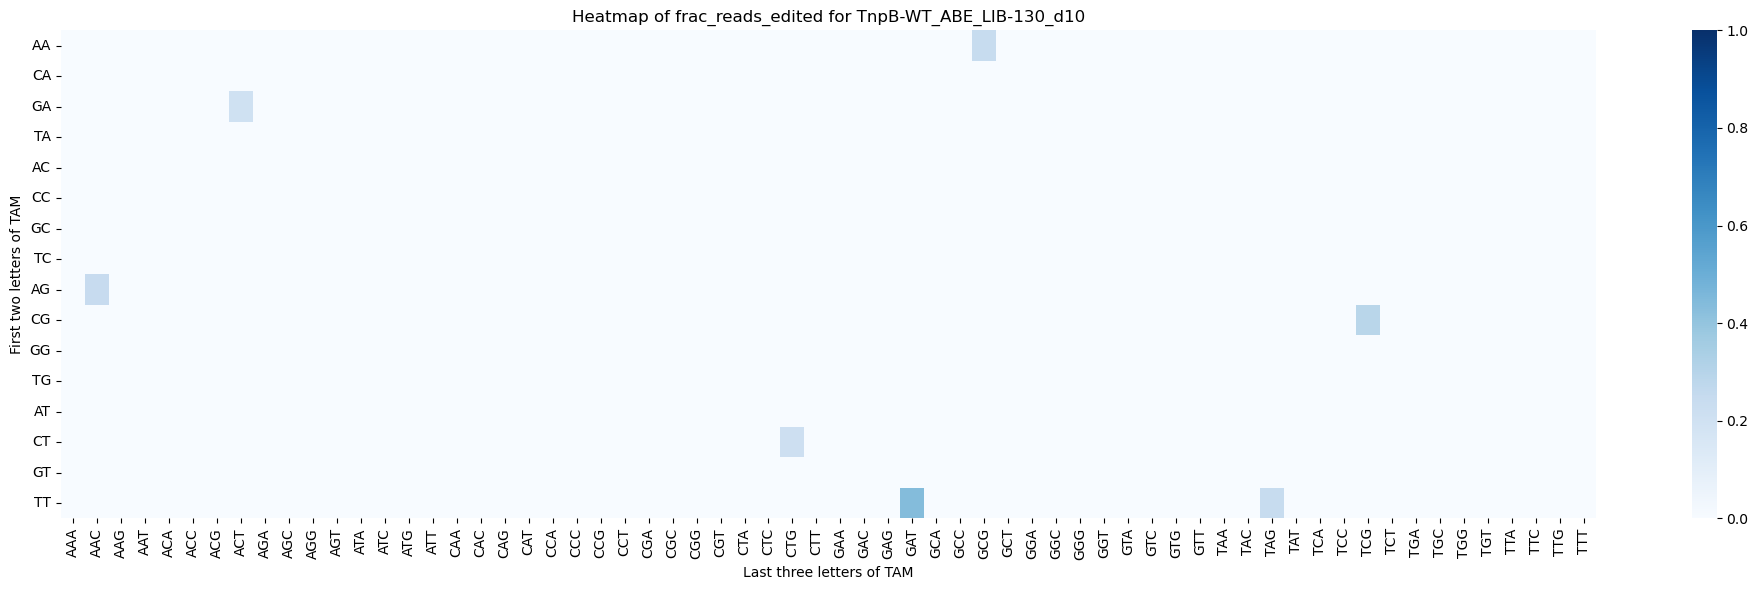

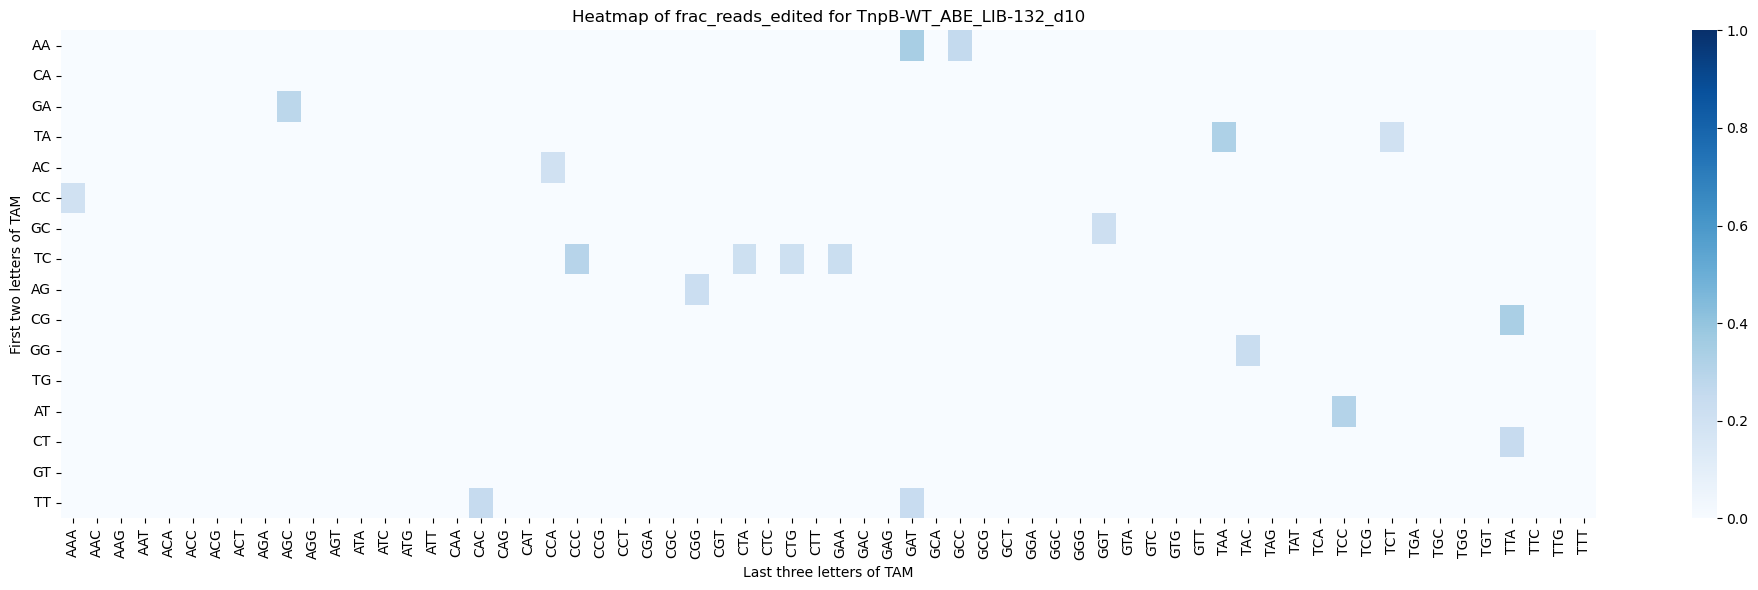

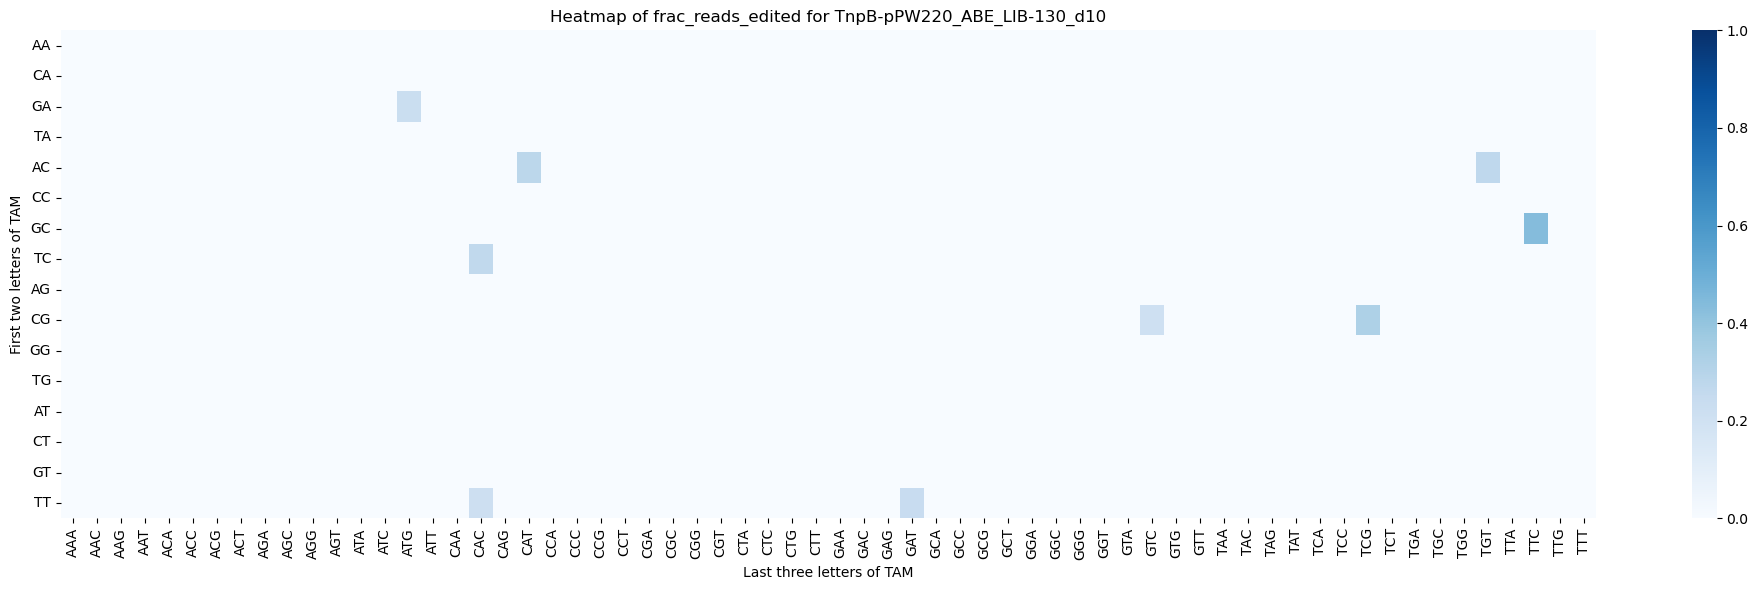

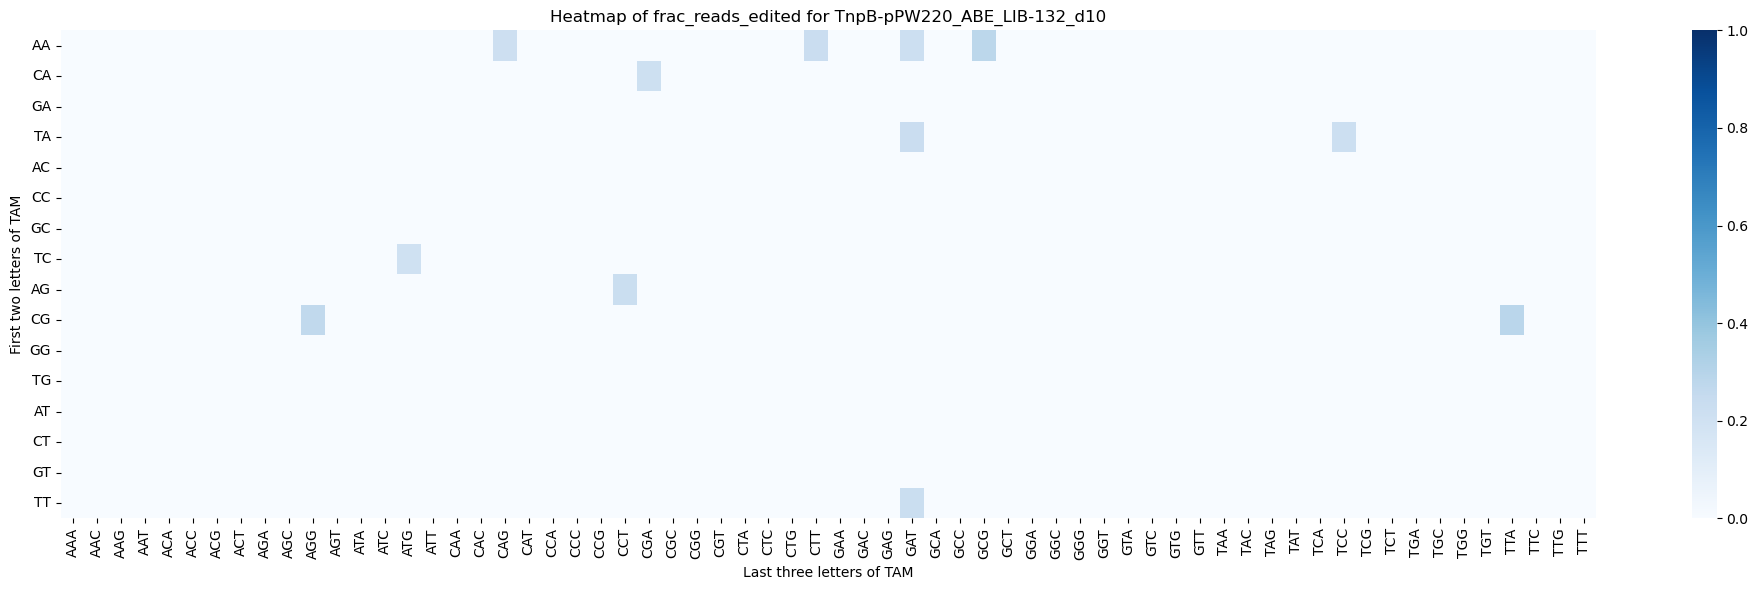

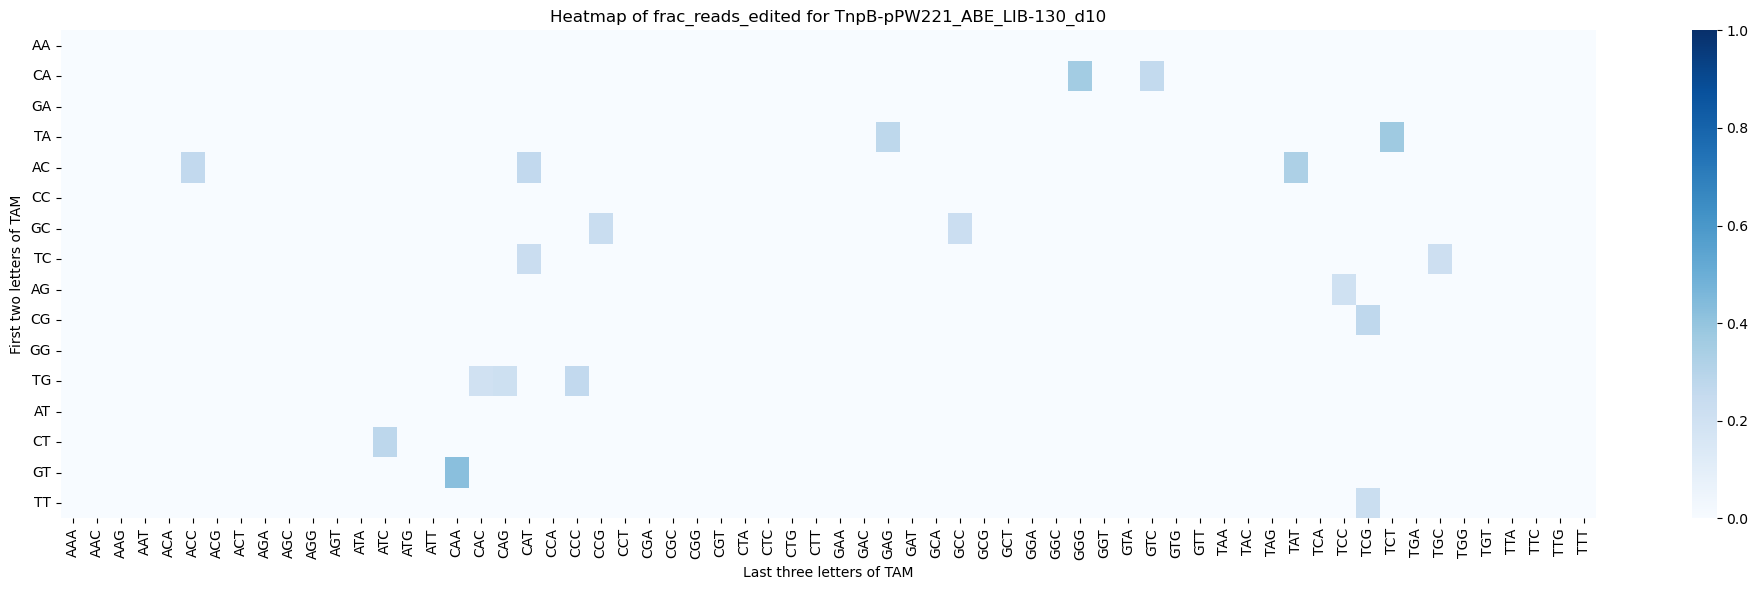

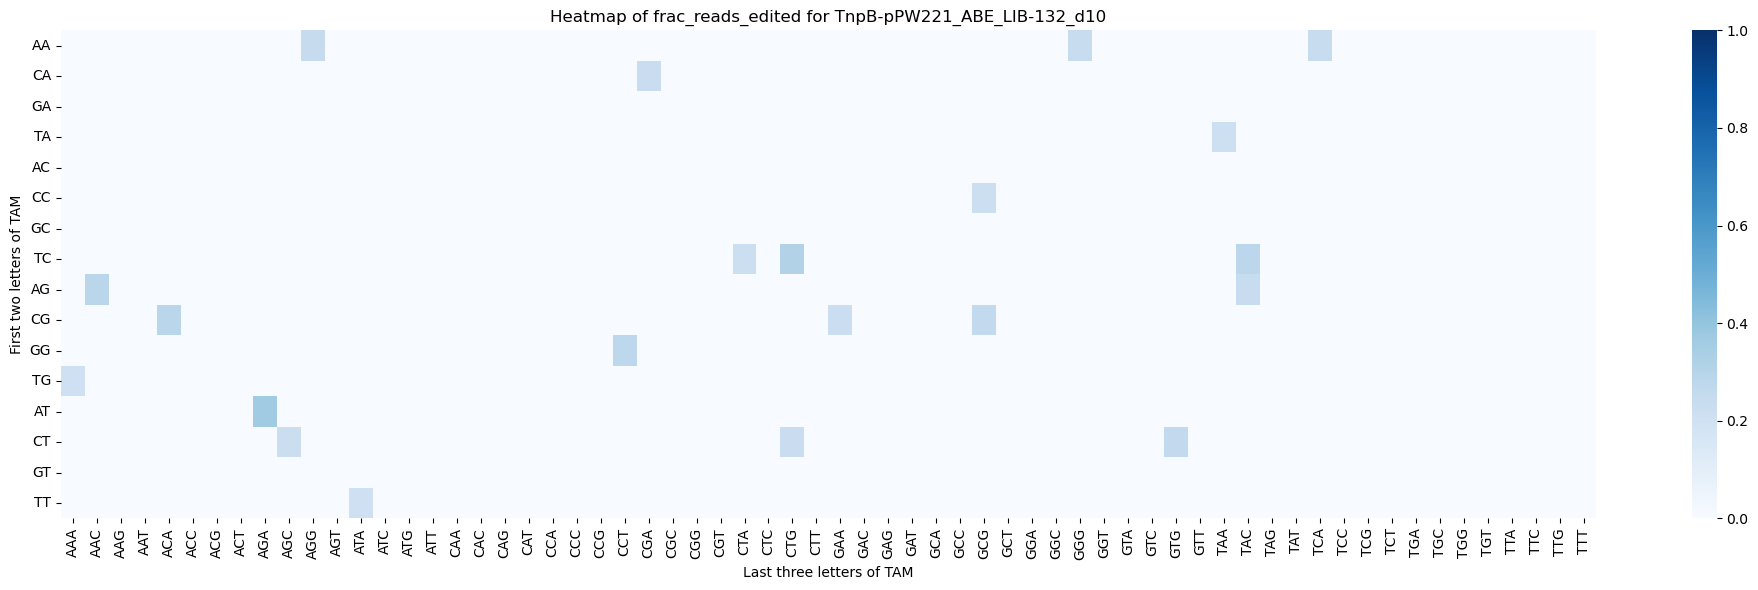

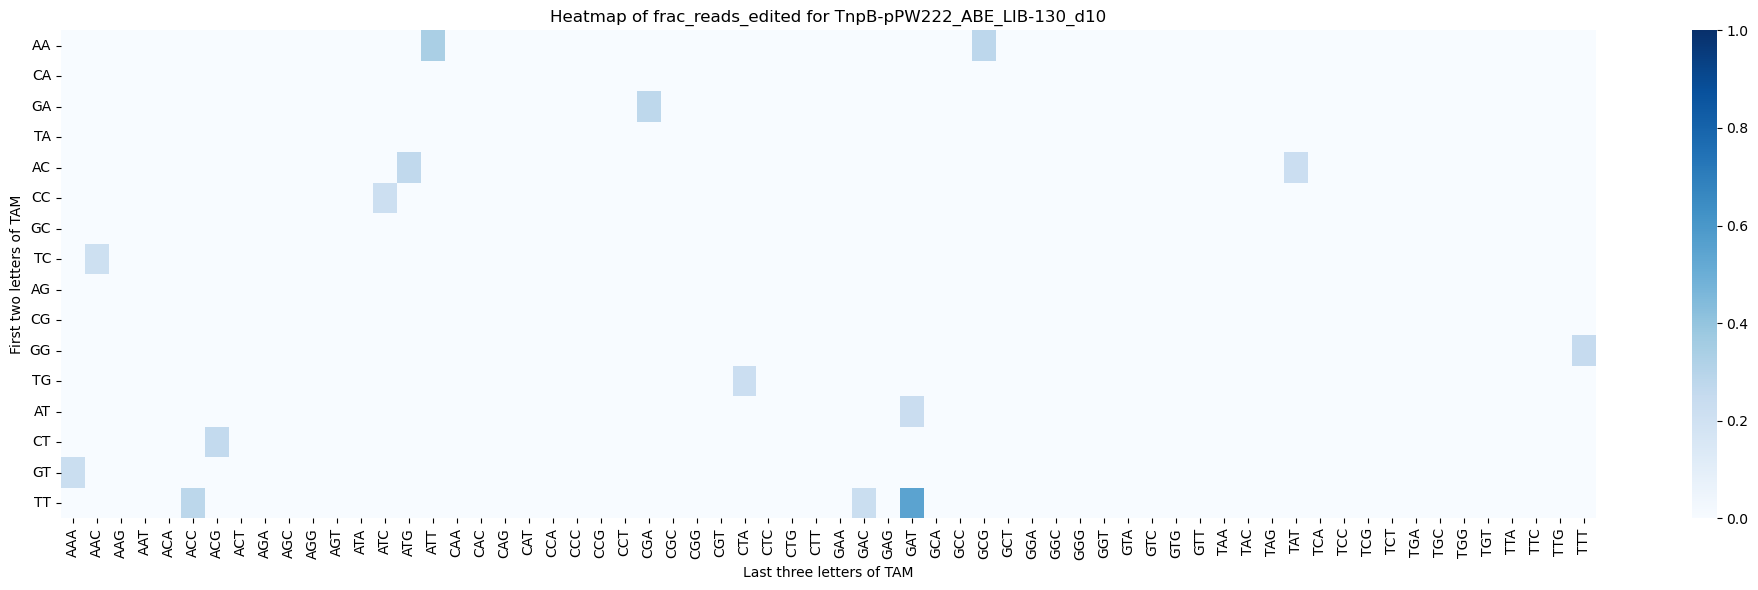

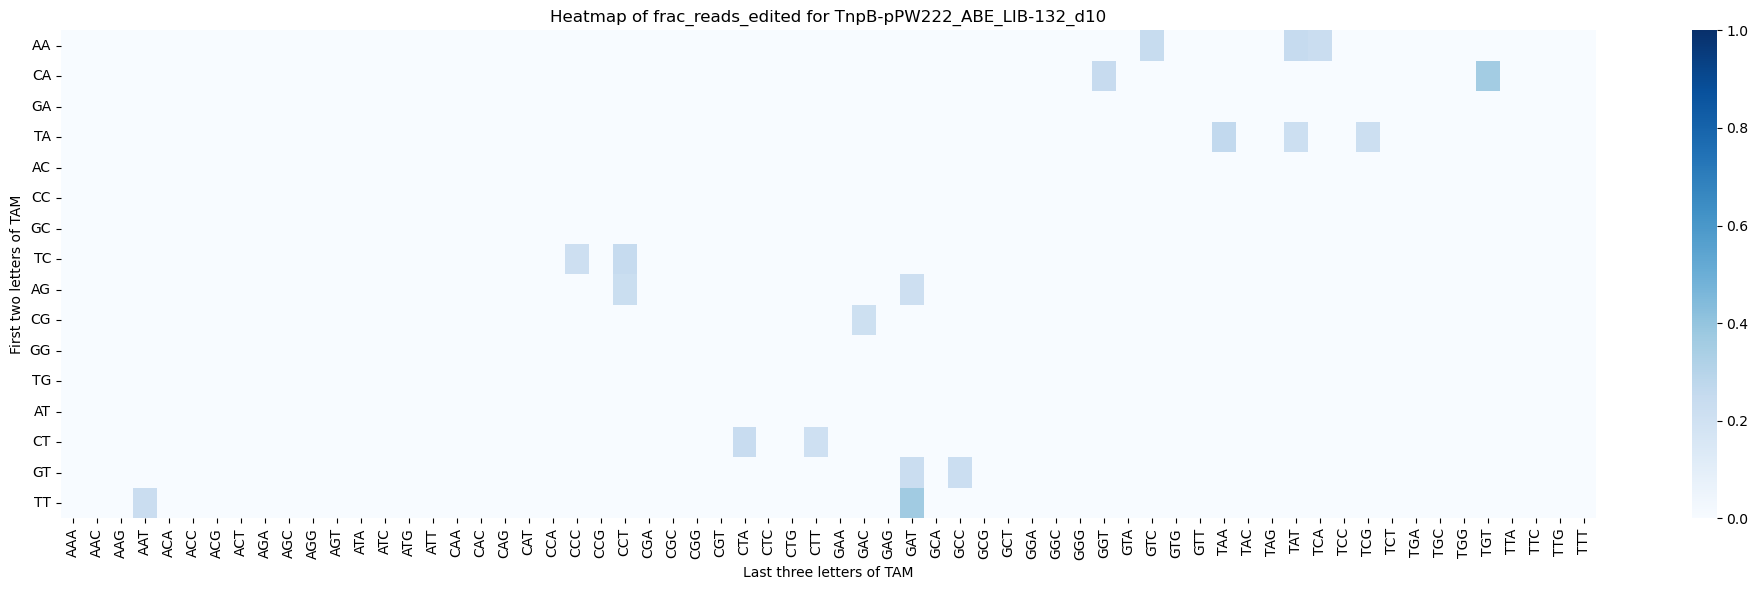

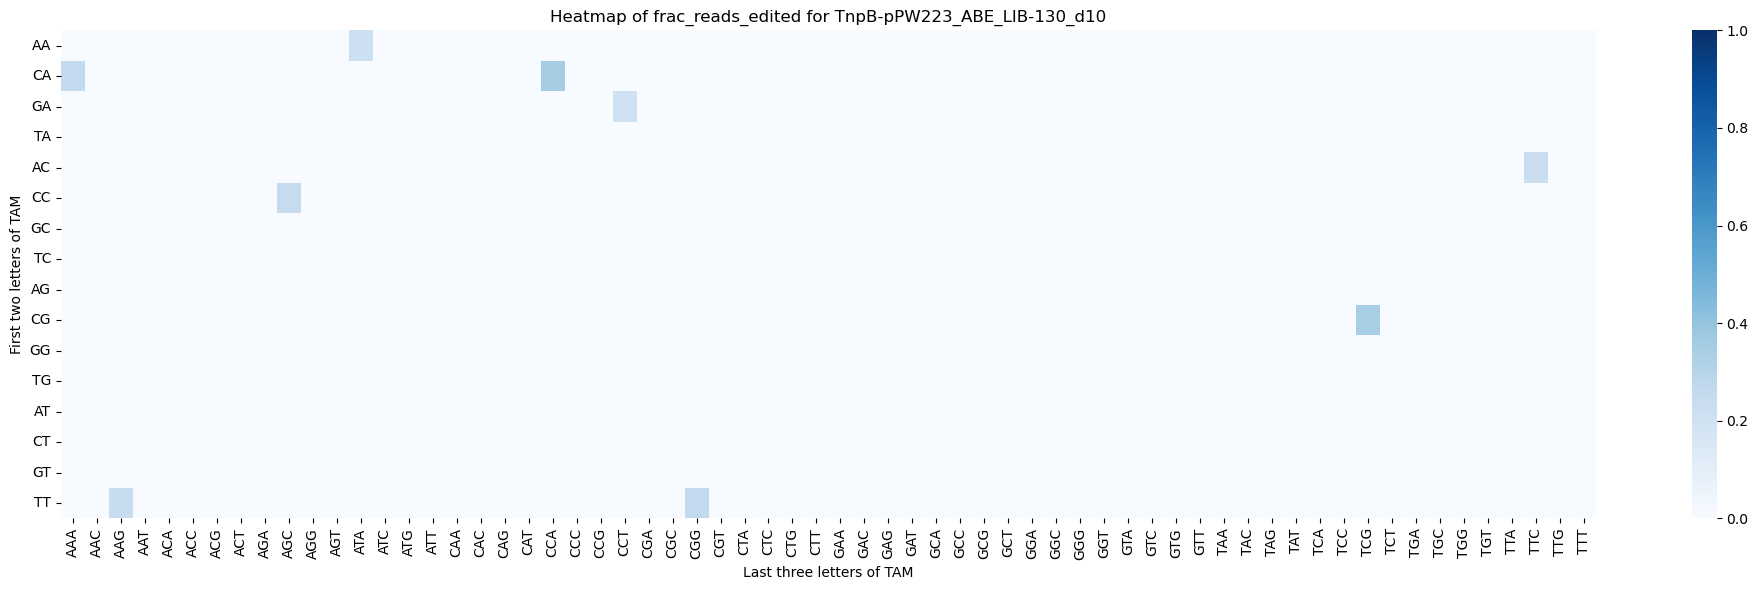

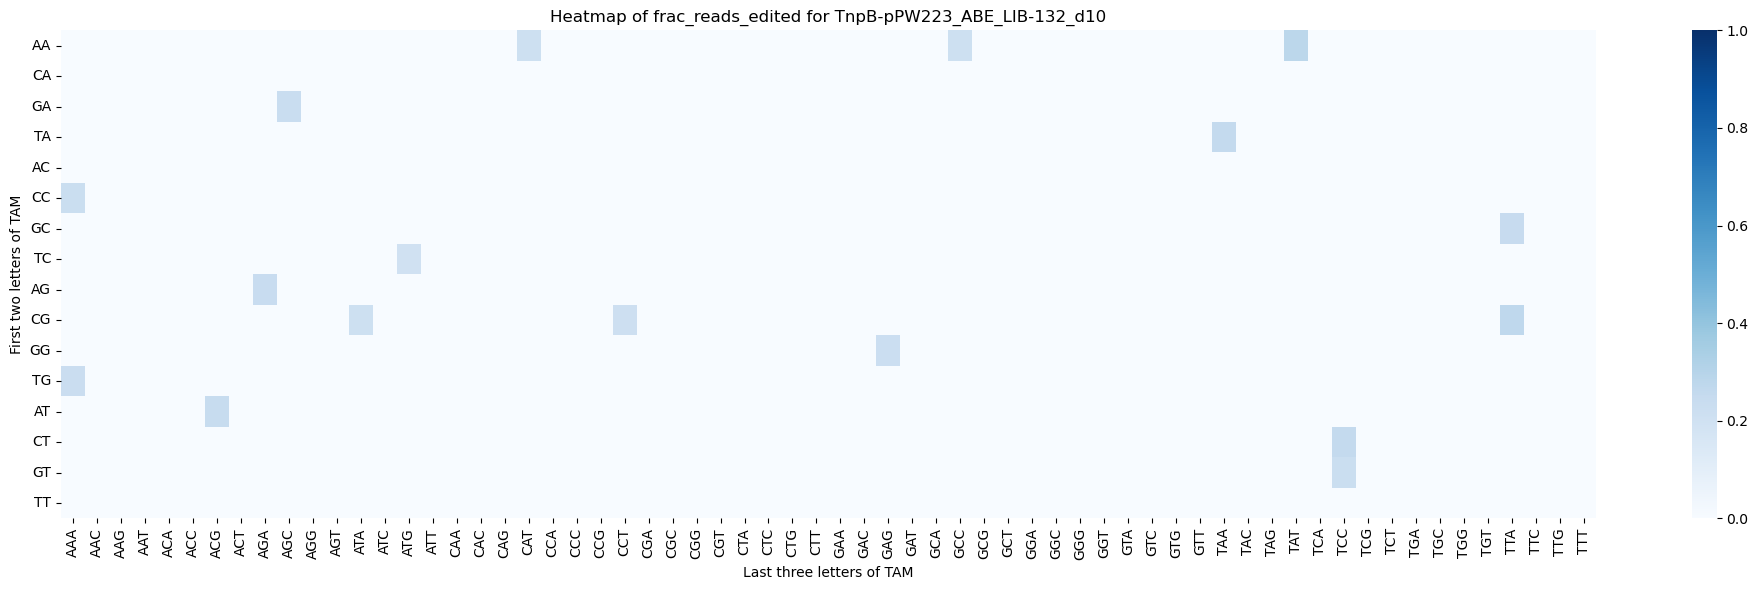

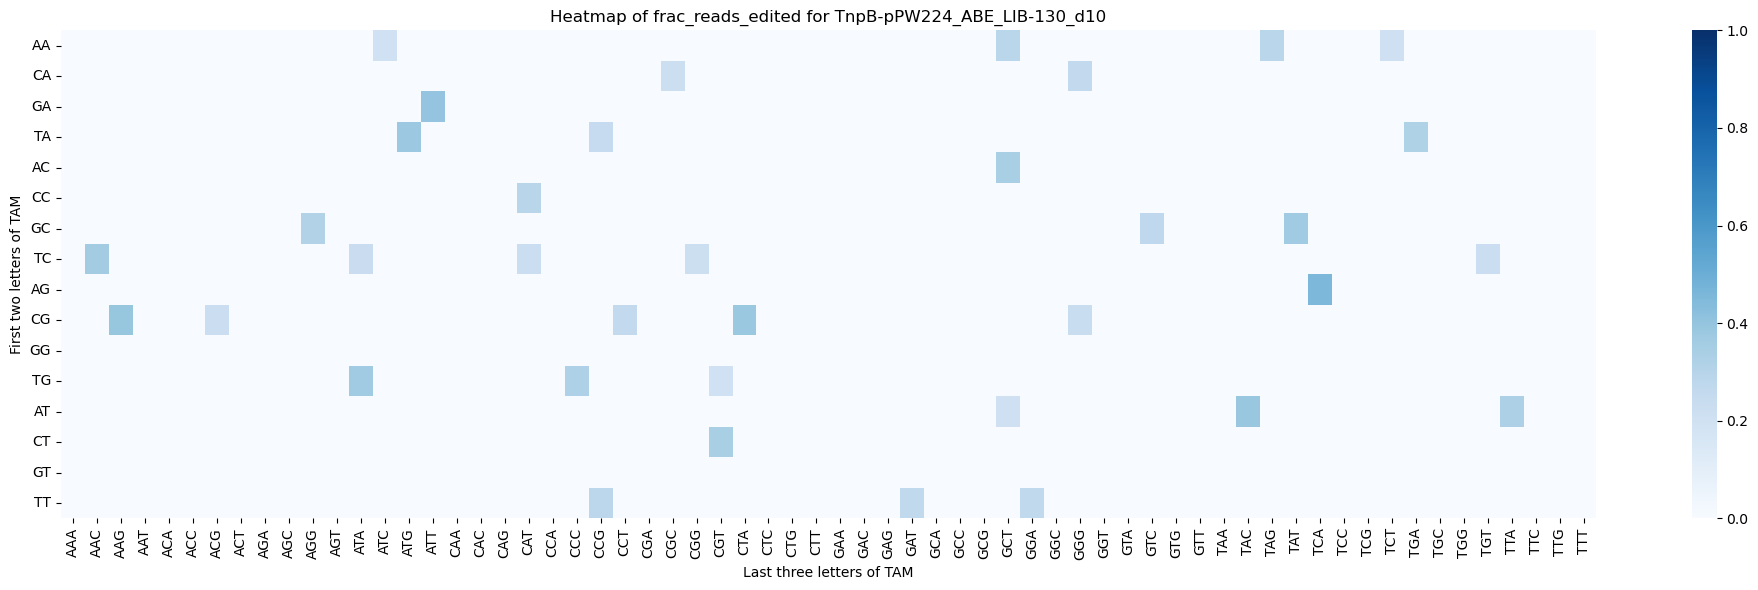

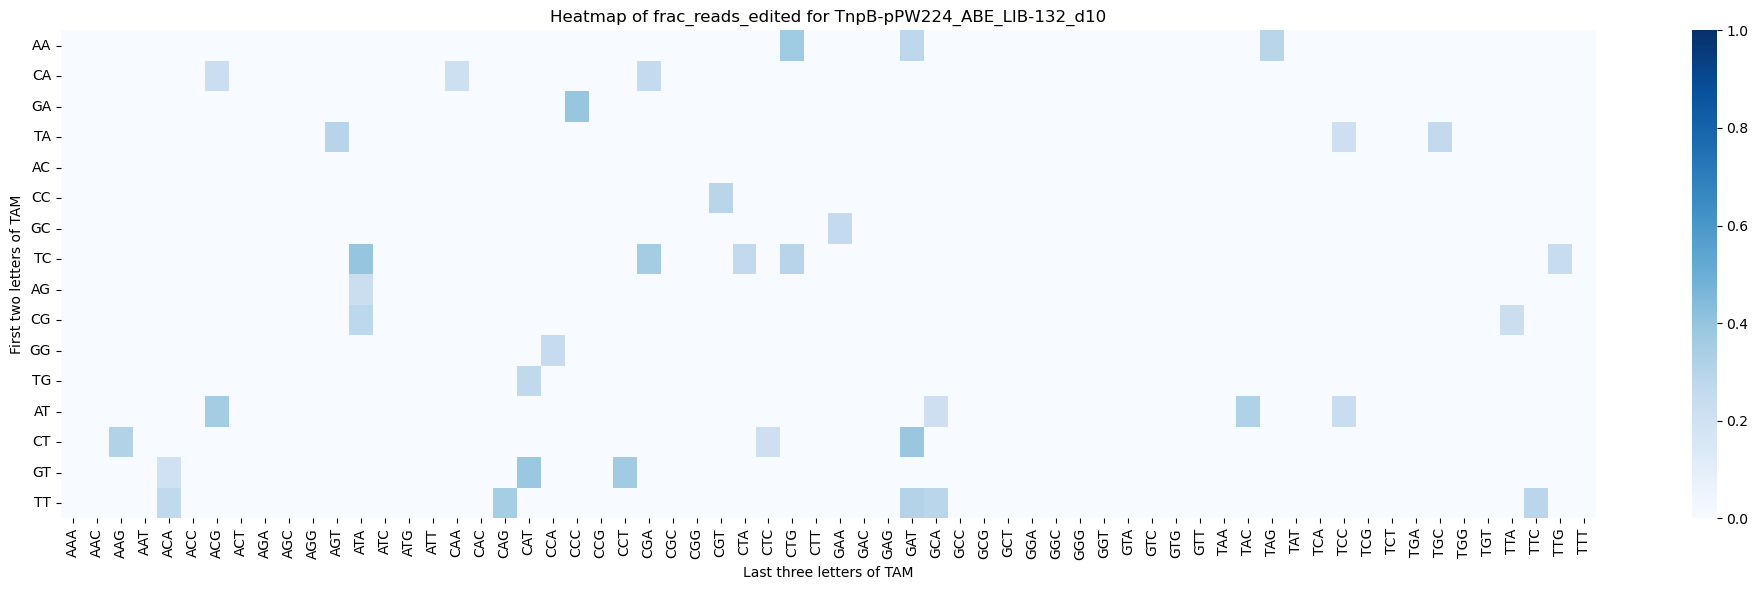

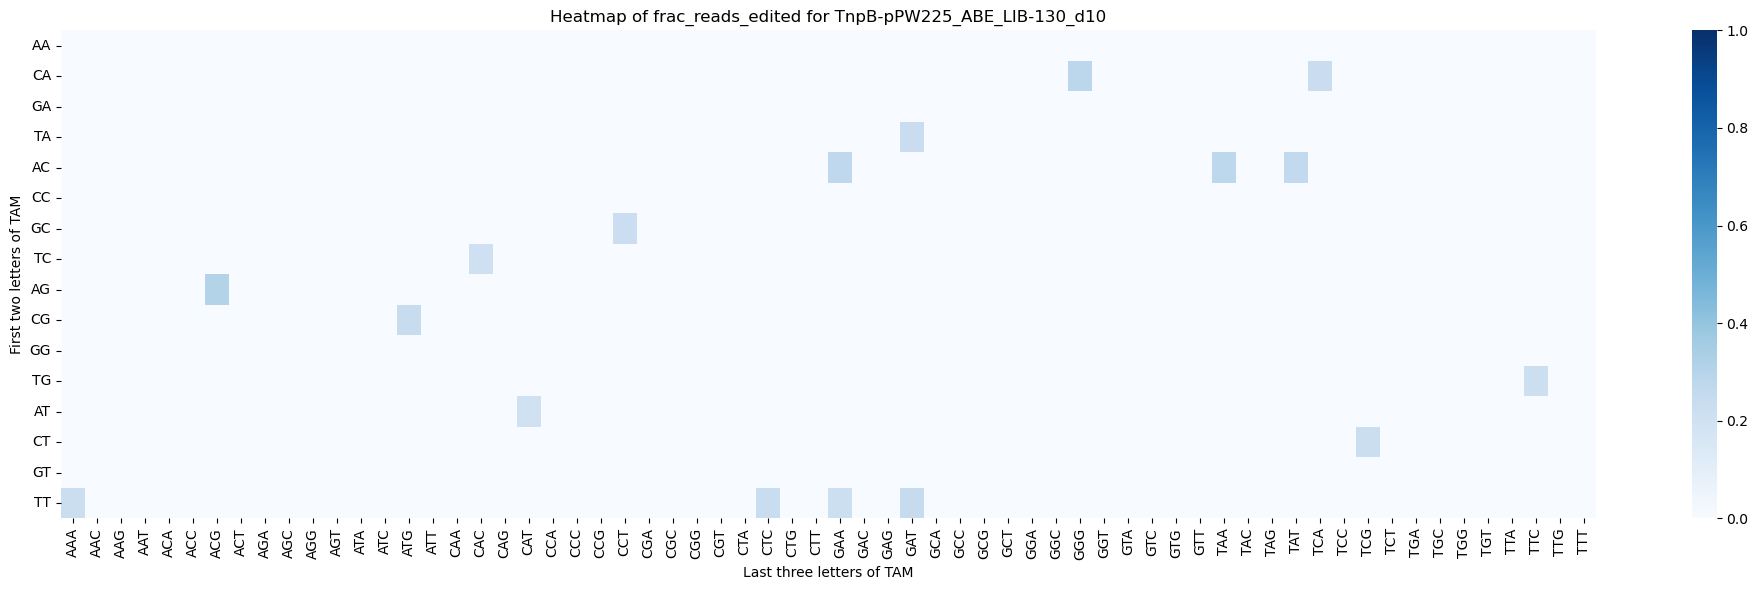

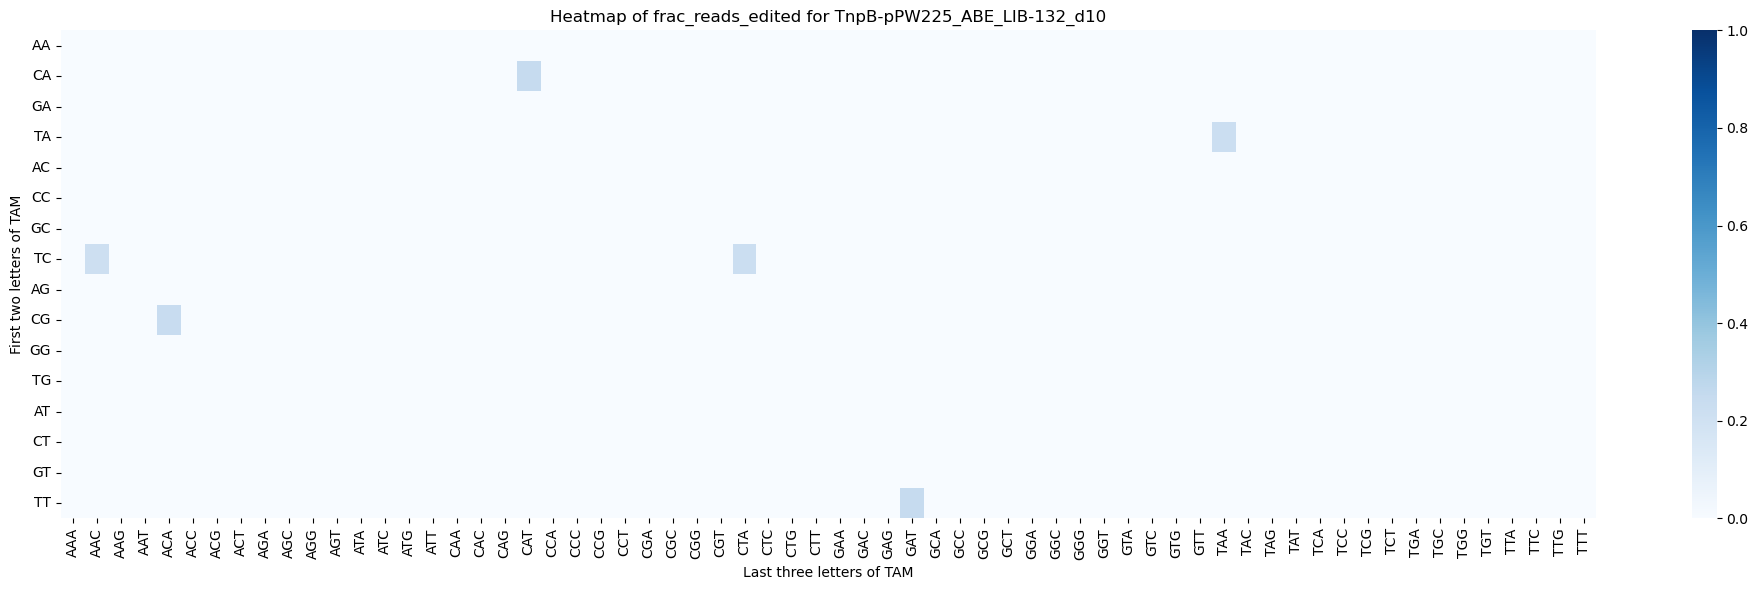

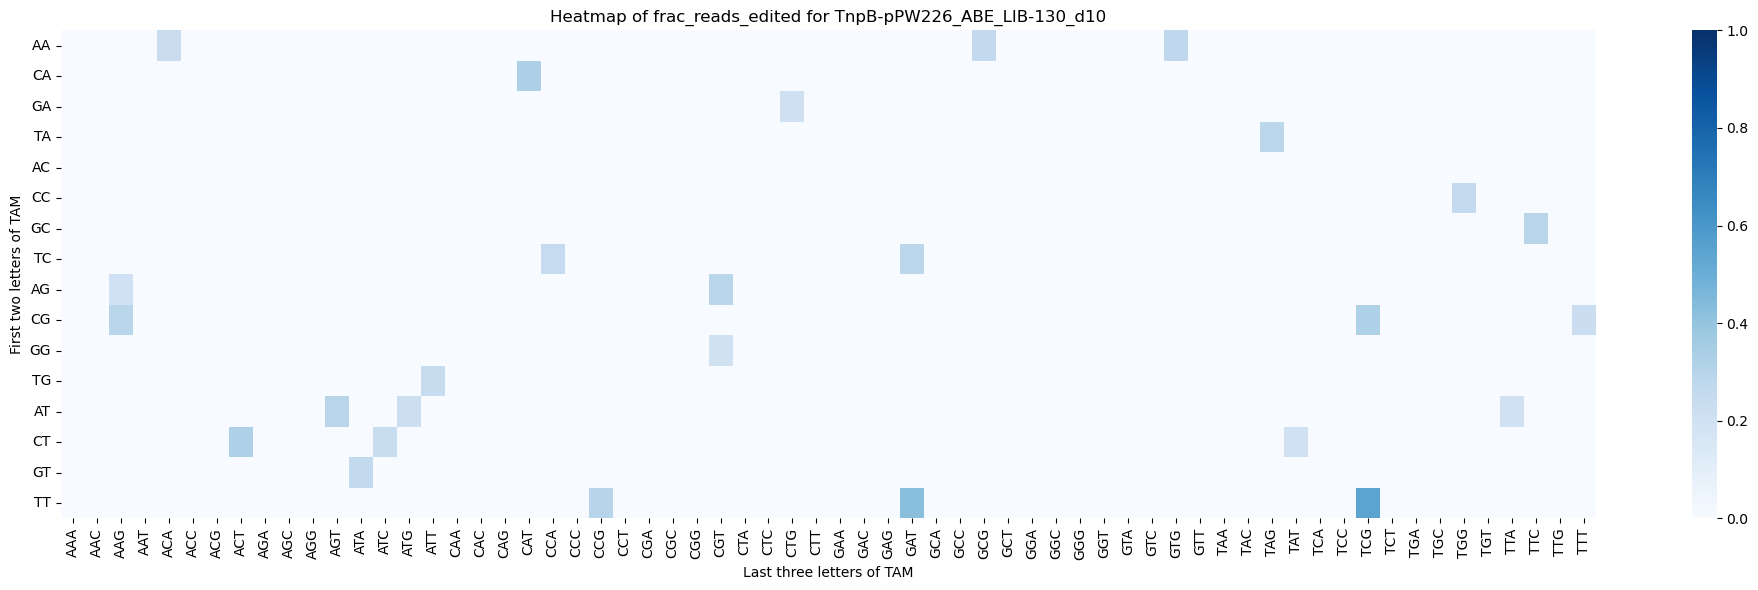

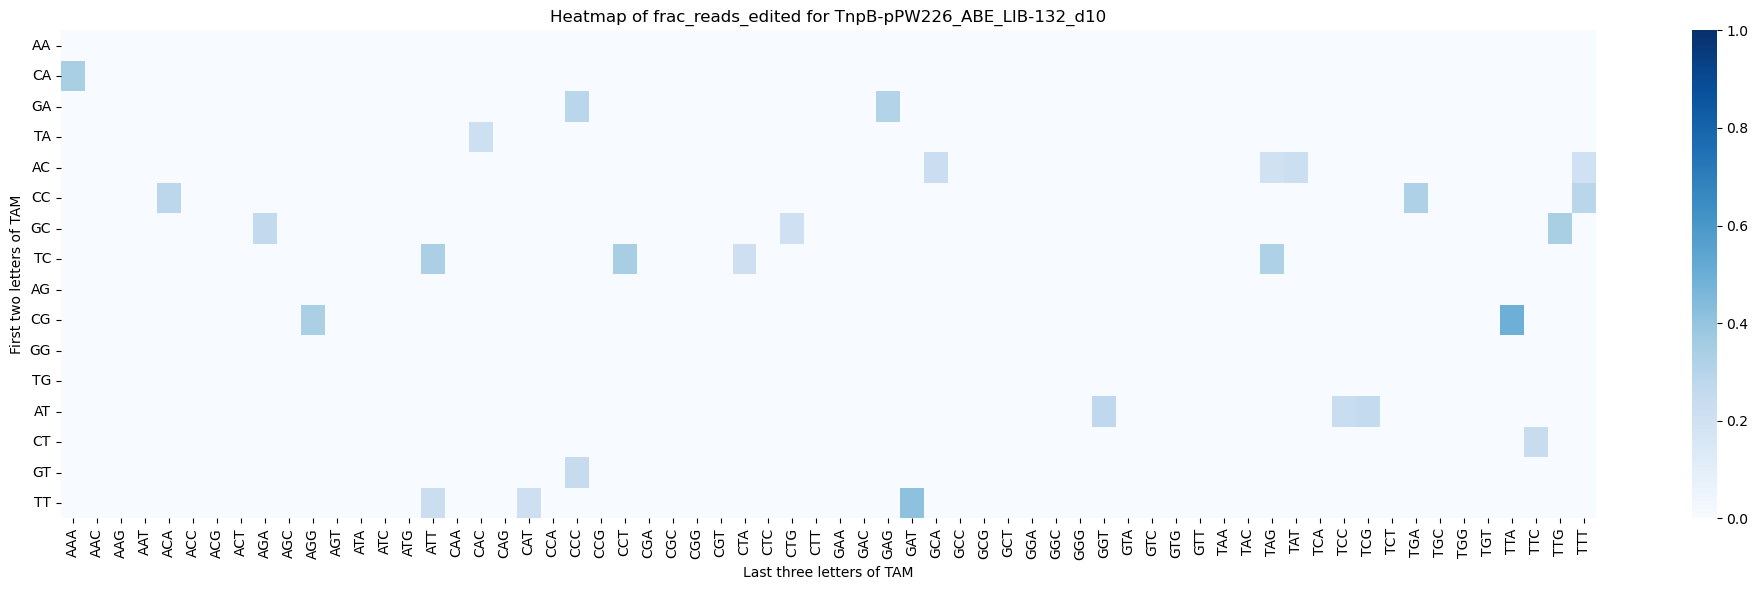

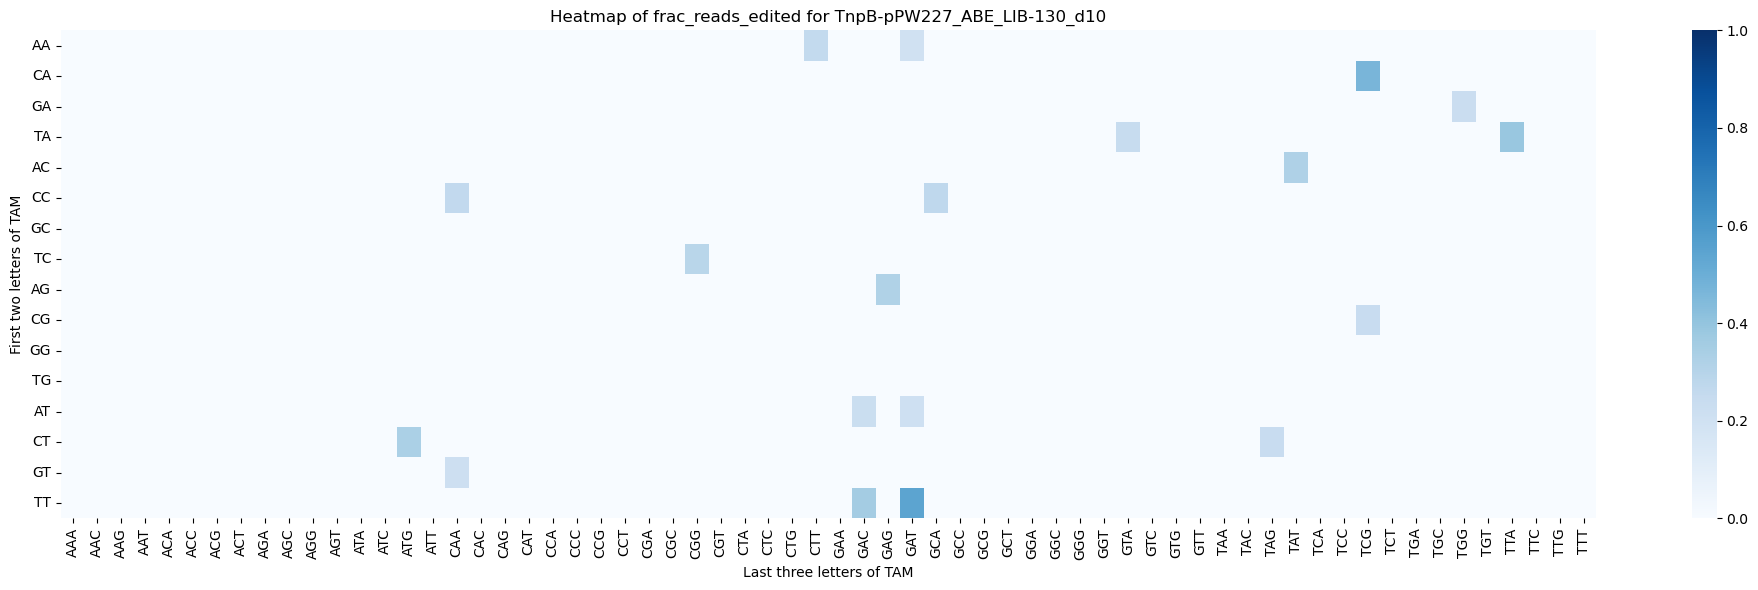

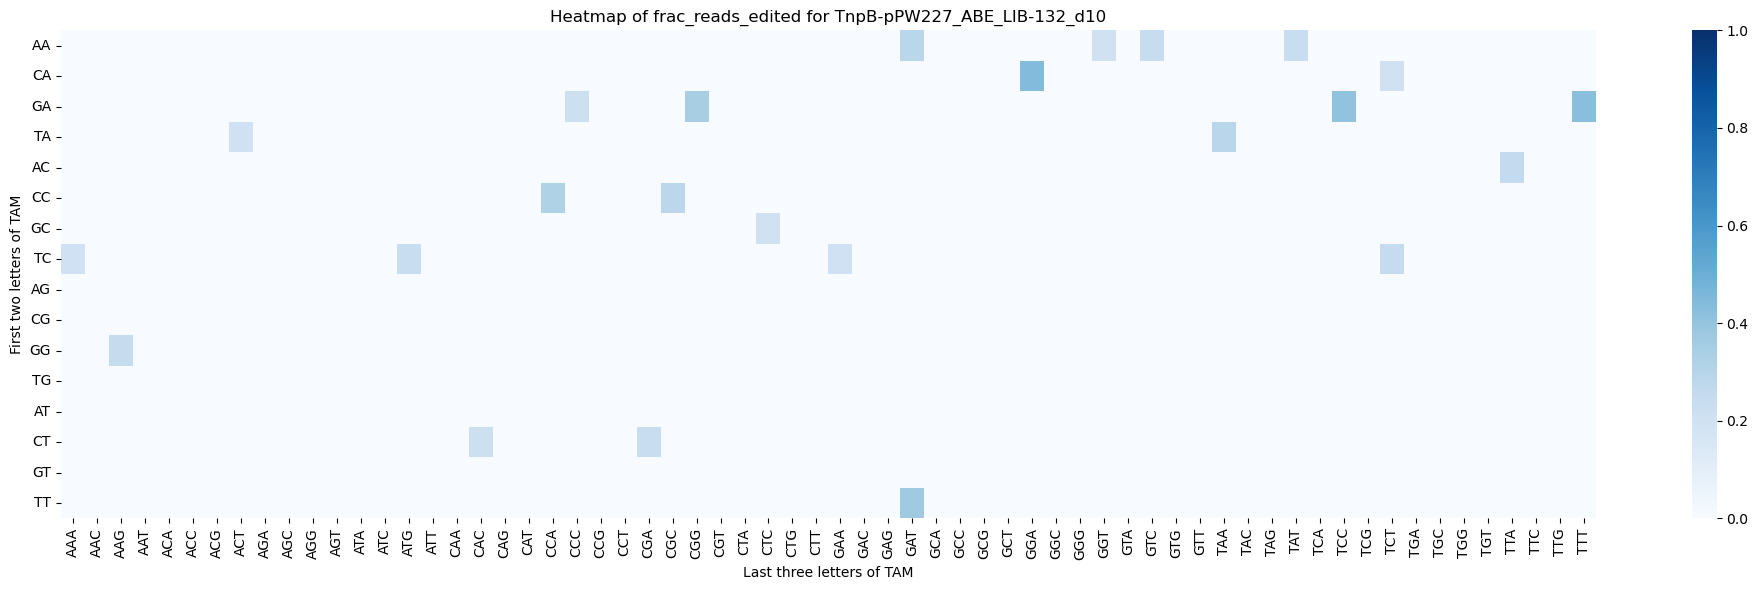

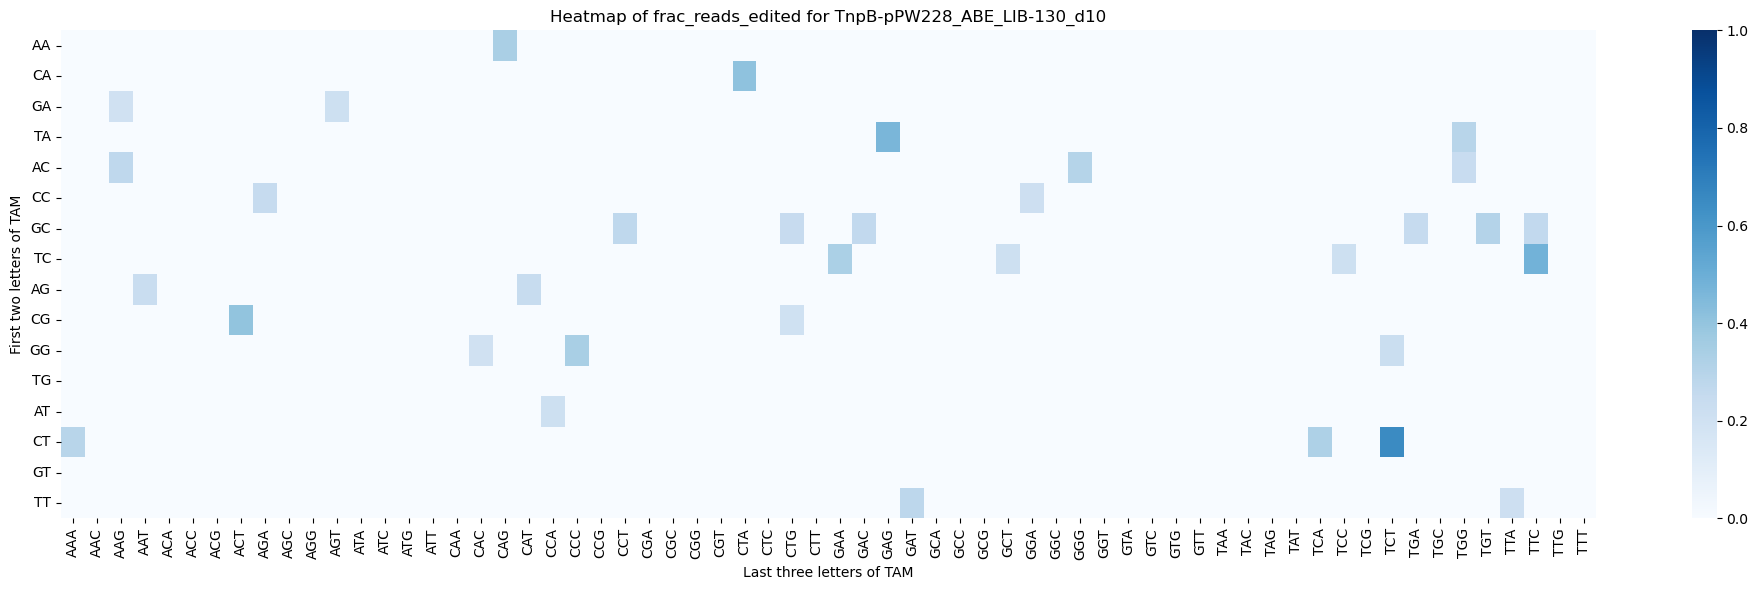

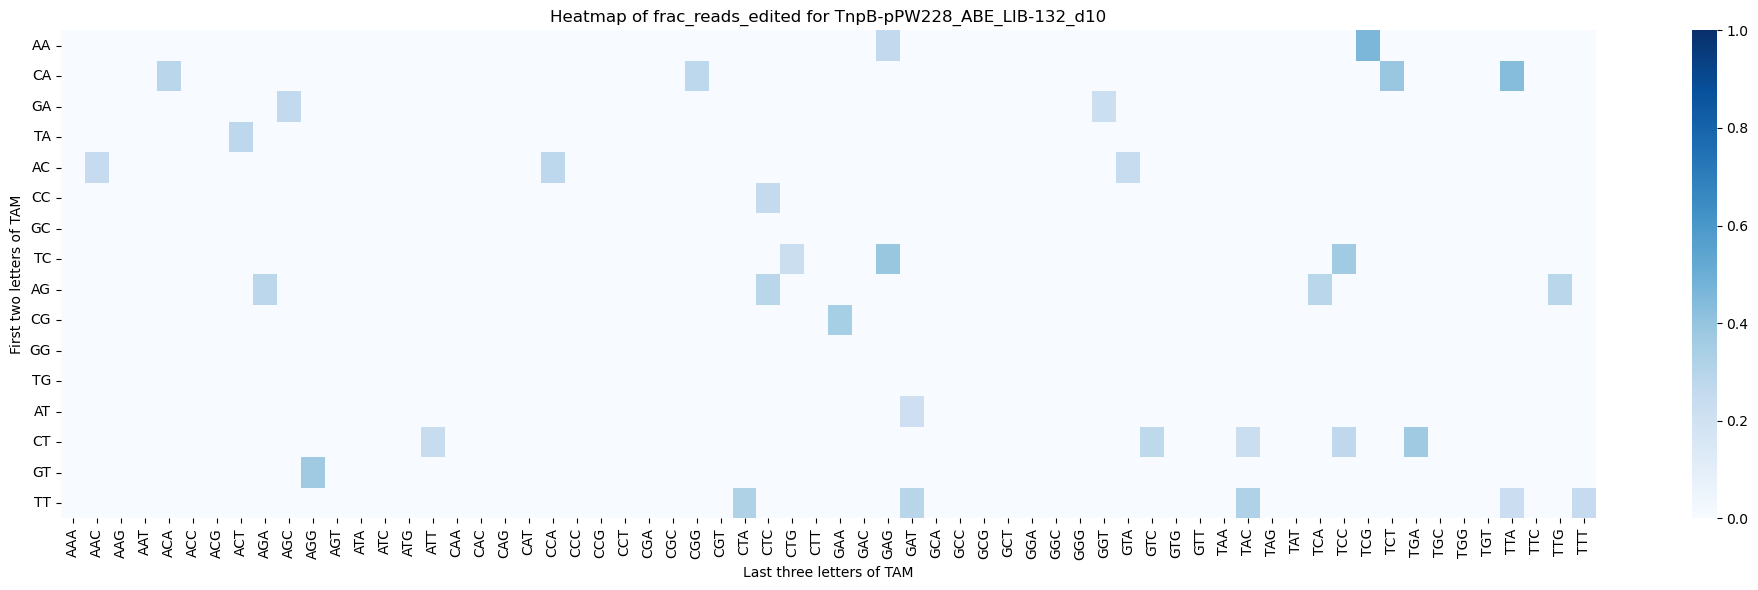

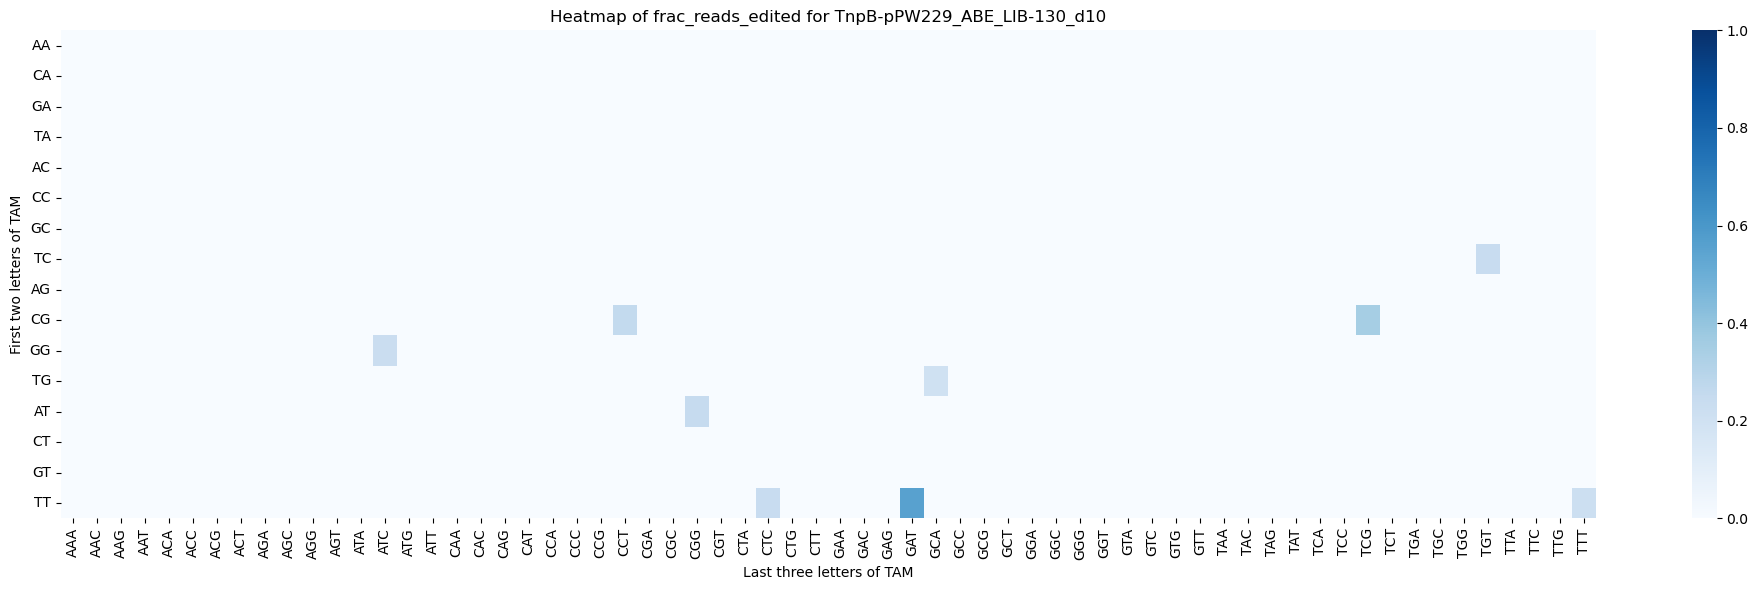

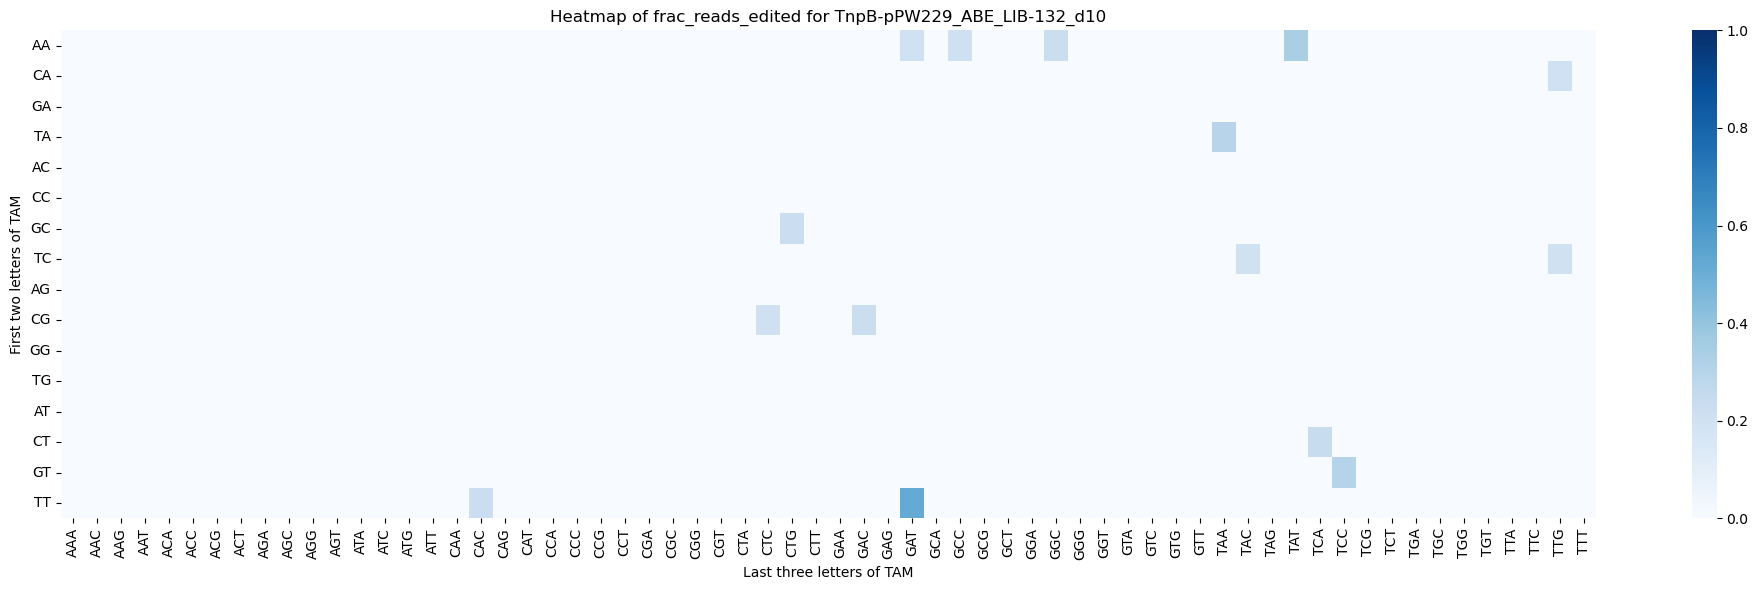

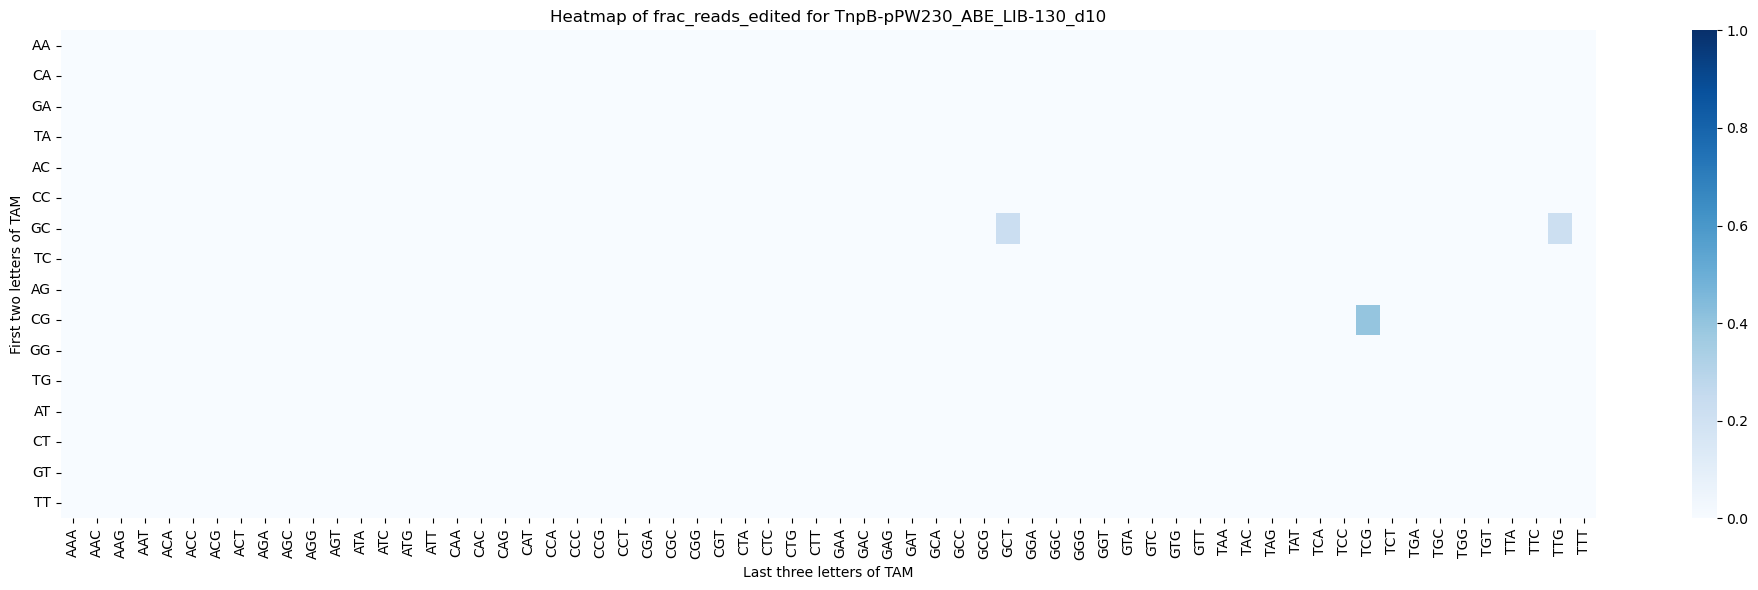

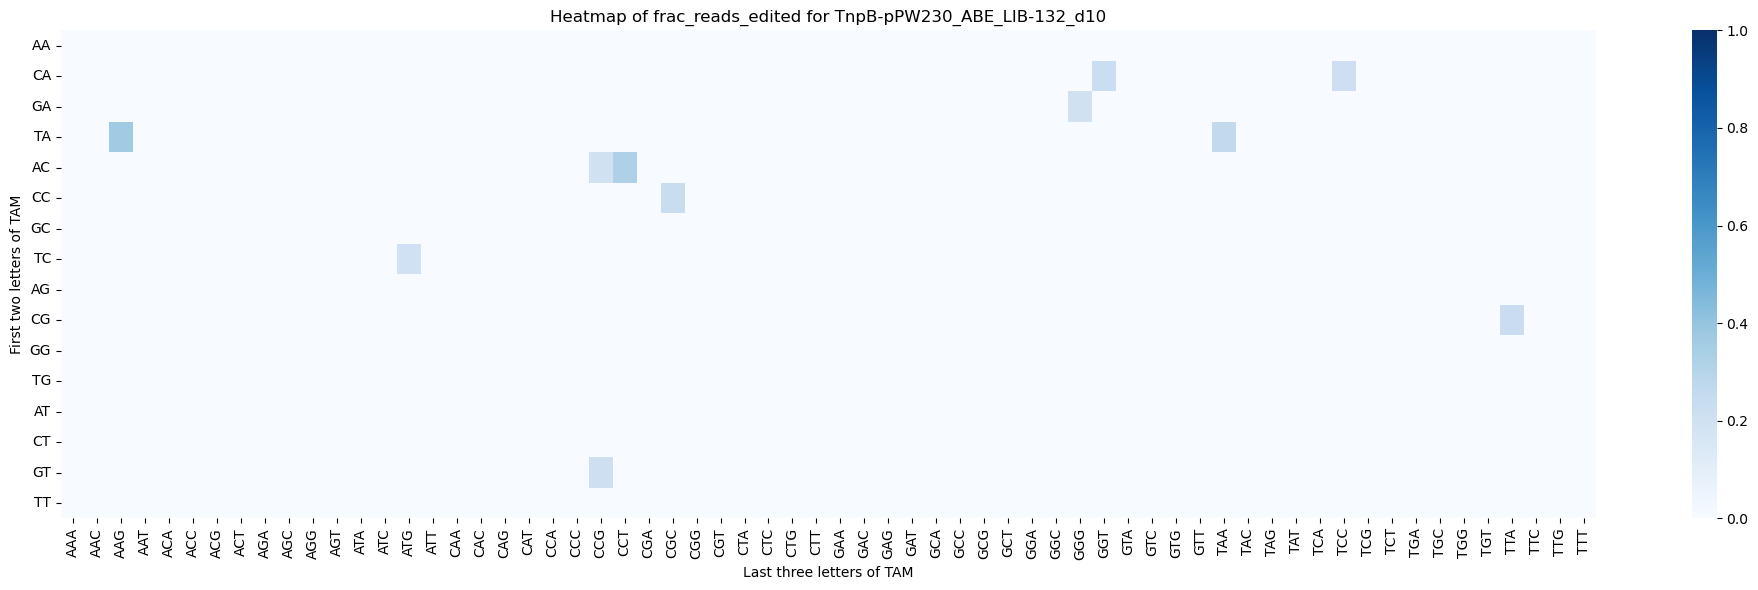

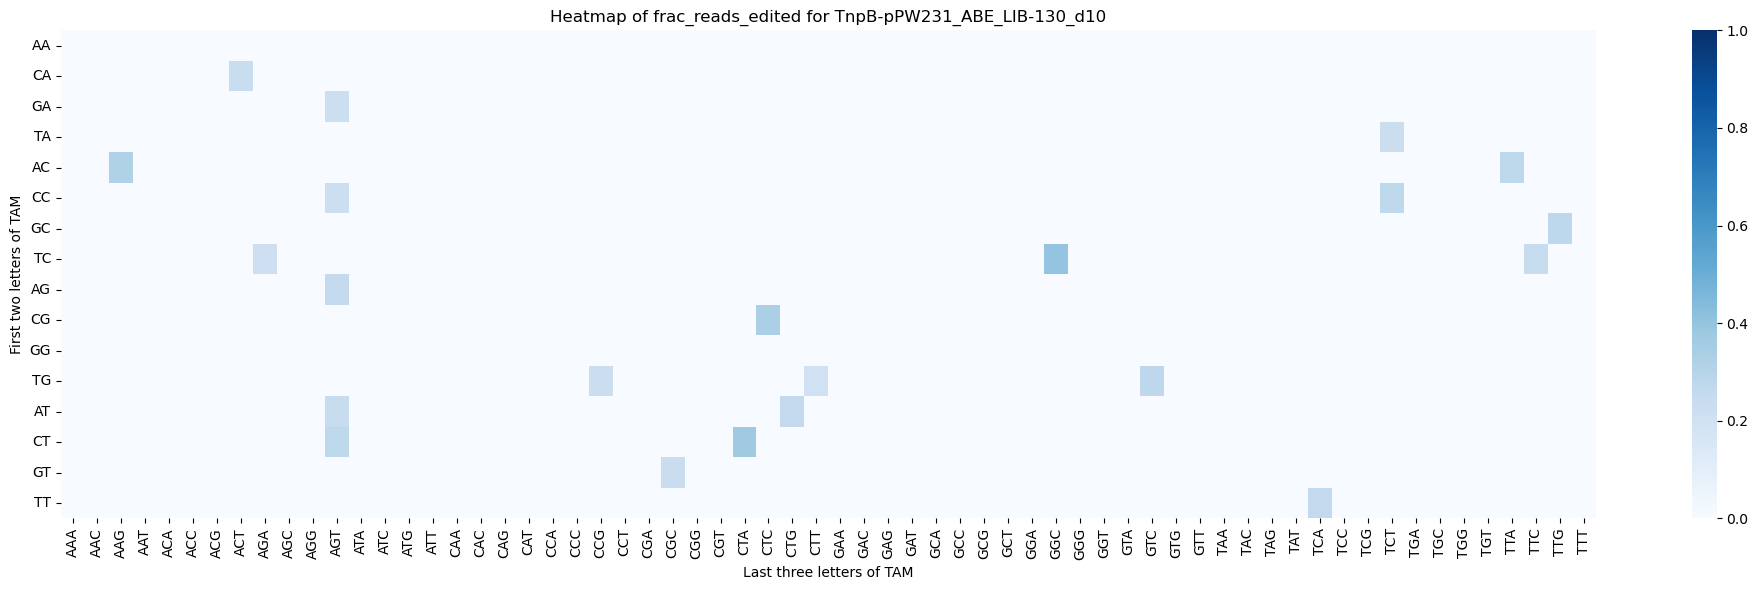

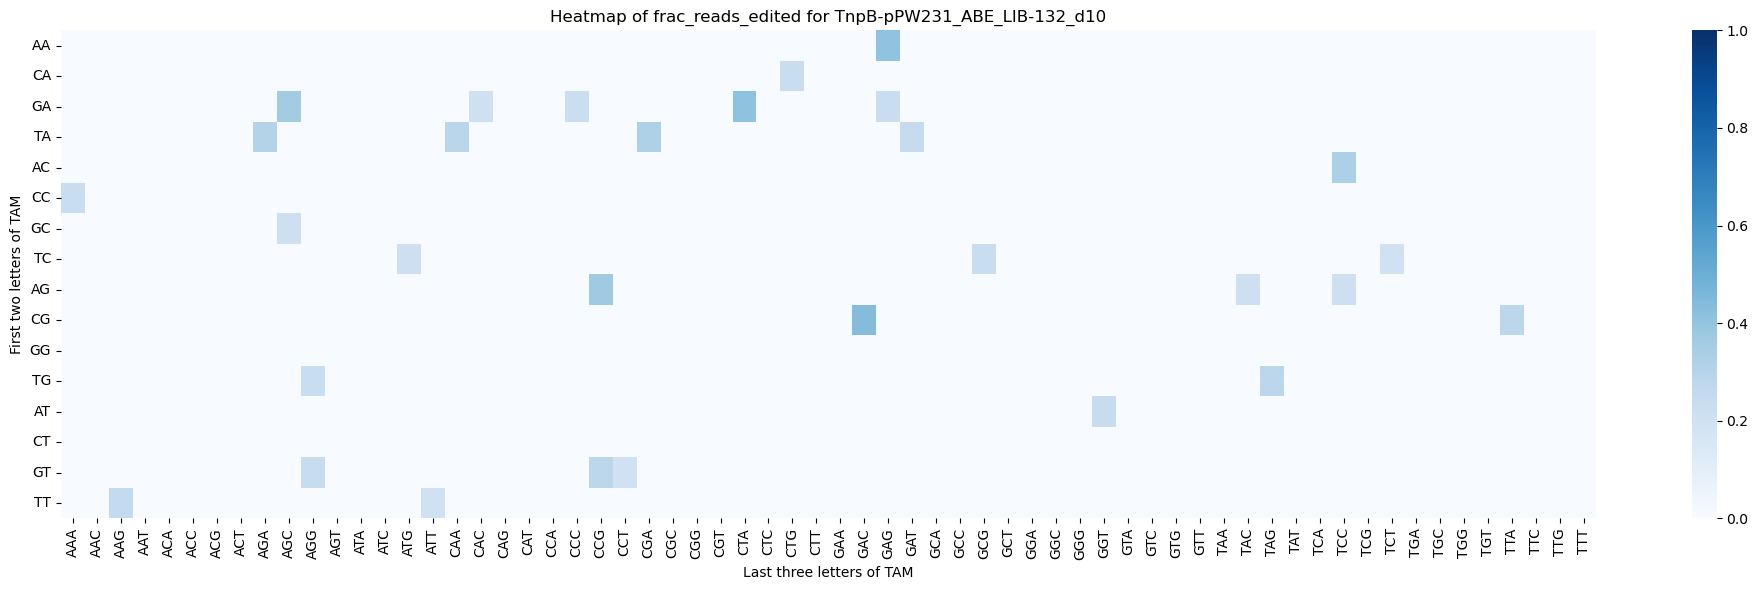

In [33]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

vis_bioreplicates=sorted(mean_fracs.bioreplicate.unique())
for bioreplicate in vis_bioreplicates:
    plot_heatmap_for_bioreplicate(mean_fracs, bioreplicate, vis_edit_thres=0.2,
                                    figsize=(20,6), cmap="Blues",
                                    save_figure=True, prefix="Normalized")

/tmp/ipykernel_1234884/3230753211.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


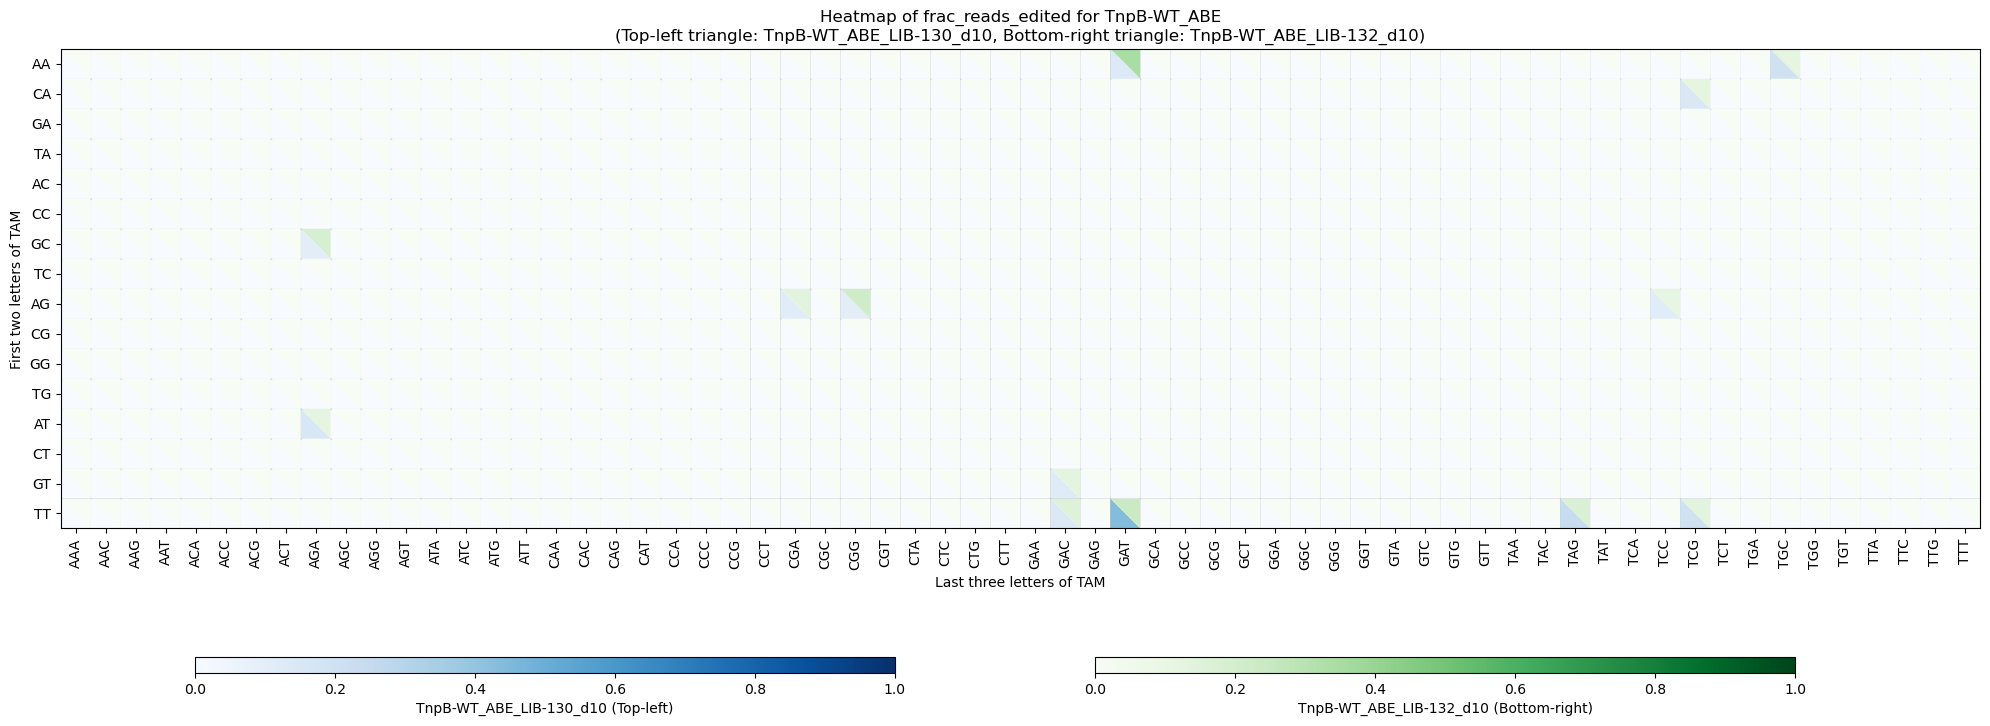

/tmp/ipykernel_1234884/3230753211.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


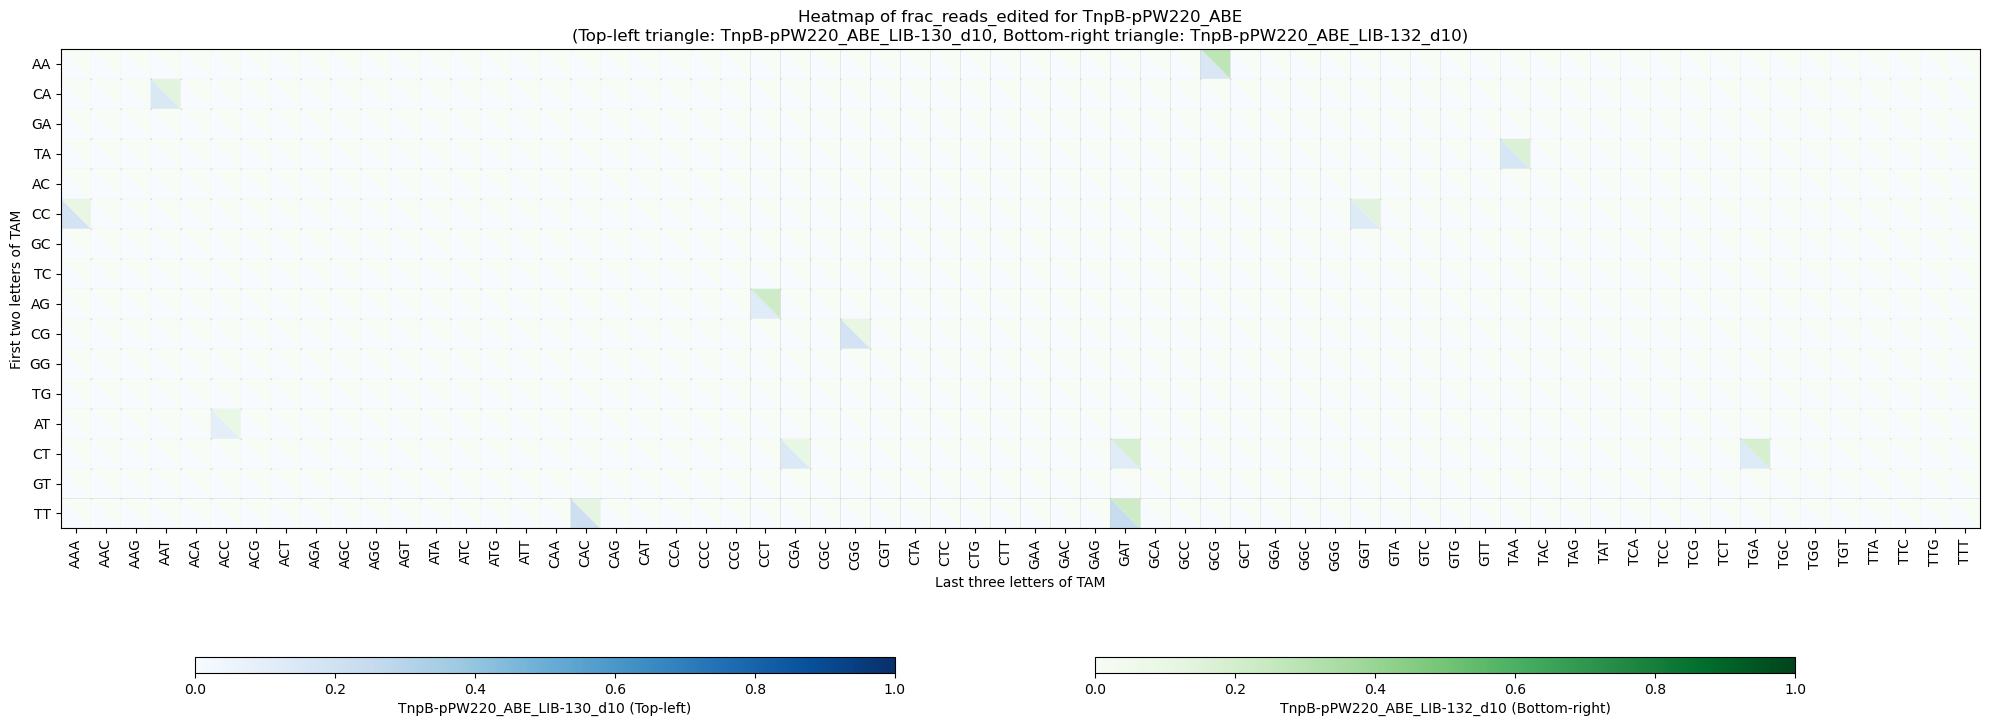

/tmp/ipykernel_1234884/3230753211.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


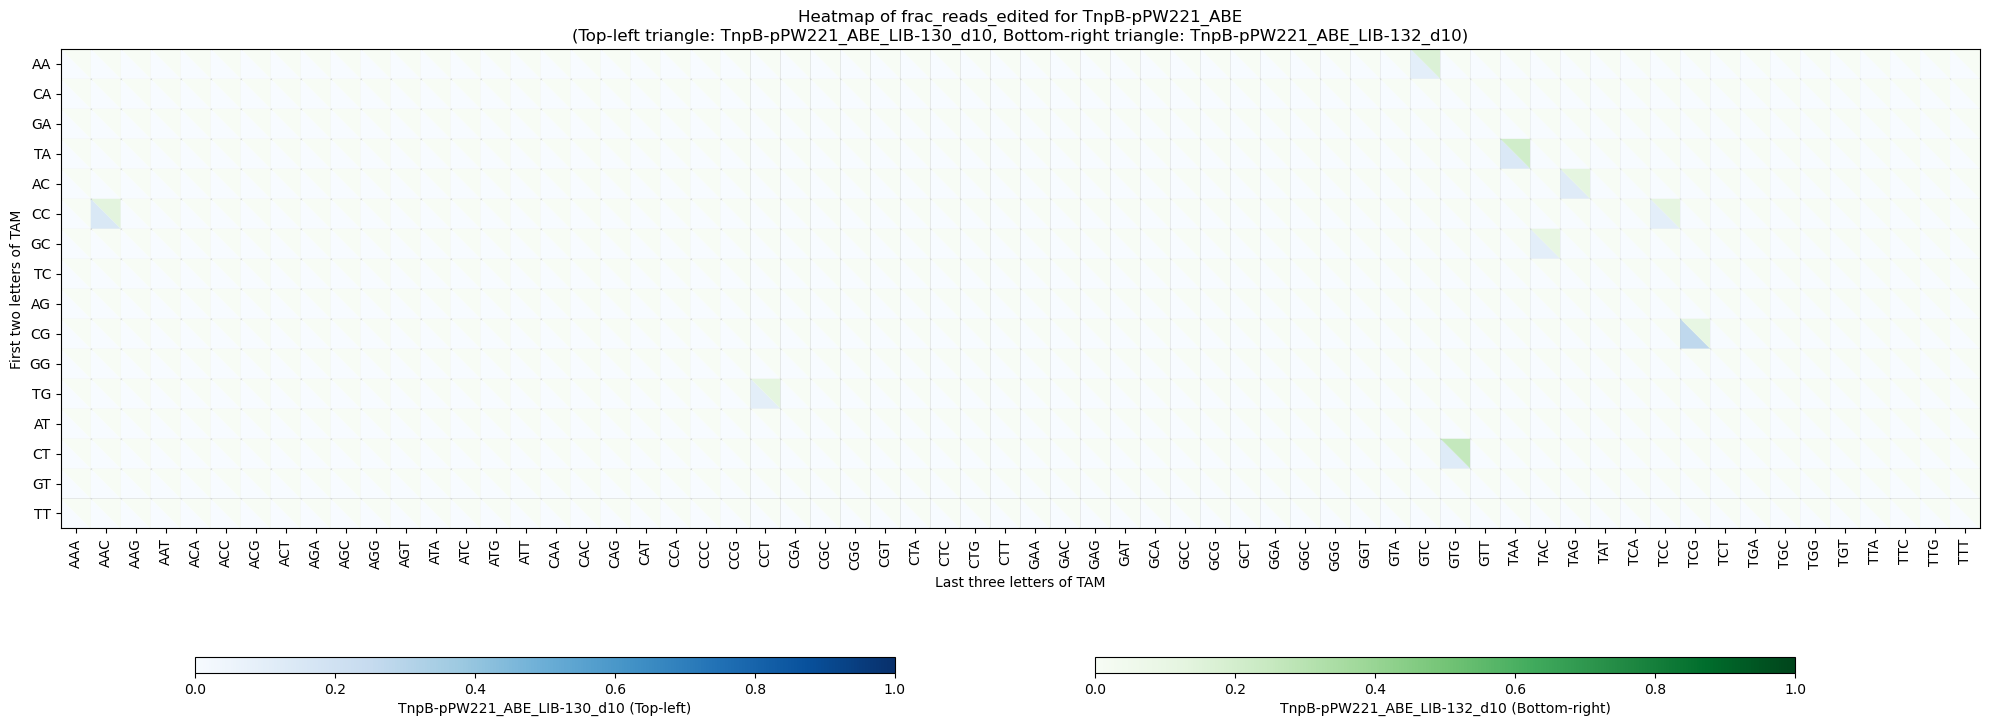

/tmp/ipykernel_1234884/3230753211.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


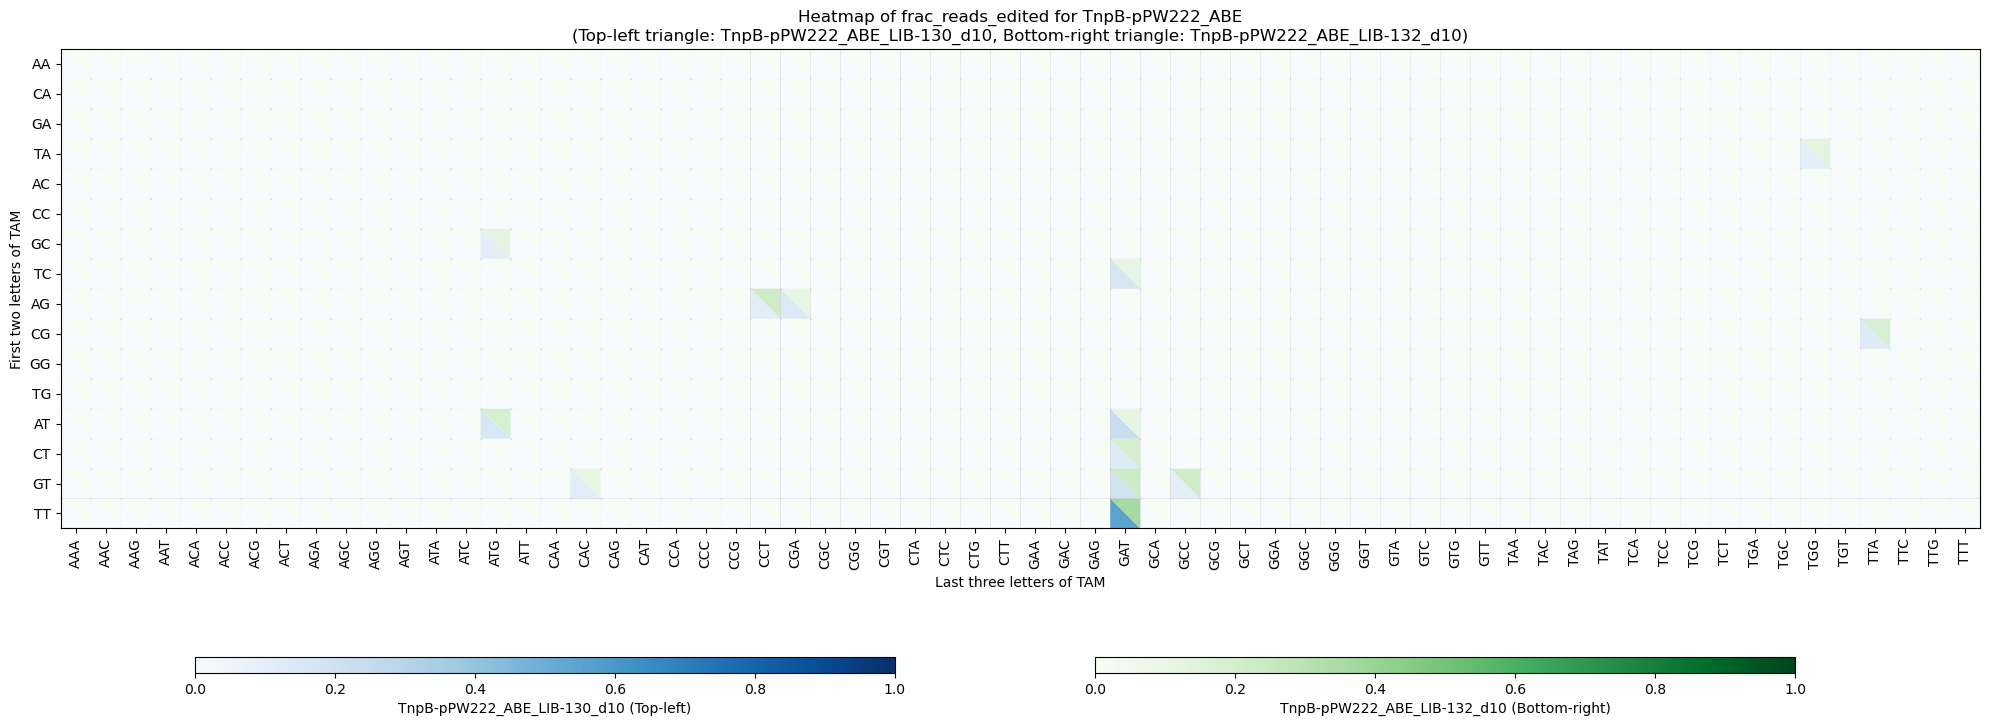

/tmp/ipykernel_1234884/3230753211.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


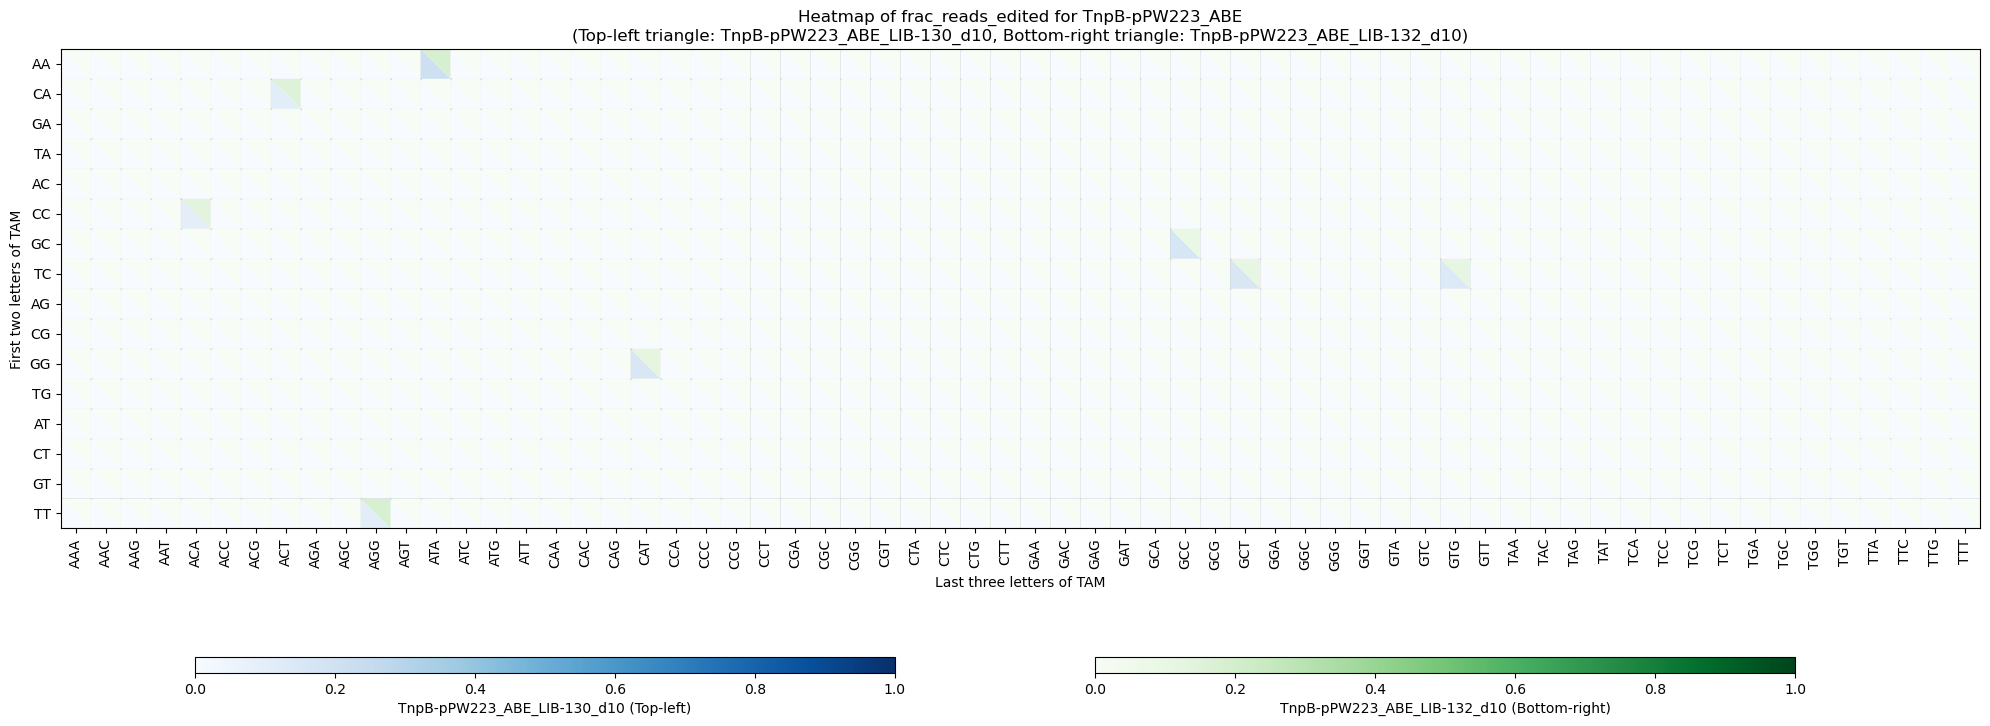

/tmp/ipykernel_1234884/3230753211.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


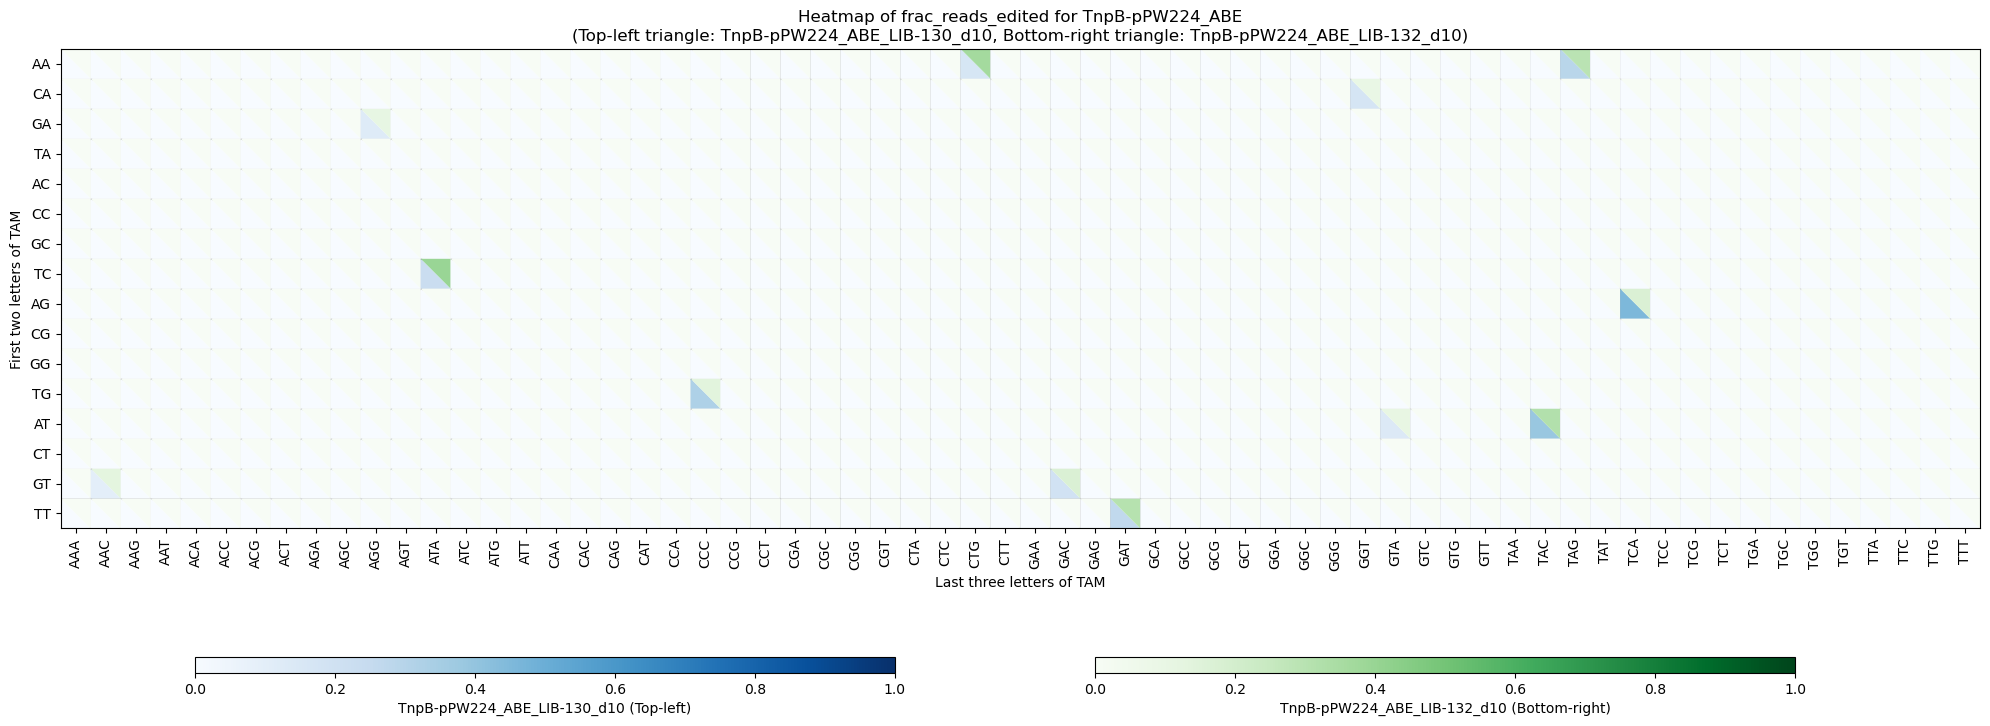

/tmp/ipykernel_1234884/3230753211.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


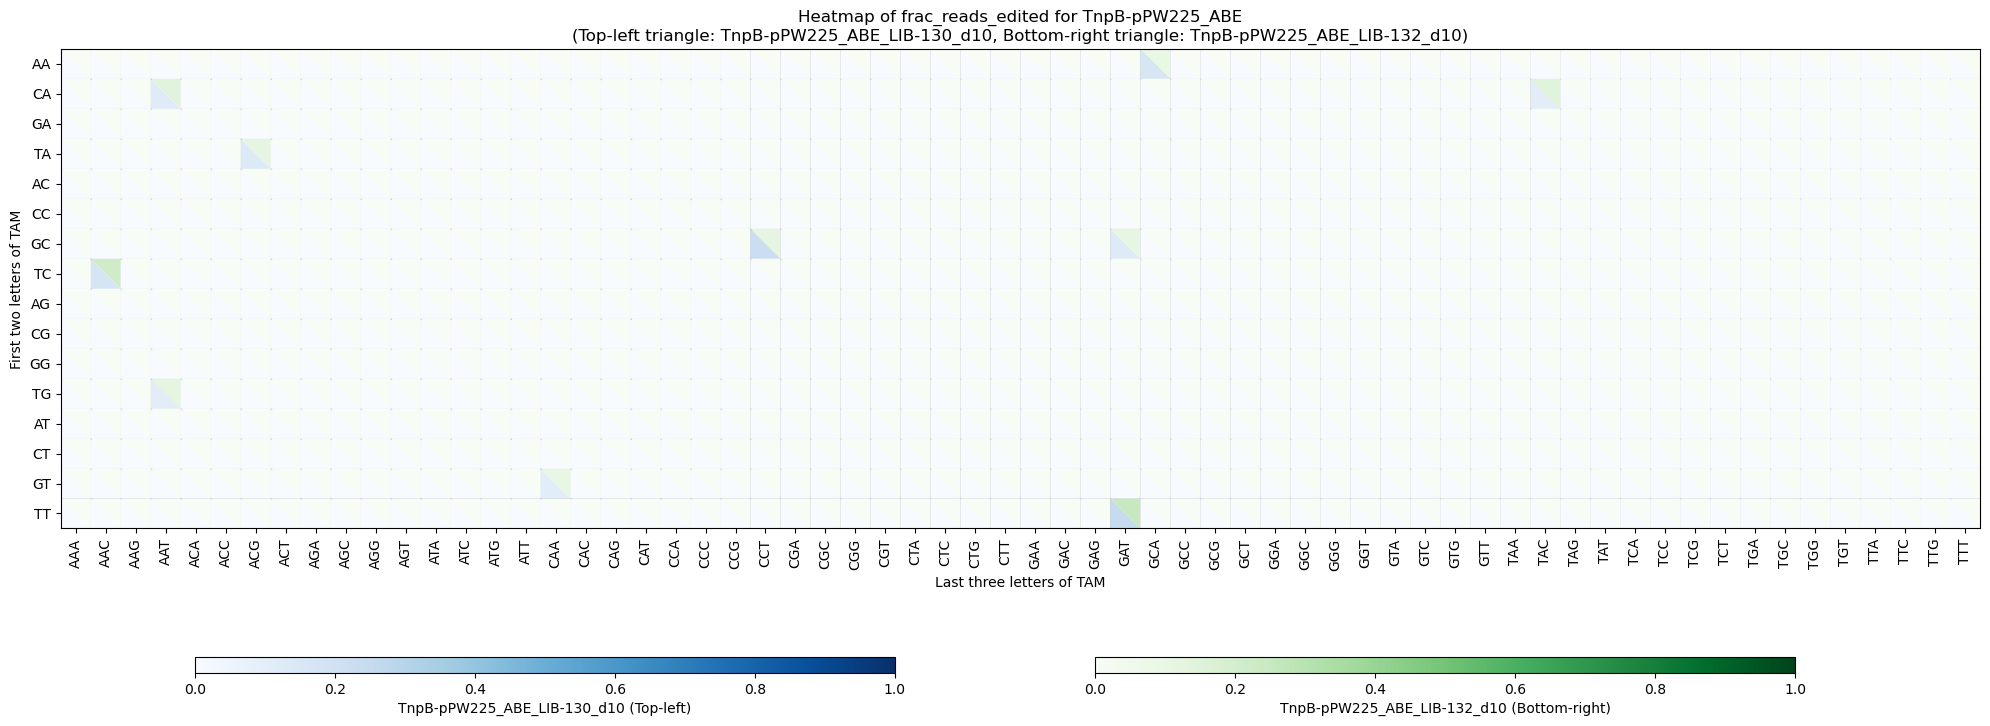

/tmp/ipykernel_1234884/3230753211.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


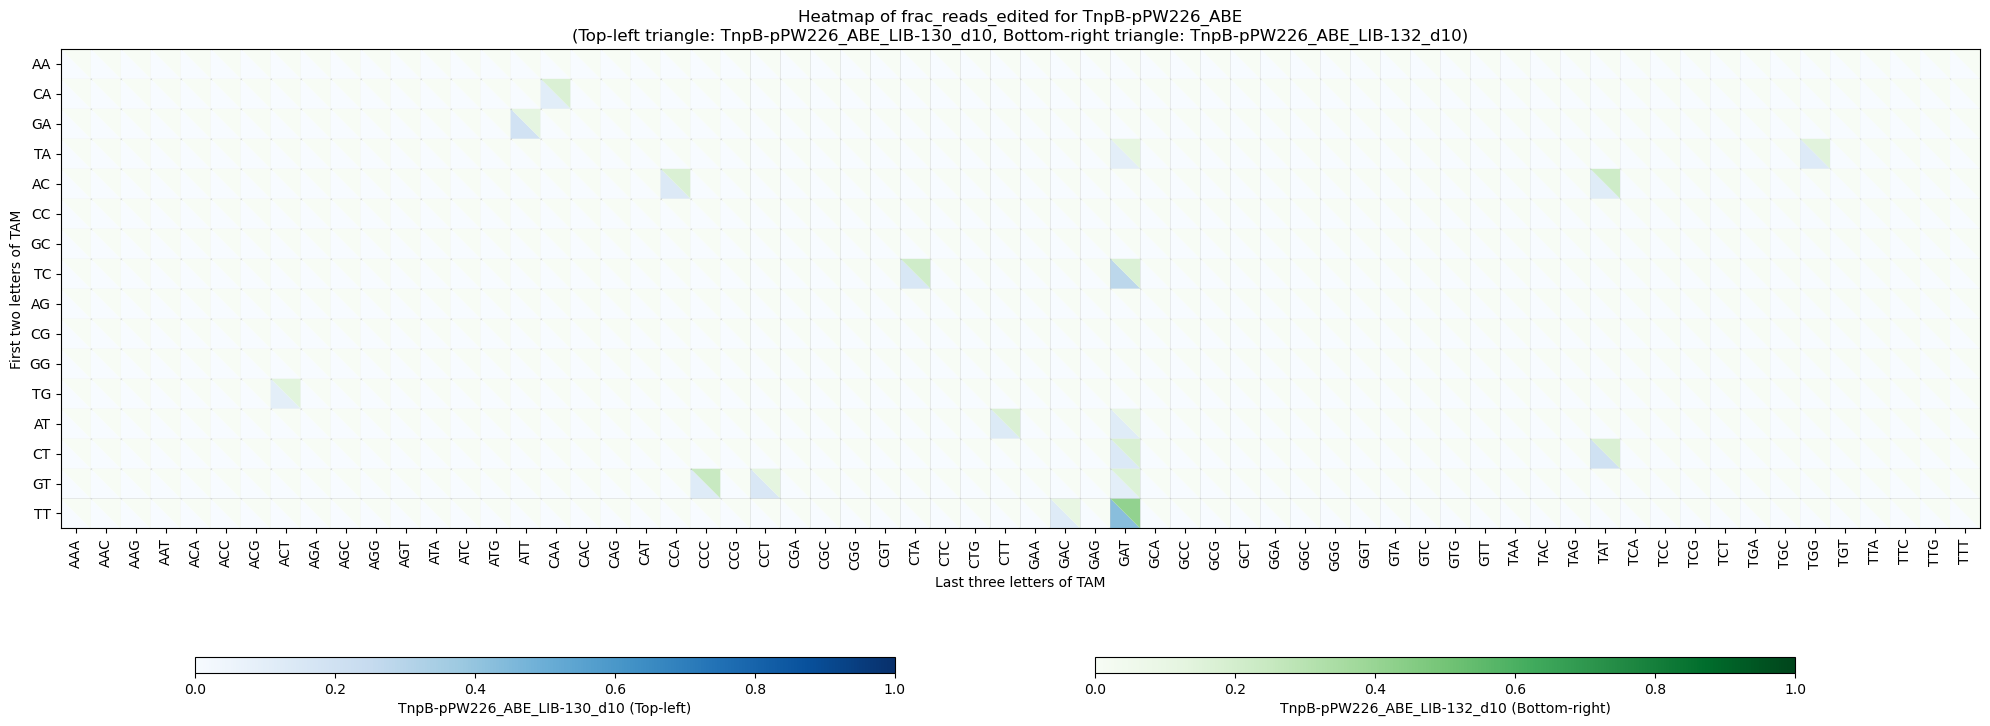

/tmp/ipykernel_1234884/3230753211.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


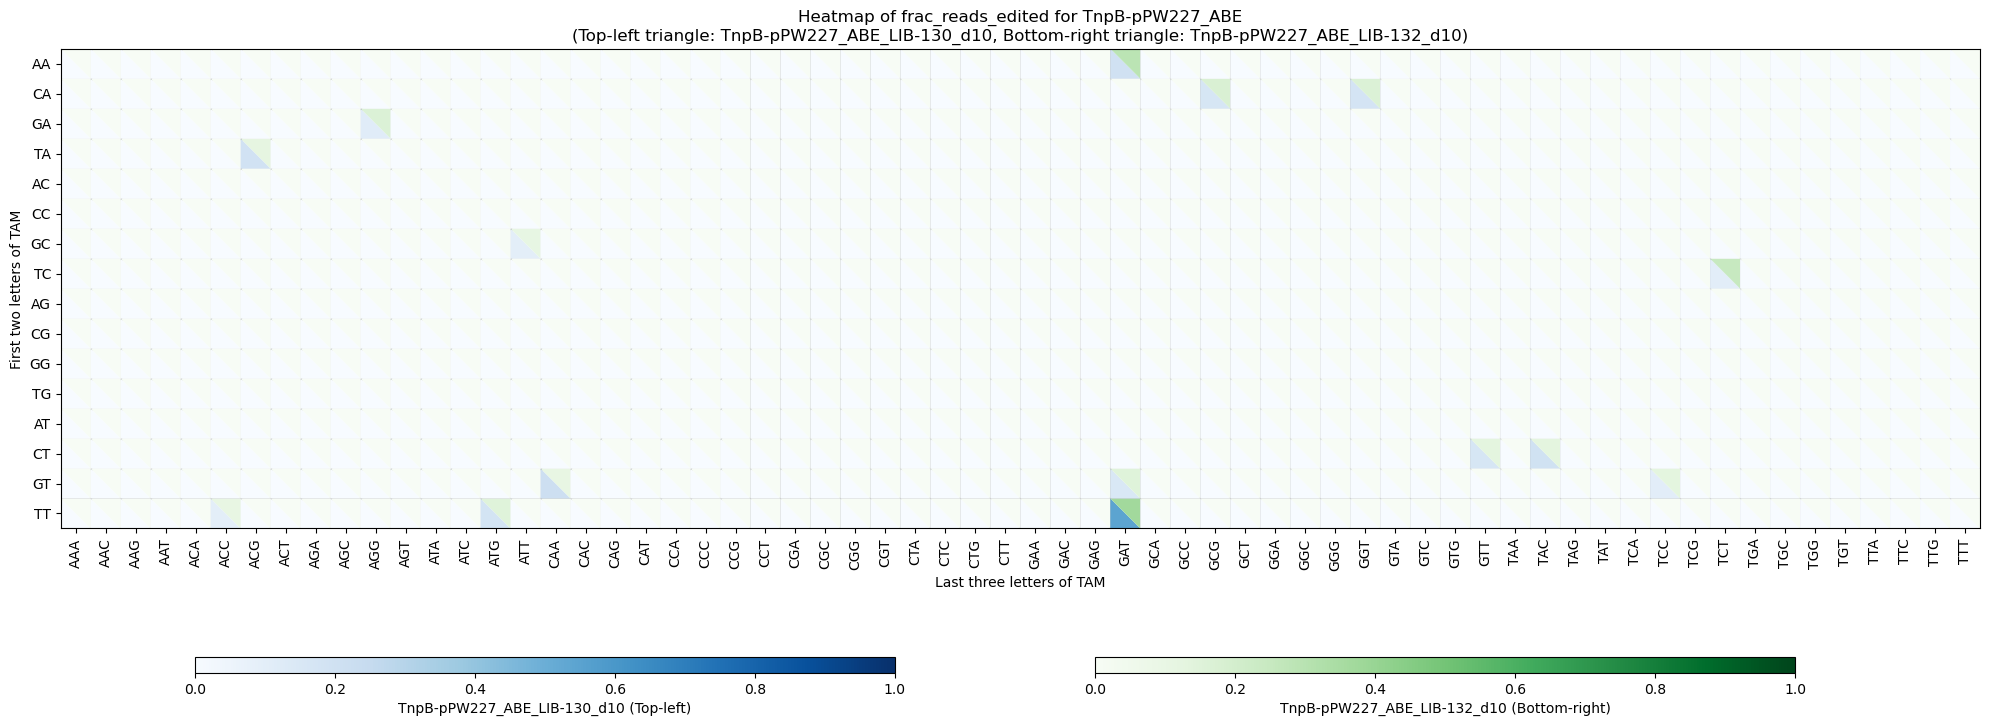

/tmp/ipykernel_1234884/3230753211.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


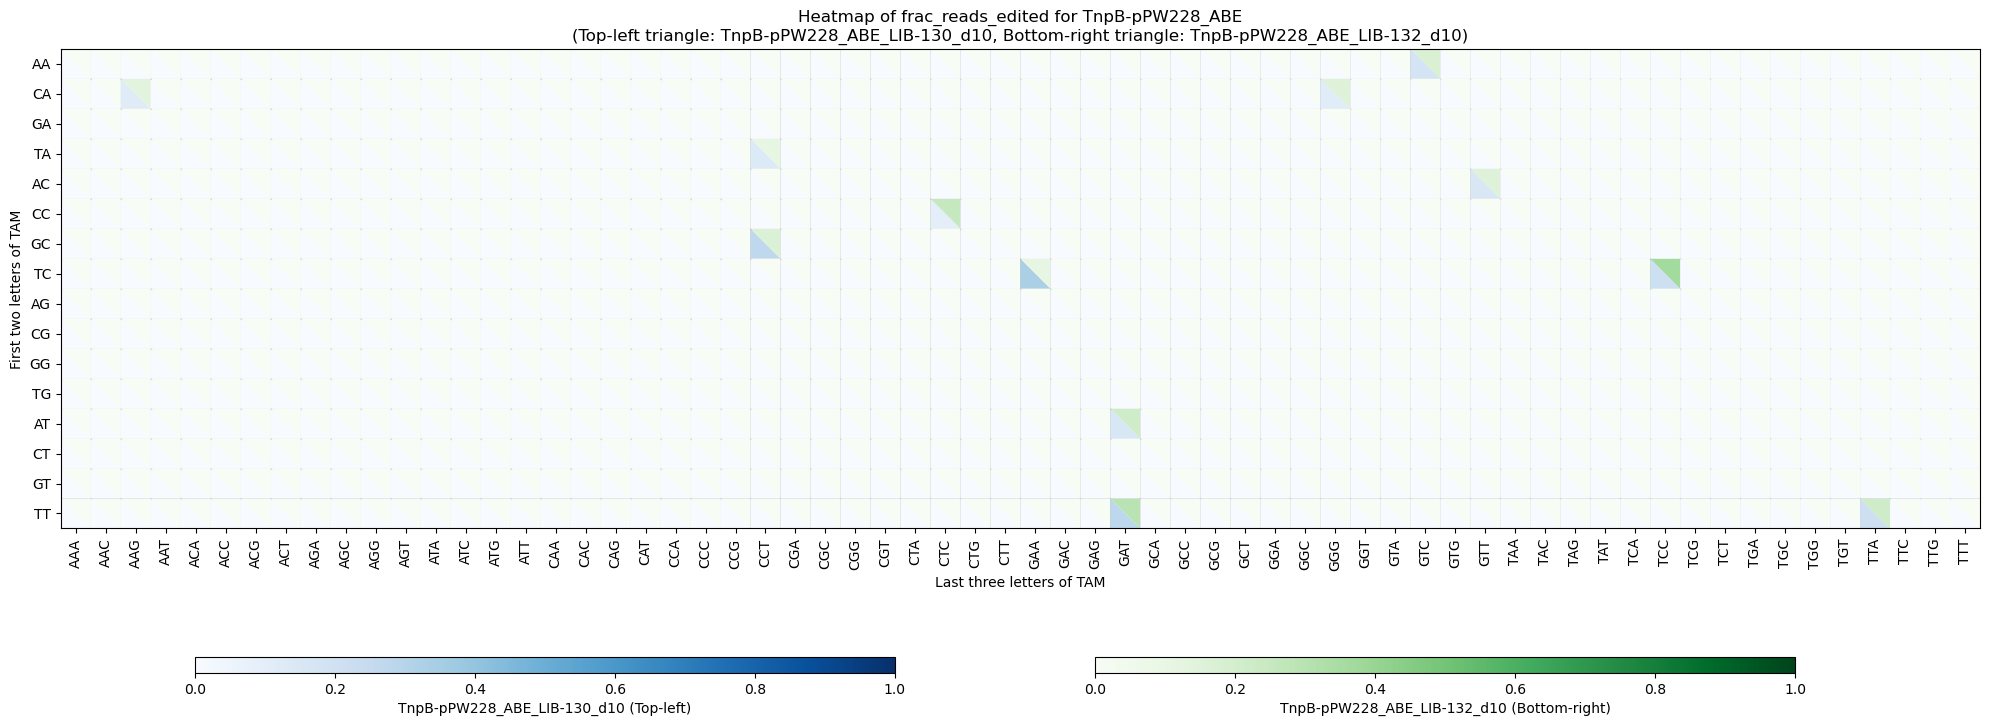

/tmp/ipykernel_1234884/3230753211.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


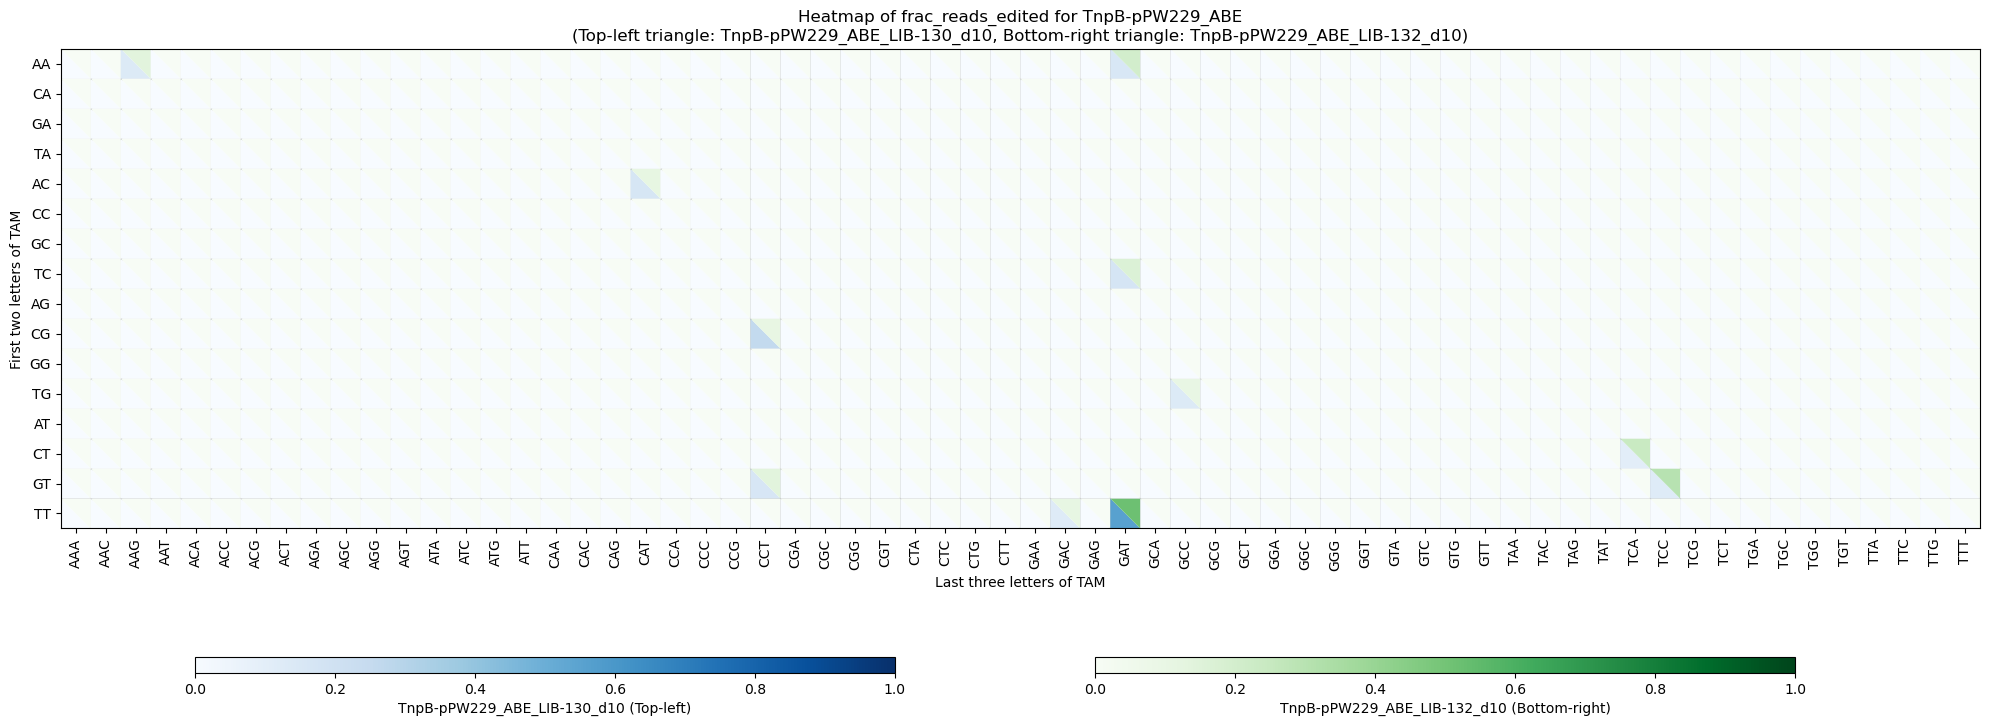

/tmp/ipykernel_1234884/3230753211.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


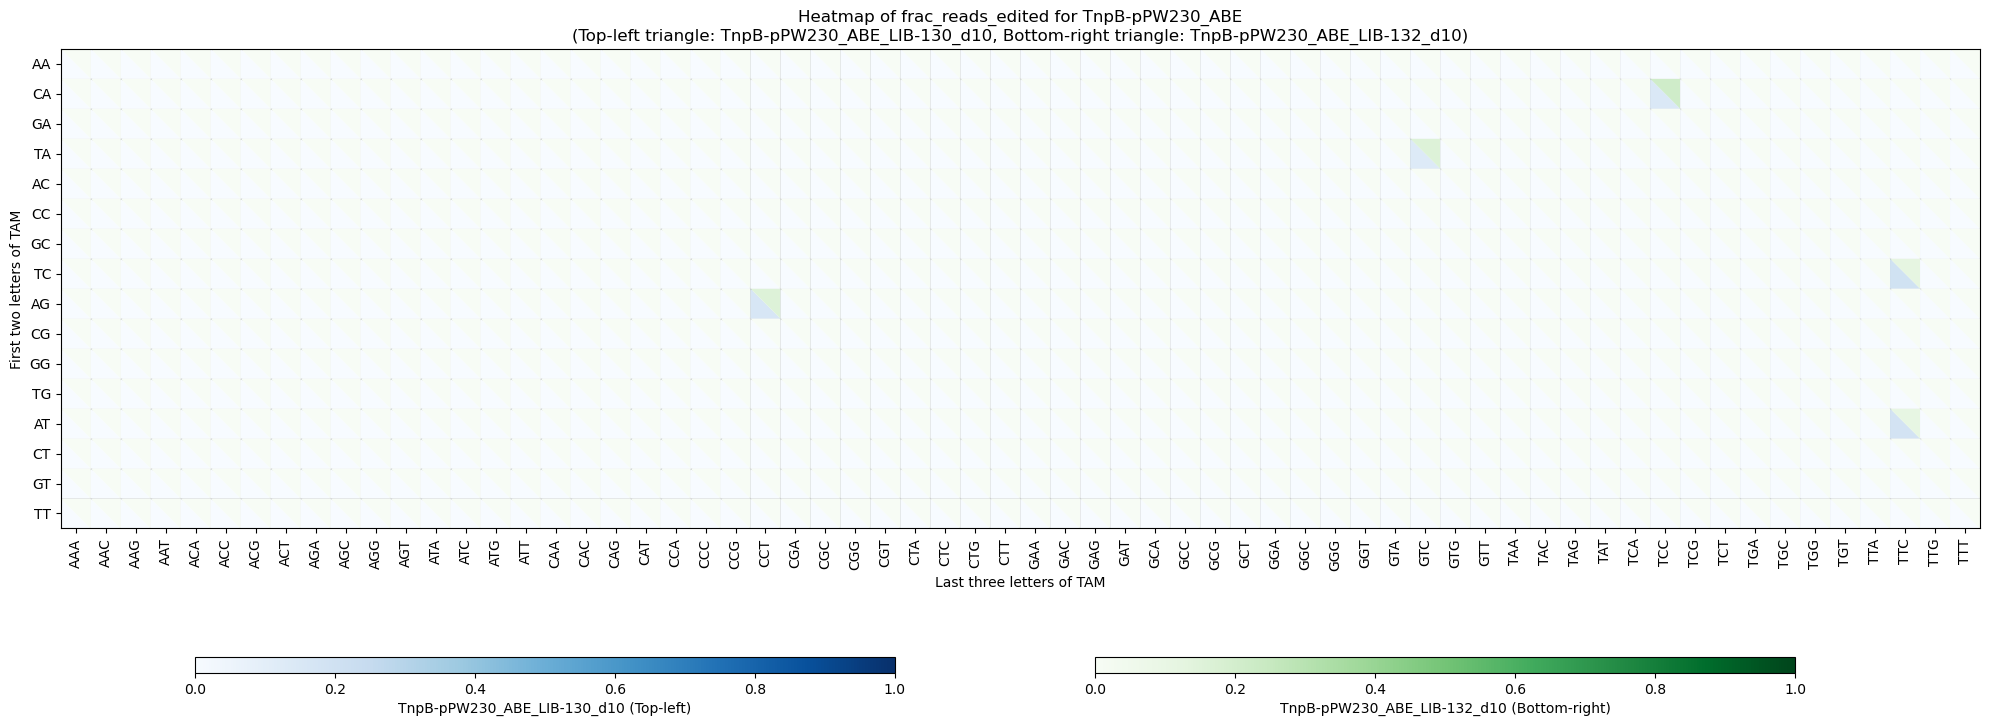

/tmp/ipykernel_1234884/3230753211.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


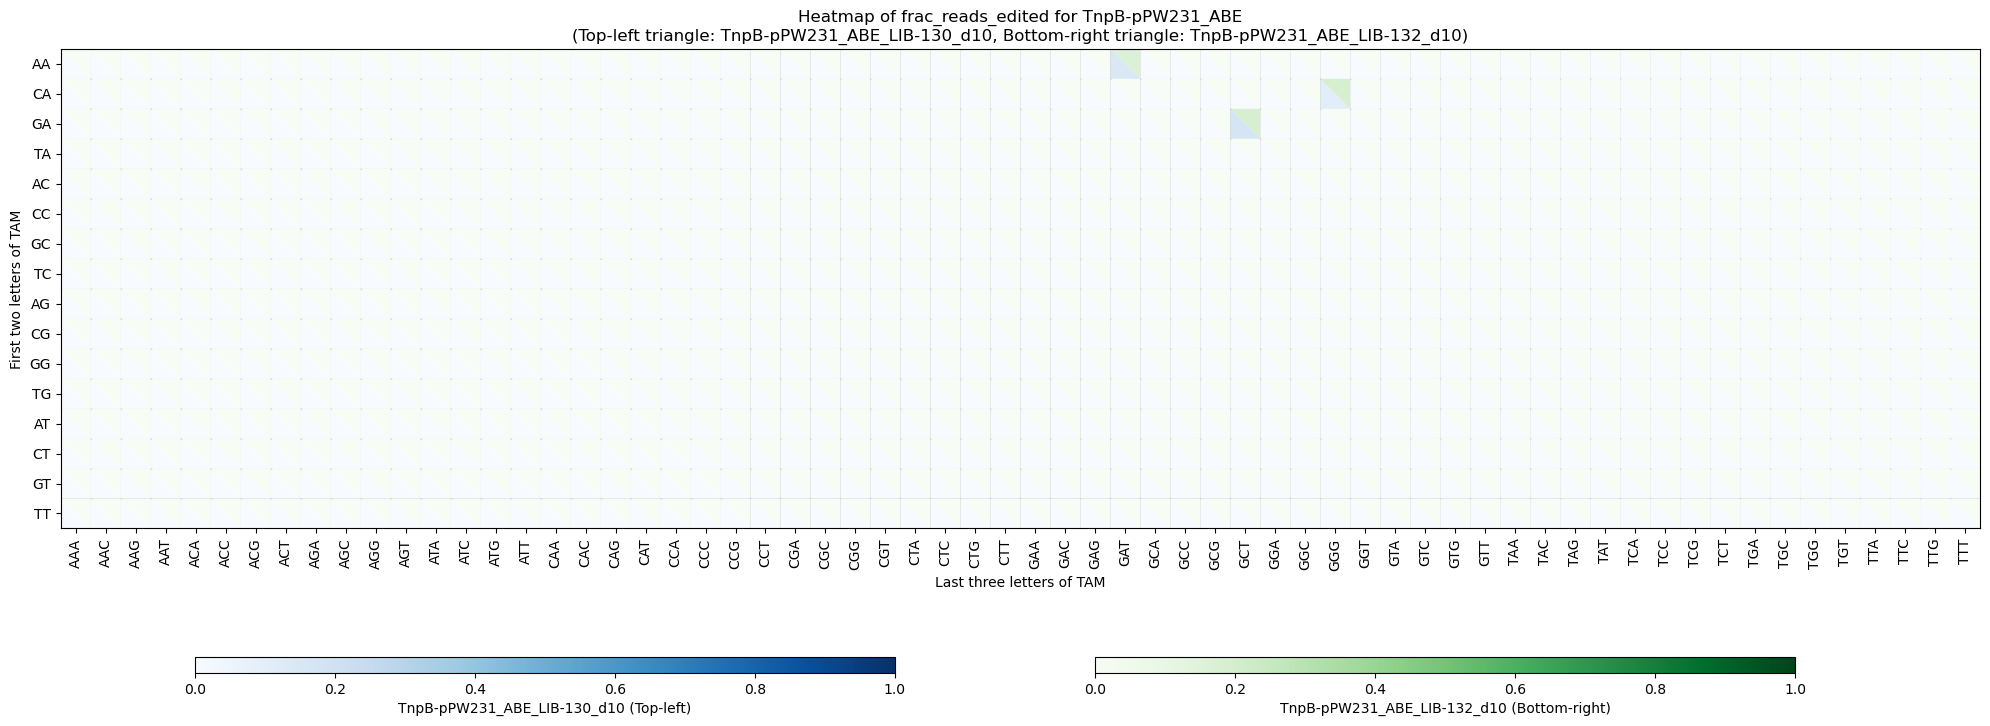

In [34]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
# Assuming config is imported elsewhere

def plot_heatmap_for_editor(mean_fracs, editor, vis_edit_thres=0.1, figsize=(20,8), cmap_upper="Blues", cmap_lower="Greens"):
    # Filter for the specified editor
    df = mean_fracs[mean_fracs["editor"] == editor].copy()
    bioreplicates = sorted(df["bioreplicate"].unique())
    if len(bioreplicates) != 2:
        raise ValueError(f"Expected exactly 2 bioreplicates for editor {editor}, found {len(bioreplicates)}")
    rep1, rep2 = bioreplicates

    # Process for rep1
    df1 = df[df["bioreplicate"] == rep1].copy()
    df1.loc[df1['frac_reads_edited'] < vis_edit_thres, 'frac_reads_edited'] = 0
    df1 = df1[['TAM', 'frac_reads_edited']].copy()
    missing_pams1 = set(config.PAMS) - set(df1["TAM"].unique())
    if missing_pams1:
        df_missing1 = pd.DataFrame({'TAM': list(missing_pams1), 'frac_reads_edited': 0})
        df1 = pd.concat([df1, df_missing1], ignore_index=True)
    df1["TAM_row"] = df1["TAM"].str[:2]
    df1["TAM_col"] = df1["TAM"].str[-3:]
    pivot1 = df1.pivot_table(index="TAM_row",
                             columns="TAM_col",
                             values="frac_reads_edited",
                             aggfunc="mean").fillna(0)
    pivot1 = pivot1.sort_index(ascending=False)

    # Process for rep2
    df2 = df[df["bioreplicate"] == rep2].copy()
    df2.loc[df2['frac_reads_edited'] < vis_edit_thres, 'frac_reads_edited'] = 0
    df2 = df2[['TAM', 'frac_reads_edited']].copy()
    missing_pams2 = set(config.PAMS) - set(df2["TAM"].unique())
    if missing_pams2:
        df_missing2 = pd.DataFrame({'TAM': list(missing_pams2), 'frac_reads_edited': 0})
        df2 = pd.concat([df2, df_missing2], ignore_index=True)
    df2["TAM_row"] = df2["TAM"].str[:2]
    df2["TAM_col"] = df2["TAM"].str[-3:]
    pivot2 = df2.pivot_table(index="TAM_row",
                             columns="TAM_col",
                             values="frac_reads_edited",
                             aggfunc="mean").fillna(0)
    pivot2 = pivot2.sort_index(ascending=False)

    # Get common rows and columns
    all_rows = sorted(pivot1.index.union(pivot2.index), key=lambda x: (x[1], x[0]))[::-1]
    all_cols = sorted(pivot1.columns.union(pivot2.columns))
    pivot1 = pivot1.reindex(index=all_rows, columns=all_cols).fillna(0)
    pivot2 = pivot2.reindex(index=all_rows, columns=all_cols).fillna(0)

    # here i want to cell a value in pivot1 and pivot2 to 0 if they not are both hight then vis_edit_thres
    mask = (pivot1 > vis_edit_thres) & (pivot2 > vis_edit_thres)
    pivot1 = pivot1.where(mask, 0)
    pivot2 = pivot2.where(mask, 0)

    nrows, ncols = len(all_rows), len(all_cols)

    # Create figure and axis
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, ncols)
    ax.set_ylim(nrows, 0)
    ax.set_aspect('equal')

    # Add gridlines first (behind patches)
    for j in range(ncols + 1):
        ax.axvline(j, color='black', linewidth=1, alpha=0.3, zorder=0)
    for i in range(nrows + 1):
        ax.axhline(i, color='black', linewidth=1, alpha=0.3, zorder=0)

    # Prepare colormaps and norms
    norm1 = Normalize(vmin=0, vmax=1)
    norm2 = Normalize(vmin=0, vmax=1)
    cmap1 = plt.colormaps[cmap_upper]
    cmap2 = plt.colormaps[cmap_lower]

    # Draw split triangles for each cell (on top of grid)
    for ii in range(nrows):
        y_top = nrows - ii
        y_bot = nrows - ii - 1
        for jj in range(ncols):
            x_left = jj
            x_right = jj + 1
            val1 = pivot1.iloc[ii, jj]
            val2 = pivot2.iloc[ii, jj]
            color1 = cmap1(norm1(val1))
            color2 = cmap2(norm2(val2))

            # Top-left triangle for rep1
            upper_verts = [(x_left, y_top), (x_right, y_top), (x_left, y_bot)]
            poly_upper = mpatches.Polygon(upper_verts, closed=True, facecolor=color1, edgecolor='none', zorder=1)
            ax.add_patch(poly_upper)

            # Bottom-right triangle for rep2
            lower_verts = [(x_right, y_top), (x_left, y_bot), (x_right, y_bot)]
            poly_lower = mpatches.Polygon(lower_verts, closed=True, facecolor=color2, edgecolor='none', zorder=1)
            ax.add_patch(poly_lower)

    # Set ticks and labels
    ax.set_xticks([j + 0.5 for j in range(ncols)])
    ax.set_xticklabels(all_cols, rotation=90)
    ytick_pos = [nrows - ii - 0.5 for ii in range(nrows)]
    ax.set_yticks(ytick_pos)
    ax.set_yticklabels(all_rows)

    plt.title(f"Heatmap of frac_reads_edited for {editor}\n(Top-left triangle: {rep1}, Bottom-right triangle: {rep2})")
    plt.ylabel("First two letters of TAM")
    plt.xlabel("Last three letters of TAM")

    # Adjust layout to make room for horizontal colorbars below
    plt.subplots_adjust(bottom=0.2)

    # Add horizontal colorbars below the plot
    cax1 = fig.add_axes([0.1, 0.02, 0.35, 0.02])
    sm1 = ScalarMappable(norm=norm1, cmap=cmap1)
    sm1.set_array([])
    cbar1 = fig.colorbar(sm1, cax=cax1, orientation='horizontal')
    cbar1.set_label(f"{rep1} (Top-left)")

    cax2 = fig.add_axes([0.55, 0.02, 0.35, 0.02])
    sm2 = ScalarMappable(norm=norm2, cmap=cmap2)
    sm2.set_array([])
    cbar2 = fig.colorbar(sm2, cax=cax2, orientation='horizontal')
    cbar2.set_label(f"{rep2} (Bottom-right)")

    plt.tight_layout()

    save_path = os.path.join(NAS_folder, f"heatmap_{editor}_{vis_edit_thres}.png")
    plt.savefig(save_path)
    plt.show()

# Updated loop over editors
vis_editors = sorted(mean_fracs.editor.unique())
for editor in vis_editors:
    plot_heatmap_for_editor(mean_fracs, editor, vis_edit_thres=0.1,
                            figsize=(20,8), cmap_upper="Blues", cmap_lower="Greens")

    